In [ ]:
import sys
import json
import calendar
import platform
import importlib.metadata
from typing import Any, Mapping
import matplotlib.pyplot as plt
from pathlib import Path
SRC_IMPORT_CANDIDATES = (Path.cwd() / "src", Path.cwd().parent / "src")
SRC_IMPORT_DIR = next((path for path in SRC_IMPORT_CANDIDATES if (path / "config.py").is_file()), None)
if SRC_IMPORT_DIR is None:
    raise FileNotFoundError("Could not locate src/config.py from the notebook working directory")
sys.path.insert(0, str(SRC_IMPORT_DIR))
from config import *

import numpy as np
import pandas as pd
from IPython.display import Image, display

RUN_HEAVY = False


def show_text(path, max_lines=None):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Expected saved report was not found: {path}")
    
    lines = path.read_text(encoding="utf-8").splitlines()
    if max_lines is not None and len(lines) > max_lines:
        print("\n".join(lines[:max_lines]))
        print(f"... ({len(lines) - max_lines} more lines; full report: {path})")
    else:
        print("\n".join(lines))


def show_img(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Expected figure was not found: {path}")
    display(Image(filename=str(path)))


SRC_DIR = PROJECT_ROOT / "src"
REPORT_ROOT = REPORTS_DIR
print(f"Project root: {PROJECT_ROOT}")
print(f"Heavy pipelines enabled: {RUN_HEAVY}")

Project root: C:\Users\ma007\OneDrive\Desktop\DSTT
Heavy pipelines enabled: False


# Electricity Bill Prediction and Energy Waste Detection

## Abstract

This project studies monthly household electricity-demand prediction and high-use waste detection in Pakistan.  
The dataset was changed from UCI to REWDP because local, multi-city Pakistani meter data paired with weather better matches the tiered-tariff problem.  
Minute-level household records are quality-checked, cleaned, and aggregated with city-level weather features.  
Cold-start and known-house models are compared using household-grouped CV, leave-one-city-out testing, and a one-time six-house holdout.  
Dev-only exploration, SHAP interpretation, and ablations explain model behavior.  
Waste detection is evaluated only with synthetic high-use injections; a Streamlit app presents estimates and advisory alerts.

*The proposal document was not present in the workspace; this abstract synthesizes the project artifacts and requested scope.*

## Problem statement

Households face tiered electricity rates but lack a practical way to estimate next-month use or identify unusually high use in weather context. This project tests locally grounded prediction and high-side alert methods while keeping dev houses separate from a small final holdout.

## Objectives

1. Inventory REWDP meter and weather files, schemas, and coverage.
2. Diagnose timestamp gaps, duplicates, missingness, zero runs, flatlines, outliers, drift, and weather alignment.
3. Clean minute data while distinguishing missing, outage, and valid measurements.
4. Construct daily/monthly tables, join weather, and create a deterministic house split.
5. Explore demand, weather, seasonality, household, solar, and high-use patterns.
6. Compare cold-start and known-house prediction using grouped and city holdouts.
7. Evaluate high-side alerts with synthetic injections and provide interpretable bill/waste interfaces.

## Research questions

- **RQ1:** How accurately can monthly household electricity use be predicted for new and known houses, and how does accuracy vary across cities?
- **RQ2:** How well do high-side anomaly detectors identify injected increases, and what false-alert trade-offs result?
- **RQ3:** Which feature groups/history improve prediction, and what flagged excess appears in dev house-months?

## Dataset description

The project contains **59 houses across six Pakistani cities** (Islamabad, Karachi, Lahore, Multan, Peshawar, Skardu). REWDP meter files are recorded at **one-minute kW resolution**; city weather inputs are hourly and are aligned/aggregated before joining to daily and monthly consumption. The saved daily table has 21,500 house-days from 2023-07-16 through 2024-11-28.

## Pipeline overview

| Stage | Name | Main artifact |
|---:|---|---|
| 1 | Problem understanding and data inspection | `data/raw` inventory and audit reports |
| 2 | Data quality checks | Missingness, duplicates, outage, timezone and alignment reports |
| 3 | Data cleaning | Flagged minute-level parquet and cleaning log |
| 4 | Daily dataset, weather join, and split | Daily/monthly parquet, split, coverage figure |
| 5 | Exploratory data analysis | Dev-only summaries and EDA figures |
| 6 | Feature engineering | Reusable monthly model table |
| 7 | Modeling and validation | GroupKFold, LOCO, holdout metrics and bundles |
| 8 | Explainability | Dev-only SHAP and Ridge coefficients |
| 9 | Ablation study | Feature, weather, target, threshold and model tables |
| 10 | Waste / anomaly detection | Synthetic-injection and dev OOF anomaly reports |
| 11 | Final evaluation | Holdout, LOCO and RQ verdicts |
| 12 | Streamlit app and deployment | Tariff demonstration and deployment checklist |

**How to read this notebook:** Work from Stage 1 through Stage 12. Each stage has its purpose/method, executable code, saved tables/figures or printed metrics, and an evidence-based summary. `RUN_HEAVY = False` loads saved outputs for cleaning, dataset building, modeling, ablations, and anomaly detection; change it only to intentionally recompute. The holdout is reserved for Stage 11.

## Stage 1: Problem understanding and data inspection

### Purpose and method
- Predict household electricity demand and identify unusually high-use or waste-like patterns.
- Inspect the six-city REWDP meter dataset alongside hourly weather observations.
- Use the existing audits to understand coverage and data quality before modeling.
- Inventory the unique meter files without rerunning heavyweight scans.

In [2]:
def list_project_data():
    """List configured data roots and the unique REWDP houses."""
    houses = list_house_files()
    counts = {city: sum(item["city"] == city for item in houses) for city in CITIES}
    print(f"REWDP folder: {REWDP_DIR}")
    print(f"Weather folder: {WEATHER_DIR}")
    print(f"Unique REWDP houses: {len(houses)}")
    display(pd.DataFrame({"city": list(counts), "houses": list(counts.values())}))
    return houses


def inspect_data_lightly():
    """Run only a lightweight directory/file inventory."""
    print("Data directories:")
    for path in (PROJECT_ROOT / "data", REWDP_DIR, WEATHER_DIR):
        print(f"  {path}: {'present' if path.is_dir() else 'missing'}")
    return list_project_data()


house_files = inspect_data_lightly()
show_text(REPORT_DIRS["understanding"] / "audit_digest.txt", max_lines=18)
show_text(REPORT_DIRS["understanding"] / "data_inspection.txt", max_lines=18)
# Inspect a sample file's actual column names and first records.
sample_path = house_files[0]["path"]
sample_head = pd.read_csv(sample_path, nrows=5)
print(f"Sample file: {sample_path}; columns: {sample_head.columns.tolist()}")
display(sample_head)

Data directories:
  C:\Users\ma007\OneDrive\Desktop\DSTT\data: present
  C:\Users\ma007\OneDrive\Desktop\DSTT\rewdp_dataset\rewdp_dataset: present
  C:\Users\ma007\OneDrive\Desktop\DSTT\weather_dataset\weather_dataset: present
REWDP folder: C:\Users\ma007\OneDrive\Desktop\DSTT\rewdp_dataset\rewdp_dataset
Weather folder: C:\Users\ma007\OneDrive\Desktop\DSTT\weather_dataset\weather_dataset
Unique REWDP houses: 59


,city,houses
0,Islamabad,10
1,Karachi,10
2,Lahore,10
3,Multan,10
4,Peshawar,10
5,Skardu,9


Electricity Bill Prediction and Waste Detection - Audit Digest

1. REWDP summary per city
  Islamabad: 10 houses; 2023-09-02 to 2024-10-31 23:59:00; median rows 524,370; min/max 402,965/525,644
  Karachi: 10 houses; 2023-09-02 12:07:00 to 2024-10-31 23:59:00; median rows 525,600; min/max 524,161/526,463
  Lahore: 10 houses; 2023-11-01 to 2024-11-19 21:59:00; median rows 525,600; min/max 469,149/533,512
  Multan: 10 houses; 2023-09-16 to 2024-11-06 10:00:00; median rows 525,600; min/max 524,161/601,441
  Peshawar: 10 houses; 2023-10-01 to 2024-10-30 23:59:00; median rows 525,600; min/max 305,281/525,600
  Skardu: 9 houses; 2023-07-16 to 2024-11-28 23:59:00; median rows 524,472; min/max 391,689/712,513

2. Files with missing timestamps > 1%
  Lahore House1: missing 10.74%; longest gap 43,558 min
  Lahore House3: missing 3.52%; longest gap 15 min
  Lahore House7: missing 5.53%; longest gap 28,792 min
  Skardu House52: missing 18.37%; longest gap 95,041 min
  Skardu House53: missing 34.76%

,datetime,Usage (kW)
0,2023-11-01,0.63
1,2023-11-01 00:01:00,0.64
2,2023-11-01 00:02:00,0.63
3,2023-11-01 00:03:00,0.63
4,2023-11-01 00:04:00,0.52


### Stage 1 summary

- **Done:** inventoried the project datasets and inspected saved REWDP and weather audits.
- **Key numbers:** 59 houses: 10 in each of five cities and 9 in Skardu; six city-level weather archives.
- **Decision:** retain REWDP instead of the earlier UCI proposal dataset because local meter/weather data fits the Pakistani tiered-tariff question.
- **Issues and limitations:** the original proposal was not in the workspace; this notebook's framing is grounded in the saved project artifacts and supplied requirements.

## Stage 2: Data quality checks

### Purpose and method
- Check timestamp completeness, missing-value patterns, zero runs, flatlines, outliers, drift, timezone, and meter/weather alignment.
- Preserve the original raw CSVs; make timestamp repairs only in the cleaning output.
- Resolve duplicate-time blocks before building the minute grid; keep reports for traceability.

| Check | Finding from saved reports | Decision |
|---|---|---|
| Missing timestamps / long gaps | Skardu House53 has 185,111 expected timestamps missing; long gaps also affect Skardu52/56 and Lahore1. | Retain gaps explicitly and flag missing intervals rather than inventing measurements. |
| Zero runs / flatlines / outliers | Peshawar House30 has a 102,176-minute zero run; Skardu House53 has 29 long flatlines; no negative usage was reported. | Apply documented zero-run, flatline, and spike rules in the cleaner. |
| Timezones and weather coverage | Weather timestamps are timezone-naive; city weather reports show no missing hourly timestamps. | Use the project datetime parser and hourly weather timeline. |
| Meter/weather alignment | Best lag is -1 hour for Islamabad, Karachi, Lahore, Multan, and Peshawar; +2 hours for Skardu. | Keep meter timestamps unchanged; treat lag as a modeling caveat. |
| Duplicate timestamps and repair | Raw duplicate blocks occur in Skardu58 and Karachi38; the cleaned parquet check reports 0/59 files with duplicated datetimes. | Repair before reindexing and verify unique cleaned timestamps. |

REWDP quality summary - worst offenders by category

Dtype / sentinel / non-numeric issues
  Lahore House8: non-float=['datetime']; non-numeric={}; sentinels={'Generation (KW)': {'-1': 1}}
  Islamabad House41: non-float=['datetime']; non-numeric={}; sentinels={}
  Islamabad House42: non-float=['datetime']; non-numeric={}; sentinels={}
  Islamabad House43: non-float=['datetime']; non-numeric={}; sentinels={}
  Islamabad House44: non-float=['datetime']; non-numeric={}; sentinels={}

Timezone-aware datetime samples
  none

Missing timestamp count
  Skardu House53: missing 185,111
  Skardu House56: missing 104,676
  Skardu House52: missing 96,542
  Lahore House1: missing 56,451
  Lahore House7: missing 29,135

Longest individual timestamp gaps
  Skardu House52: 2024-04-17T23:59:00+00:00 to 2024-06-23T00:00:00+00:00 (95,041 min; 95,040 missing)
  Skardu House56: 2023-12-05T23:59:00+00:00 to 2024-02-05T00:00:00+00:00 (87,841 min; 87,840 missing)
  Lahore House1: 2024-05-27T18:02:00+00:00 to 

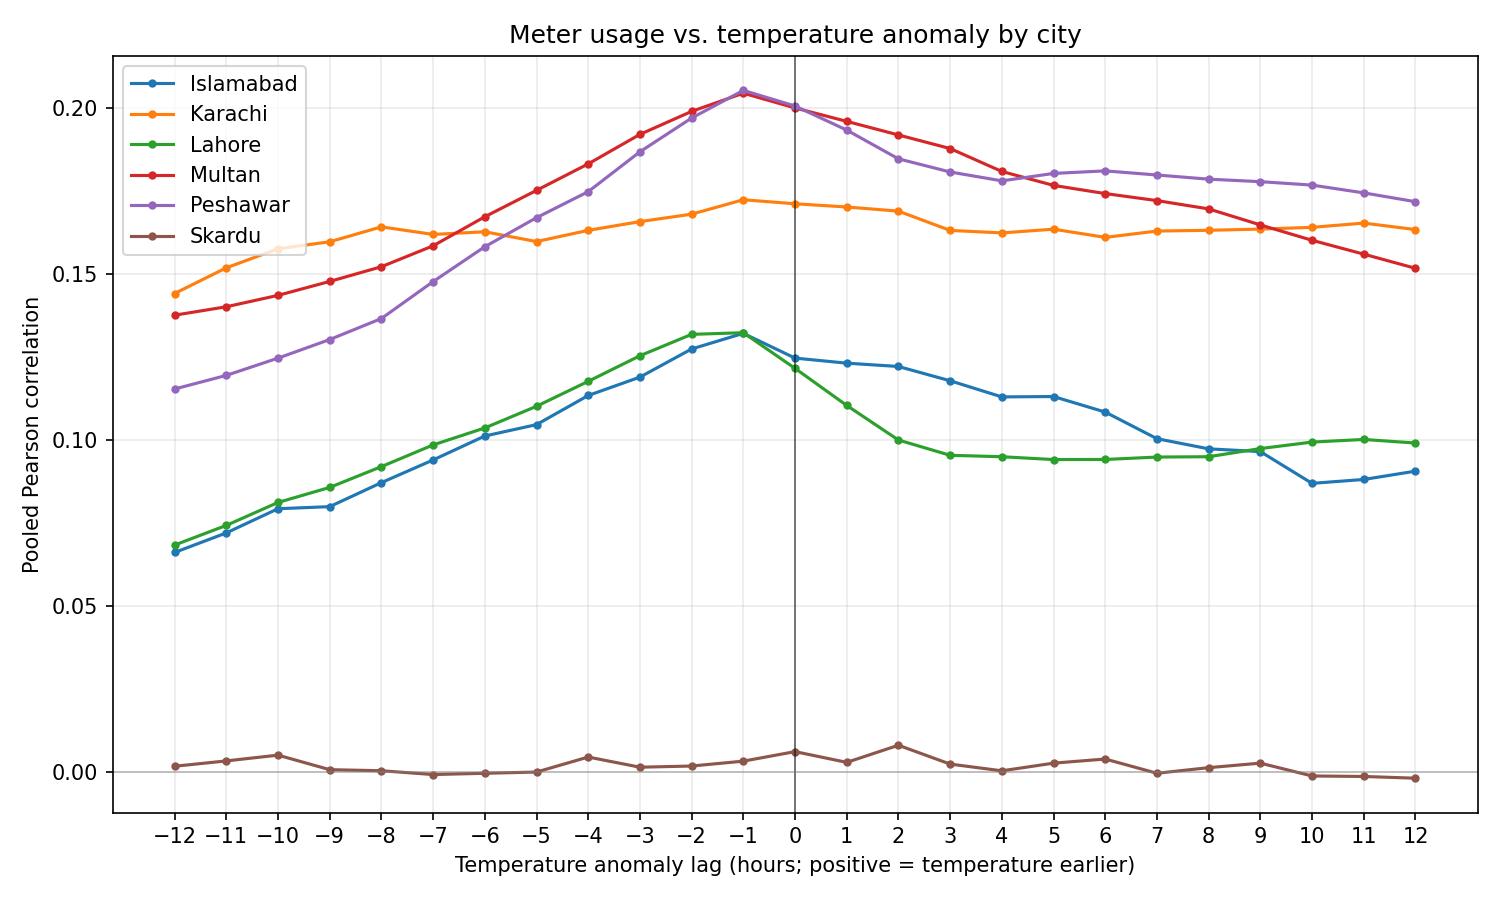

Top ten houses by missing timestamps:


,city,house_id,missing_timestamp_count,duplicate_timestamp_rows,longest_zero_run_minutes,longest_flatline_minutes,drift_unexplained
52,Skardu,53,185111,177003,13356,323,False
55,Skardu,56,104676,0,720,168,True
51,Skardu,52,96542,0,1027,60,True
20,Lahore,1,56451,0,0,60,False
26,Lahore,7,29135,0,121,0,False
58,Skardu,59,24582,1299,578,87,False
56,Skardu,57,21415,0,4320,0,True
22,Lahore,3,18532,1,0,0,False
50,Skardu,51,6047,0,508,171,False
48,Peshawar,29,4137,0,57,0,False


In [3]:
def run_alignment_check():
    """Run the existing full alignment check only when explicitly enabled."""
    import runpy
    runpy.run_path(str(SRC_DIR / "helpers" / "check_alignment.py"), run_name="__main__")


def run_duplicate_check():
    """Run the existing full duplicate audit only when explicitly enabled."""
    import runpy
    runpy.run_path(str(SRC_DIR / "helpers" / "check_duplicates.py"), run_name="__main__")


def duplicate_timestamp_summary(timestamps):
    """Count duplicate timestamps without changing the source series."""
    counts = pd.Series(timestamps).value_counts()
    return {"duplicate_rows": int(counts[counts.gt(1)].sum()),
            "duplicate_timestamps": int(counts[counts.gt(1)].size)}


def alignment_lag_correlations(usage_anomaly, temperature_anomaly, lags=range(-12, 13)):
    """Correlate aligned hourly anomalies; positive lag shifts weather earlier."""
    joined = pd.concat([usage_anomaly.rename("usage"),
                        temperature_anomaly.rename("temperature")], axis=1)
    return {lag: joined["usage"].corr(joined["temperature"].shift(lag))
            for lag in lags}


if RUN_HEAVY:
    run_alignment_check()
    run_duplicate_check()
else:
    show_text(REPORT_DIRS["quality"] / "quality_summary.txt", max_lines=32)
    show_text(REPORT_DIRS["quality"] / "weather_quality.txt", max_lines=12)
    show_text(REPORT_DIRS["quality"] / "alignment_check.txt", max_lines=32)
    show_text(REPORT_DIRS["quality"] / "duplicate_check.txt", max_lines=18)
    show_text(REPORT_DIRS["quality"] / "repair_check.txt")
    show_img(REPORT_DIRS["quality"] / "figures" / "alignment_lag_curves.png")
quality_per_house = pd.read_csv(REPORT_DIRS["quality"] / "quality_per_house.csv")
quality_cols = [c for c in ["city", "house_id", "missing_timestamp_count", "duplicate_timestamp_rows",
                             "longest_zero_run_minutes", "longest_flatline_minutes", "drift_unexplained"]
                if c in quality_per_house.columns]
print("Top ten houses by missing timestamps:")
display(quality_per_house.sort_values("missing_timestamp_count", ascending=False)[quality_cols].head(10))

### Stage 2 summary

- **Done:** reviewed missing timestamps, duplicates, zero runs, flatlines, outliers, drift, timezone, weather and alignment reports.
- **Key numbers:** maximum missing timestamps: 185,111 (Skardu House53); longest gap: 95,041 minutes (Skardu House52); longest zero run: 102,176 minutes (Peshawar House30).
- **Decision:** preserve distinct quality flags and do not infer consumption across long outages/offline spans.
- **Issues and limitations:** quality thresholds were selected after inspection of all houses; two Lahore solar meters have alignment uncertainty.

## Stage 3: Data cleaning

### Purpose and method
- Convert each household source into a sorted, unique, complete minute grid while leaving raw data unchanged.
- Preserve measurement flags for valid, interpolated, missing, offline-zero, stuck-sensor, and spike minutes.
- Repair large duplicate groups by restoring minute timestamps and average small duplicate groups.
- Keep long missing spans unfilled; Lahore House8's identified duplicate window remains explicitly missing.

In [4]:
if RUN_HEAVY:
# Full implementation embedded from clean_data.py.
    """Clean household minute-level data into parquet files without changing raw data."""

    import sys
    from pathlib import Path

    import json
    import re
    from typing import Any

    import numpy as np
    import pandas as pd

    from config import INTERIM_DIR, REPORT_DIRS, list_house_files, parse_dt


    DATETIME_COLUMN = "datetime"
    USAGE_COLUMN = "Usage (kW)"
    FLAG_LABELS = {
        0: "valid_original",
        1: "interpolated",
        2: "missing",
        3: "offline_zero_removed",
        4: "stuck_removed",
        5: "spike_removed",
    }
    SENTINELS = (-999, 9999)
    OFFLINE_RUN_MINUTES = 2880
    OUTAGE_RUN_MINUTES = 30
    STUCK_RUN_MINUTES = 180
    SPIKE_LIMIT_KW = 5.0
    MAX_USAGE_KW = 25.0
    MAX_INTERPOLATION_MINUTES = 15


    def normalize_column_name(column: object) -> str:
        name = str(column).strip().replace("(KW)", "(kW)")
        name = re.sub(r"\s+", " ", name)
        return name


    def normalized_key(column: object) -> str:
        return re.sub(r"[^a-z0-9]", "", str(column).casefold())


    def find_column(columns: list[str], expected: str) -> str | None:
        expected_key = normalized_key(expected)
        return next(
            (column for column in columns if normalized_key(column) == expected_key),
            None,
        )


    def contiguous_runs(mask: np.ndarray) -> list[tuple[int, int]]:
        active = np.asarray(mask, dtype=bool)
        if not active.any():
            return []
        starts = np.flatnonzero(active & ~np.r_[False, active[:-1]])
        ends = np.flatnonzero(active & ~np.r_[active[1:], False])
        return [(int(start), int(end) + 1) for start, end in zip(starts, ends, strict=True)]


    def identical_value_runs(values: np.ndarray, eligible: np.ndarray) -> list[tuple[int, int]]:
        eligible = np.asarray(eligible, dtype=bool)
        if not eligible.any():
            return []
        previous_equal = np.zeros(len(values), dtype=bool)
        if len(values) > 1:
            previous_equal[1:] = (
                eligible[1:]
                & eligible[:-1]
                & (values[1:] == values[:-1])
            )
        starts = np.flatnonzero(eligible & ~previous_equal)
        next_equal = np.zeros(len(values), dtype=bool)
        if len(values) > 1:
            next_equal[:-1] = previous_equal[1:]
        ends = np.flatnonzero(eligible & ~next_equal) + 1
        return [
            (int(start), int(end))
            for start, end in zip(starts, ends, strict=True)
        ]


    def as_numeric_float32(values: pd.Series) -> pd.Series:
        return pd.to_numeric(values, errors="coerce").astype("float32")


    def aggregate_duplicate_timestamps(
        source: pd.DataFrame,
        datetime_column: str,
    ) -> pd.DataFrame:
        numeric_columns = [
            column
            for column in source.columns
            if column != datetime_column
            and pd.api.types.is_numeric_dtype(source[column])
        ]
        aggregations = {
            column: ("mean" if column in numeric_columns else "first")
            for column in source.columns
            if column != datetime_column
        }
        return (
            source.groupby(datetime_column, sort=False, as_index=False)
            .agg(aggregations)
        )


    def repair_timestamps(
        source: pd.DataFrame,
        datetime_column: str,
        city: str,
        house_id: int,
    ) -> tuple[pd.DataFrame, dict[str, Any]]:
        source = source.copy()
        counts = source.groupby(datetime_column, sort=False)[datetime_column].transform(
            "size"
        )
        hour_floored_mask = counts >= 30
        small_duplicate_mask = (counts >= 2) & (counts <= 29)
        small_duplicate_group_count = int(
            source.loc[small_duplicate_mask, datetime_column].nunique()
        )
        hour_floored_groups = (
            source.loc[hour_floored_mask, datetime_column]
            .value_counts(sort=False)
            .sort_index()
        )
        irregular_groups = [
            (timestamp, int(size))
            for timestamp, size in hour_floored_groups.items()
            if size != 60
        ]
        for timestamp, size in irregular_groups:
            print(
                f"Timestamp repair size != 60: {city} House{house_id} "
                f"{timestamp} ({size} rows)"
            )

        occurrences = source.groupby(datetime_column, sort=False).cumcount()
        source[datetime_column] = source[datetime_column] + pd.to_timedelta(
            occurrences.where(hour_floored_mask, 0),
            unit="min",
        )

        rows_restored = int(
            sum(int(size) - 1 for size in hour_floored_groups.to_numpy())
        )
        repaired_counts = source.groupby(datetime_column, sort=False)[
            datetime_column
        ].transform("size")
        small_times = source.loc[
            repaired_counts.between(2, 29), datetime_column
        ].drop_duplicates()
        if not small_times.empty:
            small_mask = source[datetime_column].isin(small_times)
            small_rows = aggregate_duplicate_timestamps(
                source.loc[small_mask],
                datetime_column,
            )
            source = pd.concat(
                [source.loc[~small_mask], small_rows],
                ignore_index=True,
            )

        remaining_mask = source[datetime_column].duplicated(keep=False)
        remaining_duplicate_groups = int(
            source.loc[remaining_mask, datetime_column].nunique()
        )
        if remaining_duplicate_groups:
            duplicate_times = (
                source.loc[remaining_mask, datetime_column]
                .drop_duplicates()
                .sort_values()
            )
            print(
                f"Duplicates remaining after timestamp repair: {city} House{house_id}: "
                f"{remaining_duplicate_groups} groups; resolving by numeric mean"
            )
            for timestamp in duplicate_times:
                print(f"  {timestamp}")

        source = aggregate_duplicate_timestamps(source, datetime_column)
        if source[datetime_column].duplicated().any():
            remaining = source.loc[
                source[datetime_column].duplicated(keep=False), datetime_column
            ]
            print(
                f"Unresolved duplicate timestamps for {city} House{house_id}: "
                f"{remaining.tolist()}"
            )
            raise AssertionError(
                f"Timestamp repair left duplicate timestamps for {city} House{house_id}"
            )

        return source, {
            "hour_floored_groups_repaired": int(len(hour_floored_groups)),
            "rows_restored": rows_restored,
            "groups_with_size_not_60": len(irregular_groups),
            "small_duplicate_groups_averaged": small_duplicate_group_count,
            "duplicates_remaining_after_repair": int(
                source[datetime_column].duplicated().sum()
            ),
        }


    def clean_house(house: dict[str, Any], minute_dir: Path) -> dict[str, Any]:
        path = Path(house["path"])
        city = str(house["city"])
        house_id = int(house["house_id"])
        source = pd.read_csv(path)
        rows_in = len(source)

        renamed = [normalize_column_name(column) for column in source.columns]
        if len(set(renamed)) != len(renamed):
            raise ValueError(f"Column name normalization creates duplicate columns in {path}")
        source.columns = renamed
        missing_pct_before_fill = {
            str(column): float(source[column].isna().mean() * 100.0)
            for column in source.columns
        }
        datetime_column = find_column(list(source.columns), DATETIME_COLUMN)
        usage_column = find_column(list(source.columns), USAGE_COLUMN)
        if datetime_column is None or usage_column is None:
            raise ValueError(f"{path} must contain datetime and {USAGE_COLUMN!r} columns")

        source[datetime_column] = parse_dt(source[datetime_column])
        source = source.dropna(subset=[datetime_column]).reset_index(drop=True)
        if source.empty:
            raise ValueError(f"{path} has no valid timestamps")
        source, timestamp_repair = repair_timestamps(
            source,
            datetime_column,
            city,
            house_id,
        )
        source = source.sort_values(datetime_column, kind="stable").set_index(datetime_column)
        if source.empty:
            raise ValueError(f"{path} has no valid timestamps")

        generation_columns = [
            str(column)
            for column in source.columns
            if "generation" in str(column).casefold()
        ]
        if len(generation_columns) > 1:
            raise ValueError(f"{path} has multiple generation columns: {generation_columns}")
        has_solar = bool(generation_columns)
        solar_kw: pd.Series | None = None
        if has_solar:
            generation = pd.to_numeric(source[generation_columns[0]], errors="coerce")
            solar_kw = (-generation).clip(lower=0).astype("float32")
            source = source.drop(columns=generation_columns)

        submeter_columns = [
            str(column)
            for column in source.columns
            if column != usage_column
        ]
        minute_index = pd.date_range(
            start=source.index.min(),
            end=source.index.max(),
            freq="1min",
            name=DATETIME_COLUMN,
        )
        source = source.reindex(minute_index)
        if solar_kw is not None:
            solar_kw = solar_kw.reindex(minute_index).astype("float32")

        usage = as_numeric_float32(source[usage_column])
        submeter_data: dict[str, pd.Series] = {}
        for column in submeter_columns:
            values = as_numeric_float32(source[column])
            values = values.mask(values.lt(0) | values.isin(SENTINELS))
            submeter_data[column] = values

        special_missing_mask = np.zeros(len(minute_index), dtype=bool)
        if city == "Lahore" and house_id == 8:
            special_start = pd.Timestamp("2024-06-28 00:00:00")
            special_end = pd.Timestamp("2024-07-03 12:01:00")
            special_missing_mask = (
                (minute_index >= special_start) & (minute_index <= special_end)
            )
            usage = usage.mask(special_missing_mask)
            for column in submeter_data:
                submeter_data[column] = submeter_data[column].mask(
                    special_missing_mask
                )
            if solar_kw is not None:
                solar_kw = solar_kw.mask(special_missing_mask).astype("float32")

        usage = usage.mask(usage.lt(0) | usage.isin(SENTINELS))
        flags = np.zeros(len(minute_index), dtype=np.int8)
        initially_missing = usage.isna().to_numpy()
        flags[initially_missing] = 2
        flags[special_missing_mask] = 2
        usage_values = usage.to_numpy(dtype=np.float32, na_value=np.nan, copy=True)
        outage = np.zeros(len(minute_index), dtype=bool)

        zero_runs = contiguous_runs(np.isfinite(usage_values) & (usage_values == 0))
        offline_runs: list[dict[str, Any]] = []
        for start, end in zero_runs:
            length = end - start
            if length >= OFFLINE_RUN_MINUTES:
                usage_values[start:end] = np.nan
                flags[start:end] = 3
                offline_runs.append(
                    {
                        "start": minute_index[start],
                        "minutes": length,
                        "days": length / 1440,
                    }
                )
            elif length >= OUTAGE_RUN_MINUTES:
                outage[start:end] = True

        stuck_eligible = np.isfinite(usage_values) & (usage_values >= 0.02)
        stuck_runs = [
            (start, end)
            for start, end in identical_value_runs(usage_values, stuck_eligible)
            if end - start >= STUCK_RUN_MINUTES
        ]
        for start, end in stuck_runs:
            usage_values[start:end] = np.nan
            flags[start:end] = 4

        spike_candidates = np.zeros(len(usage_values), dtype=bool)
        if len(usage_values) > 2:
            previous = usage_values[:-2]
            current = usage_values[1:-1]
            following = usage_values[2:]
            valid_neighbors = np.isfinite(previous) & np.isfinite(current) & np.isfinite(following)
            spike_candidates[1:-1] = (
                valid_neighbors
                & (np.abs(current - (previous + following) / 2) > SPIKE_LIMIT_KW)
                & (np.abs(previous - following) < 1.0)
            )
        high_usage = np.isfinite(usage_values) & (usage_values > MAX_USAGE_KW)
        spike_candidates |= high_usage
        usage_values[spike_candidates] = np.nan
        flags[spike_candidates] = 5

        usage_missing_pct_before_fill = float(np.isnan(usage_values).mean() * 100.0)
        missing_runs = contiguous_runs((flags == 2) & np.isnan(usage_values))
        for start, end in missing_runs:
            length = end - start
            if (
                length > MAX_INTERPOLATION_MINUTES
                or start == 0
                or not np.isfinite(usage_values[start - 1])
            ):
                continue
            # Causal forward-fill: never inspect the later endpoint of a gap.
            usage_values[start:end] = float(usage_values[start - 1])
            flags[start:end] = 1

        usage_clean = pd.Series(usage_values, index=minute_index, dtype="float32")
        submeter_frame = pd.DataFrame(submeter_data, index=minute_index, dtype="float32")

        if submeter_columns:
            all_submeters_valid = submeter_frame.notna().all(axis=1)
            comparable = usage_clean.notna() & all_submeters_valid
            if comparable.any():
                submeter_sum = submeter_frame.sum(axis=1, min_count=len(submeter_columns))
                inconsistent = submeter_sum.gt(1.1 * usage_clean + 0.01) & comparable
                inconsistent_pct = float(inconsistent.sum() / comparable.sum() * 100)
            else:
                inconsistent_pct = float("nan")
            submeters_consistent = bool(
                np.isnan(inconsistent_pct) or inconsistent_pct < 10
            )
        else:
            inconsistent_pct = float("nan")
            submeters_consistent = True

        output = pd.DataFrame(
            {
                "datetime": minute_index,
                "usage_kw": usage_clean.astype("float32"),
                "flag": flags.astype("int8"),
                "outage": outage,
            }
        )
        if solar_kw is not None:
            output["solar_kw"] = solar_kw.astype("float32")
        for column in submeter_columns:
            output[column] = submeter_frame[column].astype("float32")

        output_path = minute_dir / f"{city}_{house_id}.parquet"
        output.to_parquet(output_path, index=False)

        flag_minutes = {
            f"minutes_flag_{flag}": int(np.count_nonzero(flags == flag))
            for flag in range(6)
        }
        valid_pct = float(np.isin(flags, (0, 1)).mean() * 100)
        return {
            "city": city,
            "house_id": house_id,
            "rows_in": rows_in,
            "rows_out": len(output),
            "missing_pct_before_fill": json.dumps(missing_pct_before_fill, sort_keys=True),
            "usage_missing_pct_before_fill": usage_missing_pct_before_fill,
            **flag_minutes,
            "valid_pct": valid_pct,
            "outage_minutes": int(outage.sum()),
            "offline_zero_runs_removed": json.dumps(
                [round(run["days"], 6) for run in offline_runs]
            ),
            "_offline_zero_run_details": json.dumps(
                [
                    {
                        "start": run["start"].isoformat(),
                        "days": round(run["days"], 6),
                    }
                    for run in offline_runs
                ]
            ),
            "_timestamp_repair": timestamp_repair,
            "_lahore_8_minutes_set_nan": int(special_missing_mask.sum()),
            "stuck_runs_removed": len(stuck_runs),
            "submeter_inconsistent_pct": inconsistent_pct,
            "submeters_consistent": submeters_consistent,
            "has_solar": has_solar,
        }


    def build_summary(log: pd.DataFrame, records: list[dict[str, Any]]) -> str:
        lines = ["Data cleaning summary", "", "Totals per city"]
        if log.empty:
            lines.append("  none")
        else:
            city_totals = (
                log.groupby("city")
                .agg(
                    houses=("house_id", "count"),
                    rows_in=("rows_in", "sum"),
                    rows_out=("rows_out", "sum"),
                    valid_pct=("valid_pct", "mean"),
                    outage_minutes=("outage_minutes", "sum"),
                    offline_minutes=("minutes_flag_3", "sum"),
                    stuck_minutes=("minutes_flag_4", "sum"),
                    spike_minutes=("minutes_flag_5", "sum"),
                    interpolated_minutes=("minutes_flag_1", "sum"),
                    missing_minutes=("minutes_flag_2", "sum"),
                )
                .sort_index()
            )
            lines.append(
                "  city | houses | rows_in | rows_out | mean_valid_pct | outages | "
                "offline | stuck | spikes | interpolated | missing"
            )
            for city, row in city_totals.iterrows():
                lines.append(
                    f"  {city} | {int(row['houses'])} | {int(row['rows_in'])} | "
                    f"{int(row['rows_out'])} | {row['valid_pct']:.2f}% | "
                    f"{int(row['outage_minutes'])} | {int(row['offline_minutes'])} | "
                    f"{int(row['stuck_minutes'])} | {int(row['spike_minutes'])} | "
                    f"{int(row['interpolated_minutes'])} | {int(row['missing_minutes'])}"
                )

        lines.extend(["", "10 houses with the lowest valid_pct"])
        lowest = log.sort_values("valid_pct", ascending=True).head(10)
        if lowest.empty:
            lines.append("  none")
        else:
            for row in lowest.itertuples(index=False):
                lines.append(
                    f"  {row.city} House{row.house_id}: {row.valid_pct:.2f}% "
                    f"({row.minutes_flag_0 + row.minutes_flag_1:,}/{row.rows_out:,} valid)"
                )

        lines.extend(["", "Offline zero runs removed"])
        offline_entries: list[tuple[str, int, str, float]] = []
        for row in records:
            for run in json.loads(row["_offline_zero_run_details"]):
                offline_entries.append(
                    (
                        str(row["city"]),
                        int(row["house_id"]),
                        run["start"],
                        float(run["days"]),
                    )
                )
        if not offline_entries:
            lines.append("  none")
        else:
            for city, house_id, start, days in sorted(offline_entries):
                lines.append(
                    f"  {city} House{house_id}: start {start}; length {days:.6f} days"
                )

        lines.extend(["", "Minutes affected by rule across the whole dataset"])
        lines.append("  flag | rule | minutes")
        for flag, label in FLAG_LABELS.items():
            total = int(log[f"minutes_flag_{flag}"].sum()) if not log.empty else 0
            lines.append(f"  {flag} | {label} | {total:,}")
        lines.append(
            f"  outage | short zero runs >= {OUTAGE_RUN_MINUTES} and < "
            f"{OFFLINE_RUN_MINUTES} minutes | {int(log['outage_minutes'].sum()) if not log.empty else 0:,}"
        )
        lines.extend(["", "Timestamp repairs"])
        repair_records = []
        for record in records:
            repair = record["_timestamp_repair"]
            special_minutes = int(record["_lahore_8_minutes_set_nan"])
            if (
                repair["hour_floored_groups_repaired"]
                or repair["small_duplicate_groups_averaged"]
                or special_minutes
            ):
                repair_records.append((record, repair, special_minutes))
        if not repair_records:
            lines.append("  none")
        else:
            for record, repair, special_minutes in sorted(
                repair_records,
                key=lambda item: (item[0]["city"], item[0]["house_id"]),
            ):
                line = (
                    f"  {record['city']} House{record['house_id']}: "
                    f"hour-floored groups repaired="
                    f"{repair['hour_floored_groups_repaired']}, "
                    f"rows restored={repair['rows_restored']}, "
                    f"groups with size != 60={repair['groups_with_size_not_60']}, "
                    f"small duplicate groups averaged="
                    f"{repair['small_duplicate_groups_averaged']}, "
                    f"duplicates remaining after repair="
                    f"{repair['duplicates_remaining_after_repair']}"
                )
                if special_minutes:
                    line += f", Lahore 8 minutes set to NaN={special_minutes}"
                lines.append(line)
        return "\n".join(lines) + "\n"


    def main() -> None:
        houses = list_house_files()
        if len(houses) != 59:
            print(f"Processing {len(houses)} unique house files (expected 59).")

        minute_dir = INTERIM_DIR / "minute"
        minute_dir.mkdir(parents=True, exist_ok=True)
        report_dir = REPORT_DIRS["cleaning"]
        report_dir.mkdir(parents=True, exist_ok=True)
        records: list[dict[str, Any]] = []
        for index, house in enumerate(houses, start=1):
            record = clean_house(house, minute_dir)
            records.append(record)
            print(
                f"[{index}/{len(houses)}] {record['city']} House{record['house_id']}: "
                f"{record['rows_in']:,} -> {record['rows_out']:,} rows, "
                f"{record['valid_pct']:.2f}% valid"
            )

        log = pd.DataFrame(
            [
                {key: value for key, value in record.items() if not key.startswith("_")}
                for record in records
            ]
        ).sort_values(["city", "house_id"])
        log_path = report_dir / "cleaning_log.csv"
        log.to_csv(log_path, index=False)

        summary = build_summary(log, records)
        summary_path = report_dir / "cleaning_summary.txt"
        summary_path.write_text(summary, encoding="utf-8")
        print(summary, end="")
        print(f"Parquet directory: {minute_dir}")
        print(f"Cleaning log: {log_path}")
        print(f"Cleaning summary: {summary_path}")
        print(summary[summary.index("Timestamp repairs"):], end="")


    if __name__ == "__main__":
        main()
else:
    show_text(REPORT_DIRS["cleaning"] / "cleaning_summary.txt", max_lines=42)
cleaning_log = pd.read_csv(REPORT_DIRS["cleaning"] / "cleaning_log.csv")
print("Cleaning log by valid percentage:")
display(cleaning_log.sort_values("valid_pct").reset_index(drop=True))

Data cleaning summary

Totals per city
  city | houses | rows_in | rows_out | mean_valid_pct | outages | offline | stuck | spikes | interpolated | missing
  Islamabad | 10 | 5104627 | 5116211 | 94.14% | 139543 | 137879 | 0 | 13 | 9148 | 168134
  Karachi | 10 | 5254489 | 5233972 | 99.81% | 4610 | 0 | 0 | 0 | 1580 | 9888
  Lahore | 10 | 5127995 | 5225639 | 94.61% | 47113 | 18932 | 0 | 480 | 81720 | 264325
  Multan | 10 | 5330402 | 5331481 | 97.32% | 4156 | 6773 | 0 | 7 | 1 | 136424
  Peshawar | 10 | 5027469 | 5035681 | 94.67% | 4146 | 266866 | 0 | 0 | 0 | 13055
  Skardu | 9 | 4862080 | 5003694 | 93.38% | 296390 | 49850 | 0 | 62 | 781 | 266627

10 houses with the lowest valid_pct
  Peshawar House30: 73.76% (387,678/525,600 valid)
  Lahore House7: 76.41% (402,701/527,039 valid)
  Islamabad House45: 79.07% (415,569/525,600 valid)
  Skardu House56: 80.10% (420,982/525,600 valid)
  Skardu House52: 81.63% (429,060/525,601 valid)
  Islamabad House41: 84.90% (446,258/525,600 valid)
  Lahore Hous

,city,house_id,rows_in,rows_out,minutes_flag_0,minutes_flag_1,minutes_flag_2,minutes_flag_3,minutes_flag_4,minutes_flag_5,valid_pct,outage_minutes,offline_zero_runs_removed,stuck_runs_removed,submeter_inconsistent_pct,submeters_consistent,has_solar
0,Peshawar,30,521525,525600,387678,0,4075,133847,0,0,73.759132,181,"[21.99375, 70.955556]",0,0.000000,True,False
1,Lahore,7,497904,527039,358491,44210,124338,0,0,0,76.408197,2708,[],0,0.000000,True,False
2,Islamabad,45,525600,525600,406427,9142,110031,0,0,0,79.065639,0,[],0,0.784226,True,False
3,Skardu,56,420924,525600,420924,58,104618,0,0,0,80.095510,1747,[],0,NaN,True,False
4,Skardu,52,429059,525601,429059,1,96541,0,0,0,81.632265,2829,[],0,0.000000,True,False
5,Islamabad,41,525600,525600,446258,0,0,79333,0,9,84.904490,132122,"[4.352083, 8.618056, 6.125, 2.479861, 20.98541...",0,NaN,True,False
6,Lahore,5,525600,525600,444391,18959,62250,0,0,0,88.156393,0,[],0,0.000000,True,False
7,Islamabad,50,507006,507006,448456,0,0,58546,0,4,88.451813,4970,"[31.457639, 2.163889, 7.035417]",0,0.000000,True,False
8,Multan,19,525600,525600,468627,0,56972,0,0,1,89.160388,0,[],0,0.131021,True,False
9,Lahore,1,469149,525600,469149,9,56442,0,0,0,89.261416,0,[],0,1.264630,True,False


### Per-house missingness and chronological imputation

The cleaner processes one house at a time in timestamp order. Its short-gap fill is now causal forward-fill, and its cleaning log records source missingness percentages before any fill. The reusable helper below also requires a split/partition column and fills only within each house and partition, so no value crosses a temporal or household split. It is applied only to weather predictors here; missing consumption targets remain missing.

In [5]:
def impute_per_house_chronologically(
    frame, value_columns, time_column, split_column,
    house_columns=("city", "house_id"), max_ffill=15,
):
    """Log per-house missingness then causally forward-fill within split partitions."""
    required = [*house_columns, split_column, time_column, *value_columns]
    missing = [column for column in required if column not in frame.columns]
    if missing:
        raise KeyError(f"Missing columns required for per-house imputation: {missing}")
    ordered = frame.copy()
    ordered[time_column] = pd.to_datetime(ordered[time_column], errors="raise")
    keys = [*house_columns, split_column]
    ordered = ordered.sort_values([*house_columns, time_column, split_column], kind="stable").reset_index(drop=True)
    logs = []
    for key, group in ordered.groupby(keys, sort=False, dropna=False):
        key_values = key if isinstance(key, tuple) else (key,)
        key_record = dict(zip(keys, key_values))
        for column in value_columns:
            logs.append({
                **key_record,
                "feature": column,
                "rows": int(len(group)),
                "missing_before_pct": float(group[column].isna().mean() * 100.0),
                "missing_before_count": int(group[column].isna().sum()),
            })
    # Grouping by split label prevents fill state from crossing a train/test boundary.
    ordered[value_columns] = ordered.groupby(keys, sort=False, dropna=False)[value_columns].ffill(limit=max_ffill)
    return ordered, pd.DataFrame(logs)


# Audit per-house weather missingness on the saved daily table; never fill target kWh.
daily_for_imputation = pd.read_parquet(PROCESSED_DIR / "daily.parquet")
house_roles = pd.read_csv(PROCESSED_DIR / "house_split.csv", usecols=["city", "house_id", "role"])
daily_for_imputation = daily_for_imputation.merge(
    house_roles, on=["city", "house_id"], how="left", validate="many_to_one"
)
weather_impute_columns = [
    "temp_mean", "temp_max", "temp_min", "humidity_mean", "dew_mean",
    "precip_sum", "wind_mean", "pressure_mean", "solar_rad_mean", "cdd", "hdd",
]
daily_weather_filled, missingness_before_fill = impute_per_house_chronologically(
    daily_for_imputation, weather_impute_columns,
    time_column="date", split_column="role", max_ffill=3,
)
print("Per-house weather missingness before causal fill (top rows):")
display(missingness_before_fill.sort_values("missing_before_pct", ascending=False).head(12))
print("Targets left unchanged: daily kWh missing rows =", int(daily_for_imputation["kwh"].isna().sum()))

Per-house weather missingness before causal fill (top rows):


,city,house_id,role,feature,rows,missing_before_pct,missing_before_count
648,Skardu,59,holdout,hdd,367,0.0,0
0,Islamabad,41,holdout,temp_mean,365,0.0,0
1,Islamabad,41,holdout,temp_max,365,0.0,0
2,Islamabad,41,holdout,temp_min,365,0.0,0
3,Islamabad,41,holdout,humidity_mean,365,0.0,0
4,Islamabad,41,holdout,dew_mean,365,0.0,0
5,Islamabad,41,holdout,precip_sum,365,0.0,0
6,Islamabad,41,holdout,wind_mean,365,0.0,0
7,Islamabad,41,holdout,pressure_mean,365,0.0,0
609,Skardu,56,dev,dew_mean,365,0.0,0


Targets left unchanged: daily kWh missing rows = 1185


### Stage 3 summary

- **Done:** embedded the complete cleaner behind `RUN_HEAVY` and display the saved house-level log by default.
- **Key numbers:** 59 houses were processed; saved city mean-valid percentages span about 93.38% (Skardu) to 99.81% (Karachi).
- **Decision:** retain quality flags and keep outages/offline zeros distinct from normal use; do not interpolate long missing spans.
- **Issues and limitations:** cleaning thresholds were selected after full-dataset inspection; heavy minute transformations were not rerun here.
- **Imputation update:** source missingness is logged per house; short-gap filling is now causal forward-fill and never reads the later endpoint.

## Stage 4: Daily dataset, weather join, and train/holdout split

### Purpose and method
- Aggregate valid meter minutes to daily statistics and join city-level daily weather.
- Require at least 90% daily minute coverage for a usable day; keep unusable days in the daily dataset.
- Split one eligible full-tier, non-solar household per city into the final holdout.
- **Leakage note:** learned preprocessing is fitted inside each validation fold; holdout houses are not used for model or feature choices.

Daily dataset summary
Total rows: 21,500
Number of houses: 59
Date range: 2023-07-16 to 2024-11-28
Usable days overall: 20,315 (94.49%)
Usable days per city (count, percent)
  Islamabad: 3,287 / 3,555 (92.46%)
  Karachi: 3,624 / 3,637 (99.64%)
  Lahore: 3,277 / 3,629 (90.30%)
  Multan: 3,593 / 3,703 (97.03%)
  Peshawar: 3,301 / 3,498 (94.37%)
  Skardu: 3,233 / 3,478 (92.96%)
Houses with at least 300 usable days (50): Islamabad House41, Islamabad House42, Islamabad House43, Islamabad House44, Islamabad House46, Islamabad House48, Islamabad House49, Islamabad House50, Karachi House31, Karachi House32, Karachi House33, Karachi House34, Karachi House35, Karachi House36, Karachi House37, Karachi House38, Karachi House39, Karachi House40, Lahore House1, Lahore House2, Lahore House3, Lahore House4, Lahore House6, Lahore House8, Lahore House9, Lahore House10, Multan House11, Multan House12, Multan House13, Multan House14, Multan House15, Multan House16, Multan House17, Multan House18, Multan H

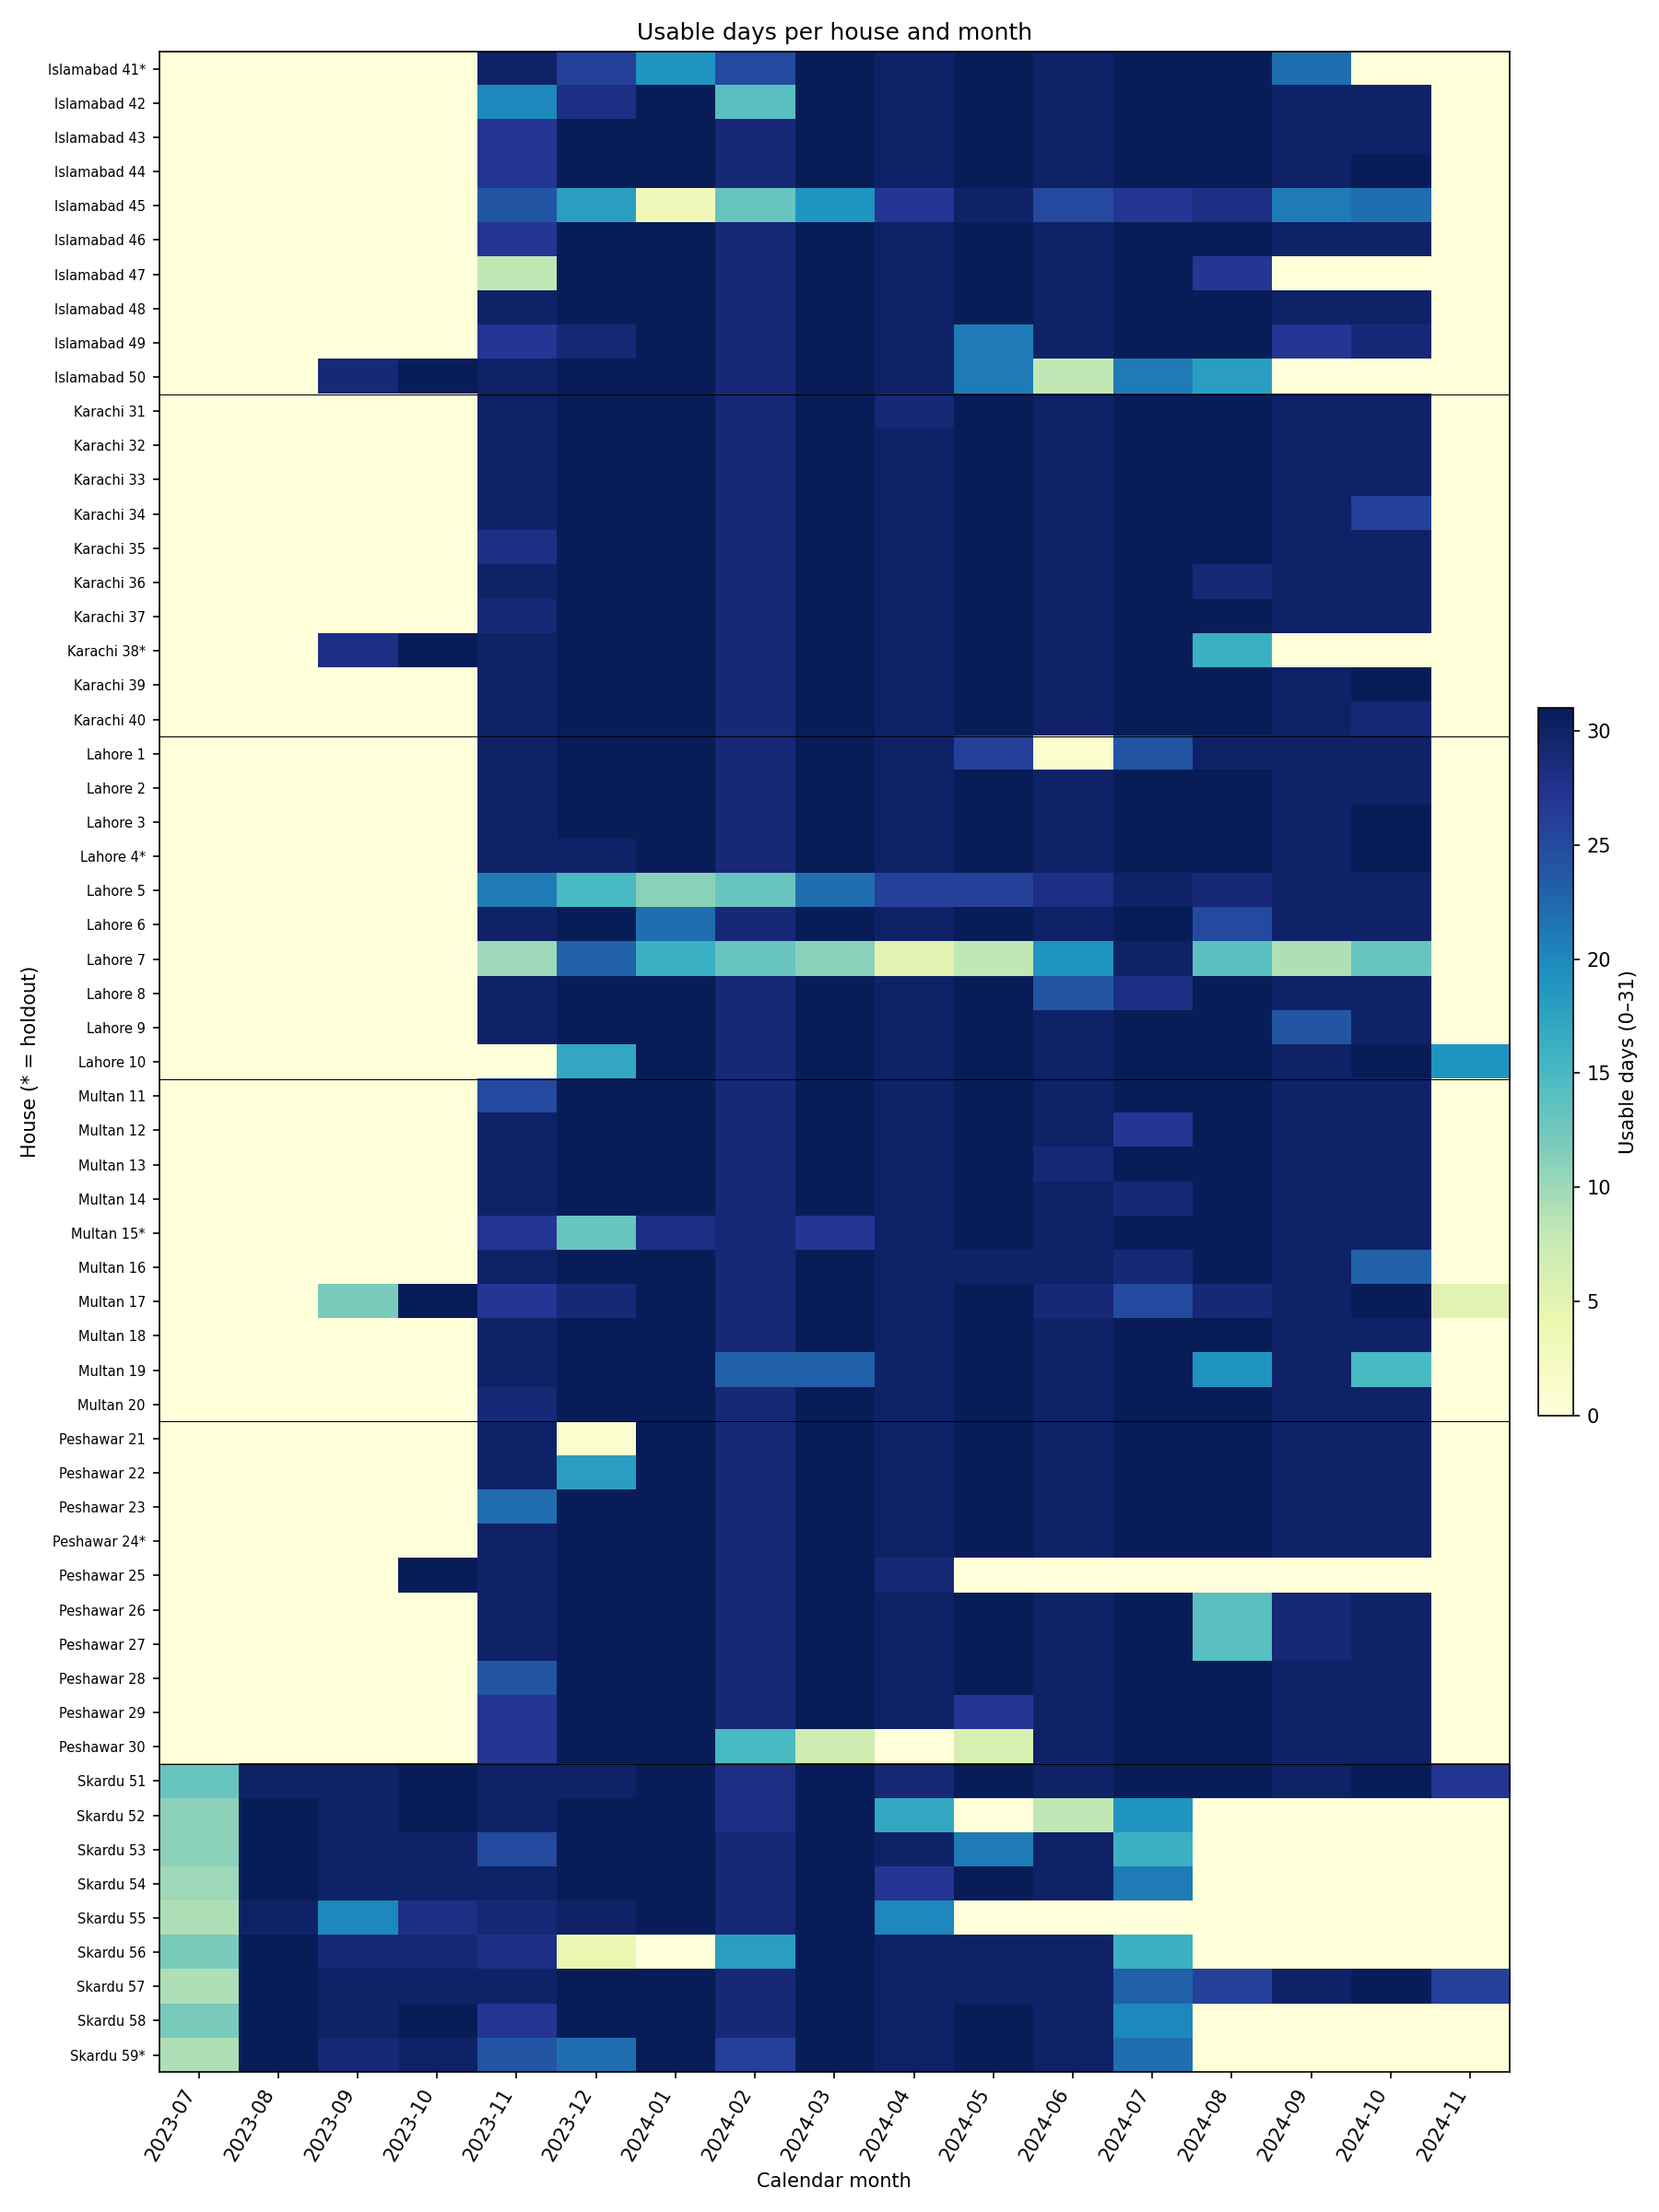

Saved split assignments:


,city,house_id,usable_days,has_solar,months_ge20,first_usable,last_usable,tier,role
0,Islamabad,41,306,False,10,2023-11-01,2024-09-26,full,holdout
1,Islamabad,42,337,False,11,2023-11-01,2024-10-30,full,dev
2,Islamabad,43,362,False,12,2023-11-01,2024-10-30,full,dev
3,Islamabad,44,363,False,12,2023-11-01,2024-10-31,full,dev
4,Islamabad,45,257,False,8,2023-11-01,2024-10-30,partial,dev
5,Islamabad,46,362,False,12,2023-11-01,2024-10-30,full,dev
6,Islamabad,47,279,False,9,2023-11-23,2024-08-27,partial,dev
7,Islamabad,48,365,False,12,2023-11-01,2024-10-30,full,dev
8,Islamabad,49,346,False,12,2023-11-01,2024-10-30,full,dev
9,Islamabad,50,310,False,10,2023-09-02,2024-08-18,full,dev


Saved daily table head:


,date,n_valid_min,mean_kw,max_kw,std_kw,night_mean_kw,day_mean_kw,outage_min,coverage,usable,...,wind_mean,pressure_mean,solar_rad_mean,solar_energy_sum,uv_max,cdd,hdd,dow,month,day_of_year
0,2023-11-01,1440,0.344153,1.41,0.257866,0.561104,0.235677,313,1.0,True,...,7.616667,1018.424988,151.004166,13.0,7.0,0.0,0.0,2,11,305
1,2023-11-02,1440,0.491708,3.80,0.155192,0.543771,0.465677,0,1.0,True,...,4.720833,1016.562500,165.195831,14.2,7.0,0.0,0.0,3,11,306
2,2023-11-03,1440,0.487778,2.84,0.171124,0.564062,0.449635,0,1.0,True,...,5.650000,1013.524963,173.904175,15.0,7.0,0.0,0.0,4,11,307
3,2023-11-04,1440,0.456514,4.53,0.256503,0.541875,0.413833,142,1.0,True,...,5.491667,1014.308350,171.891663,14.8,7.0,0.0,0.0,5,11,308
4,2023-11-05,1440,0.452069,3.08,0.173655,0.537604,0.409302,0,1.0,True,...,4.620833,1015.170837,173.462509,15.0,7.0,0.0,0.0,6,11,309


Saved monthly table head:


,city,house_id,role,year_month,n_usable_days,days_in_month,mean_daily_kwh,monthly_kwh,temp_mean,cdd_sum,hdd_sum,humidity_mean,precip_sum,solar_rad_mean
0,Islamabad,41,holdout,2023-11,30,30,14.290344,428.710327,16.661806,0.0,50.012501,66.324127,83.999001,141.411392
1,Islamabad,41,holdout,2023-12,26,31,8.926069,276.708147,12.316936,0.0,176.175003,66.242775,0.985000,127.231316
2,Islamabad,41,holdout,2024-01,19,31,22.512421,697.885040,9.904704,0.0,250.954163,72.338768,23.767000,126.104027
3,Islamabad,41,holdout,2024-02,25,29,20.046494,581.348312,12.459052,0.0,160.687500,61.149601,59.598000,164.152161
4,Islamabad,41,holdout,2024-03,31,31,21.481771,665.934916,17.297716,0.0,53.250000,63.906857,207.369003,198.018021


In [6]:
if RUN_HEAVY:
    # Build daily/monthly products and the whole-house split from cleaned data.
    """Build daily household and weather features from the interim minute data."""

    import sys
    from pathlib import Path

    import numpy as np
    import pandas as pd

    from config import CITIES, INTERIM_DIR, PROCESSED_DIR, REPORT_DIRS, WEATHER_DIR, parse_dt


    MINUTE_COLUMNS = ["datetime", "usage_kw", "flag", "outage"]
    WEATHER_COLUMNS = {
        "Temperature": "temp",
        "Humidity": "humidity",
        "Dew": "dew",
        "Precipitation": "precip",
        "Wind Speed": "wind",
        "Pressure": "pressure",
        "Solar Radiation": "solar_rad",
        "Solar Energy": "solar_energy",
        "UV Index": "uv",
    }


    def load_house_daily(path: Path, city: str, house_id: int) -> pd.DataFrame:
        columns = pd.read_parquet(path).columns.tolist()
        required = set(MINUTE_COLUMNS)
        if not required.issubset(columns):
            raise ValueError(f"{path} is missing required columns: {sorted(required - set(columns))}")
        solar_present = "solar_kw" in columns
        requested = MINUTE_COLUMNS + (["solar_kw"] if solar_present else [])
        frame = pd.read_parquet(path, columns=requested)
        frame["datetime"] = pd.to_datetime(frame["datetime"])
        frame = frame.sort_values("datetime", kind="stable")
        frame["date"] = frame["datetime"].dt.normalize()
        frame["hour"] = frame["datetime"].dt.hour
        valid = frame["flag"].isin([0, 1]) & frame["usage_kw"].notna()
        frame["_valid_usage"] = frame["usage_kw"].where(valid)
        frame["_night_usage"] = frame["_valid_usage"].where(
            frame["hour"].isin([22, 23, 0, 1, 2, 3, 4, 5])
        )
        frame["_day_usage"] = frame["_valid_usage"].where(frame["hour"].between(6, 21))
        frame["_valid_min"] = valid.astype("int32")
        frame["_outage_min"] = frame["outage"].fillna(False).astype(bool).astype("int32")
        if solar_present:
            frame["_solar_valid"] = frame["solar_kw"].where(valid)

        daily = (
            frame.groupby("date", sort=True)
            .agg(
                n_valid_min=("_valid_min", "sum"),
                mean_kw=("_valid_usage", "mean"),
                max_kw=("_valid_usage", "max"),
                std_kw=("_valid_usage", "std"),
                night_mean_kw=("_night_usage", "mean"),
                night_valid_min=("_night_usage", "count"),
                day_mean_kw=("_day_usage", "mean"),
                day_valid_min=("_day_usage", "count"),
                outage_min=("_outage_min", "sum"),
            )
            .reset_index()
        )
        daily["coverage"] = daily["n_valid_min"] / 1440
        daily["usable"] = daily["coverage"] >= 0.9
        daily["kwh"] = (daily["mean_kw"] * 24).where(daily["usable"])
        daily["night_mean_kw"] = daily["night_mean_kw"].where(
            daily["night_valid_min"] >= 60
        )
        daily["day_mean_kw"] = daily["day_mean_kw"].where(daily["day_valid_min"] >= 60)
        if solar_present:
            solar_sum = (
                frame.groupby("date", sort=True)["_solar_valid"]
                .sum(min_count=1)
                .div(60)
                .rename("solar_kwh")
            )
            daily = daily.merge(solar_sum, on="date", how="left", validate="one_to_one")
        else:
            daily["solar_kwh"] = np.nan
        daily["city"] = city
        daily["house_id"] = int(house_id)
        daily["has_solar"] = solar_present
        return daily.drop(columns=["night_valid_min", "day_valid_min"])


    def find_weather_column(columns: list[str], expected: str) -> str:
        def key(value: object) -> str:
            return "".join(character.casefold() for character in str(value) if character.isalnum())

        match = next((column for column in columns if key(column) == key(expected)), None)
        if match is None:
            raise ValueError(f"Weather data is missing required column {expected!r}")
        return match


    def load_weather_daily(city: str) -> tuple[pd.DataFrame, int]:
        path = WEATHER_DIR / f"{city}.csv"
        weather = pd.read_csv(path)
        datetime_column = find_weather_column(list(weather.columns), "datetime")
        weather[datetime_column] = parse_dt(weather[datetime_column])
        weather = weather.dropna(subset=[datetime_column]).sort_values(
            datetime_column, kind="stable"
        )
        rename: dict[str, str] = {}
        for expected, short_name in WEATHER_COLUMNS.items():
            column = find_weather_column(list(weather.columns), expected)
            weather[column] = pd.to_numeric(weather[column], errors="coerce").astype(
                "float32"
            )
            rename[column] = short_name
        weather = weather.rename(columns=rename)
        clipped_count = int((weather["precip"] > 100).sum())
        weather["precip"] = weather["precip"].clip(upper=100).astype("float32")
        weather["date"] = weather[datetime_column].dt.normalize()
        daily = (
            weather.groupby("date", sort=True)
            .agg(
                temp_mean=("temp", "mean"),
                temp_max=("temp", "max"),
                temp_min=("temp", "min"),
                humidity_mean=("humidity", "mean"),
                dew_mean=("dew", "mean"),
                precip_sum=("precip", "sum"),
                wind_mean=("wind", "mean"),
                pressure_mean=("pressure", "mean"),
                solar_rad_mean=("solar_rad", "mean"),
                solar_energy_sum=("solar_energy", "sum"),
                uv_max=("uv", "max"),
            )
            .reset_index()
        )
        daily["cdd"] = (daily["temp_mean"] - 24).clip(lower=0)
        daily["hdd"] = (18 - daily["temp_mean"]).clip(lower=0)
        return daily, clipped_count


    def build_summary(daily: pd.DataFrame, clipped: dict[str, int]) -> str:
        lines = [
            "Daily dataset summary",
            f"Total rows: {len(daily):,}",
            f"Number of houses: {daily[['city', 'house_id']].drop_duplicates().shape[0]}",
        ]
        if daily.empty:
            lines.append("Date range: none")
            lines.append("Usable days overall: 0 (0.00%)")
            return "\n".join(lines) + "\n"

        lines.append(f"Date range: {daily['date'].min().date()} to {daily['date'].max().date()}")
        usable_count = int(daily["usable"].sum())
        lines.append(
            f"Usable days overall: {usable_count:,} "
            f"({usable_count / len(daily) * 100:.2f}%)"
        )
        lines.append("Usable days per city (count, percent)")
        for city in CITIES:
            city_rows = daily.loc[daily["city"] == city]
            count = int(city_rows["usable"].sum())
            pct = count / len(city_rows) * 100 if len(city_rows) else 0.0
            lines.append(f"  {city}: {count:,} / {len(city_rows):,} ({pct:.2f}%)")

        usable_per_house = daily.groupby(
            ["city", "house_id"],
            observed=True,
        )["usable"].sum()
        high = [f"{city} House{house_id}" for (city, house_id), n in usable_per_house.items() if n >= 300]
        low = [f"{city} House{house_id}" for (city, house_id), n in usable_per_house.items() if n < 120]
        lines.append(f"Houses with at least 300 usable days ({len(high)}): {', '.join(high) if high else 'none'}")
        lines.append(f"Houses with fewer than 120 usable days ({len(low)}): {', '.join(low) if low else 'none'}")

        lines.append("Usable-day kwh by city (mean, median)")
        for city in CITIES:
            values = daily.loc[(daily["city"] == city) & daily["usable"], "kwh"]
            if values.empty:
                lines.append(f"  {city}: none")
            else:
                lines.append(f"  {city}: {values.mean():.3f}, {values.median():.3f}")

        missing_weather = int(daily["temp_mean"].isna().sum())
        lines.append(f"Daily rows missing weather: {missing_weather:,}")
        lines.append("Five highest usable kwh days")
        top = daily.loc[daily["usable"]].nlargest(5, "kwh")
        if top.empty:
            lines.append("  none")
        else:
            for row in top.itertuples(index=False):
                lines.append(
                    f"  {row.city} House{row.house_id}, {row.date.date()}, {row.kwh:.3f} kWh"
                )
        lines.append("Hourly precipitation values clipped at 100 per city")
        for city in CITIES:
            lines.append(f"  {city}: {clipped.get(city, 0):,}")
        return "\n".join(lines) + "\n"


    def main() -> None:
        minute_dir = INTERIM_DIR / "minute"
        parquet_paths = sorted(minute_dir.glob("*.parquet"))
        if not parquet_paths:
            raise FileNotFoundError(f"No minute parquet files found in {minute_dir}")

        house_frames = []
        for path in parquet_paths:
            stem = path.stem
            city, separator, house_text = stem.rpartition("_")
            if not separator or city not in CITIES or not house_text.isdigit():
                raise ValueError(f"Unexpected minute parquet filename: {path.name}")
            house_frames.append(load_house_daily(path, city, int(house_text)))
        daily = pd.concat(house_frames, ignore_index=True)

        clipped: dict[str, int] = {}
        weather_frames = []
        for city in CITIES:
            city_weather, clipped_count = load_weather_daily(city)
            clipped[city] = clipped_count
            print(f"{city}: clipped {clipped_count} hourly precipitation values above 100")
            city_weather["city"] = city
            weather_frames.append(city_weather)
        weather = pd.concat(weather_frames, ignore_index=True)
        daily = daily.merge(weather, on=["city", "date"], how="left", validate="many_to_one")
        daily["dow"] = daily["date"].dt.dayofweek.astype("int8")
        daily["month"] = daily["date"].dt.month.astype("int8")
        daily["day_of_year"] = daily["date"].dt.dayofyear.astype("int16")
        daily["house_id"] = daily["house_id"].astype("int64")
        daily["city"] = daily["city"].astype("category")
        daily = daily.sort_values(["city", "house_id", "date"]).reset_index(drop=True)

        PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
        report_dir = REPORT_DIRS["daily"]
        report_dir.mkdir(parents=True, exist_ok=True)
        output_path = PROCESSED_DIR / "daily.parquet"
        daily.to_parquet(output_path, index=False)
        summary = build_summary(daily, clipped)
        summary_path = report_dir / "daily_summary.txt"
        summary_path.write_text(summary, encoding="utf-8")
        print(summary, end="")
        print(f"Daily parquet: {output_path}")
        print(f"Daily summary: {summary_path}")


    if __name__ == "__main__":
        main()
    import sys
    from pathlib import Path
    try:
        from config import PROCESSED_DIR, REPORT_DIRS, CITIES, RANDOM_SEED
    except ImportError as error:
        if "REPORT_DIRS" in str(error):
            raise ImportError(
                "src/config.py must define REPORT_DIRS before make_split.py can run"
            ) from error
        raise

    import calendar

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from matplotlib.colors import Normalize


    INPUT_PATH = PROCESSED_DIR / "daily.parquet"
    REQUIRED_COLUMNS = {
        "city",
        "house_id",
        "date",
        "usable",
        "kwh",
        "has_solar",
        "temp_mean",
        "cdd",
        "hdd",
        "humidity_mean",
        "precip_sum",
        "solar_rad_mean",
    }
    WEATHER_COLUMNS = [
        "temp_mean",
        "cdd",
        "hdd",
        "humidity_mean",
        "precip_sum",
        "solar_rad_mean",
    ]
    HEATMAP_MONTHS = pd.period_range("2023-07", "2024-11", freq="M")


    def build_house_table(daily: pd.DataFrame) -> pd.DataFrame:
        usable = daily.loc[daily["_usable"]].copy()
        usable["year_month"] = usable["date"].dt.to_period("M")
        months_ge20 = (
            usable.groupby(["city", "house_id", "year_month"], observed=True)
            .size()
            .ge(20)
            .groupby(level=["city", "house_id"], observed=True)
            .sum()
            .rename("months_ge20")
        )
        house_table = (
            daily.groupby(["city", "house_id"], observed=True, sort=False)
            .agg(
                usable_days=("_usable", "sum"),
                has_solar=("has_solar", "first"),
            )
            .join(months_ge20, how="left")
            .reset_index()
        )
        usable_dates = (
            usable.groupby(["city", "house_id"], observed=True)["date"]
            .agg(first_usable="min", last_usable="max")
            .reset_index()
        )
        house_table = house_table.merge(
            usable_dates,
            on=["city", "house_id"],
            how="left",
            validate="one_to_one",
        )
        house_table["months_ge20"] = house_table["months_ge20"].fillna(0).astype(int)
        house_table["usable_days"] = house_table["usable_days"].astype(int)
        house_table["has_solar"] = house_table["has_solar"].astype(bool)
        house_table["tier"] = np.where(
            house_table["usable_days"] >= 300,
            "full",
            "partial",
        )
        return house_table


    def assign_roles(house_table: pd.DataFrame) -> pd.DataFrame:
        result = house_table.copy()
        result["role"] = "dev"
        rng = np.random.default_rng(RANDOM_SEED)
        for city in CITIES:
            eligible = result.loc[
                result["city"].eq(city)
                & result["tier"].eq("full")
                & ~result["has_solar"],
                "house_id",
            ].sort_values()
            if eligible.empty:
                raise ValueError(f"No eligible full-tier, non-solar holdout house in {city}")
            holdout_house_id = int(rng.choice(eligible.to_numpy()))
            result.loc[
                result["city"].eq(city) & result["house_id"].eq(holdout_house_id),
                "role",
            ] = "holdout"
        return result


    def build_monthly_table(
        daily: pd.DataFrame,
        house_table: pd.DataFrame,
    ) -> pd.DataFrame:
        source = daily.copy()
        source["year_month"] = source["date"].dt.to_period("M")
        usable_rows = source.loc[source["_usable"]]
        monthly_house = (
            usable_rows.groupby(
                ["city", "house_id", "year_month"],
                observed=True,
                sort=True,
            )
            .agg(
                n_usable_days=("_usable", "sum"),
                mean_daily_kwh=("kwh", "mean"),
            )
            .reset_index()
        )
        monthly_house["days_in_month"] = monthly_house["year_month"].map(
            lambda value: calendar.monthrange(value.year, value.month)[1]
        )
        monthly_house["monthly_kwh"] = (
            monthly_house["mean_daily_kwh"] * monthly_house["days_in_month"]
        )

        city_weather = (
            source.drop_duplicates(["city", "date"])
            .groupby(["city", "year_month"], observed=True, sort=True)
            .agg(
                temp_mean=("temp_mean", "mean"),
                cdd_sum=("cdd", "sum"),
                hdd_sum=("hdd", "sum"),
                humidity_mean=("humidity_mean", "mean"),
                precip_sum=("precip_sum", "sum"),
                solar_rad_mean=("solar_rad_mean", "mean"),
            )
            .reset_index()
        )
        monthly = monthly_house.merge(
            city_weather,
            on=["city", "year_month"],
            how="left",
            validate="many_to_one",
        )
        roles = house_table[["city", "house_id", "role"]]
        monthly = monthly.merge(
            roles,
            on=["city", "house_id"],
            how="left",
            validate="many_to_one",
        )
        return monthly[
            [
                "city",
                "house_id",
                "role",
                "year_month",
                "n_usable_days",
                "days_in_month",
                "mean_daily_kwh",
                "monthly_kwh",
                "temp_mean",
                "cdd_sum",
                "hdd_sum",
                "humidity_mean",
                "precip_sum",
                "solar_rad_mean",
            ]
        ].sort_values(["city", "house_id", "year_month"]).reset_index(drop=True)


    def save_coverage_heatmap(
        daily: pd.DataFrame,
        house_table: pd.DataFrame,
        output_path: Path,
    ) -> None:
        ordered_houses = house_table.copy()
        ordered_houses["_city_order"] = pd.Categorical(
            ordered_houses["city"],
            categories=CITIES,
            ordered=True,
        )
        ordered_houses = ordered_houses.sort_values(
            ["_city_order", "house_id"]
        ).reset_index(drop=True)
        matrix = (
            daily.loc[daily["_usable"]]
            .assign(year_month=lambda frame: frame["date"].dt.to_period("M"))
            .groupby(["city", "house_id", "year_month"], observed=True)
            .size()
            .unstack("year_month", fill_value=0)
            .reindex(
                pd.MultiIndex.from_frame(ordered_houses[["city", "house_id"]]),
                fill_value=0,
            )
            .reindex(columns=HEATMAP_MONTHS, fill_value=0)
        )
        holdout = set(
            house_table.loc[house_table["role"].eq("holdout"), ["city", "house_id"]]
            .itertuples(index=False, name=None)
        )
        labels = [
            f"{row.city} {int(row.house_id)}"
            f"{'*' if (row.city, int(row.house_id)) in holdout else ''}"
            for row in ordered_houses.itertuples(index=False)
        ]

        figure, axis = plt.subplots(figsize=(12, 16))
        image = axis.imshow(
            matrix.to_numpy(dtype=np.int16),
            aspect="auto",
            interpolation="nearest",
            cmap="YlGnBu",
            norm=Normalize(vmin=0, vmax=31),
        )
        axis.set_yticks(np.arange(len(labels)))
        axis.set_yticklabels(labels, fontsize=7)
        axis.set_xticks(np.arange(len(HEATMAP_MONTHS)))
        axis.set_xticklabels([str(month) for month in HEATMAP_MONTHS], rotation=60, ha="right")
        axis.set_xlabel("Calendar month")
        axis.set_ylabel("House (* = holdout)")
        axis.set_title("Usable days per house and month")
        boundaries = []
        for index in range(len(ordered_houses) - 1):
            if ordered_houses.loc[index, "city"] != ordered_houses.loc[index + 1, "city"]:
                boundaries.append(index + 0.5)
        for boundary in boundaries:
            axis.axhline(boundary, color="black", linewidth=0.5)
        colorbar = figure.colorbar(image, ax=axis, fraction=0.025, pad=0.02)
        colorbar.set_label("Usable days (0–31)")
        figure.tight_layout()
        output_path.parent.mkdir(parents=True, exist_ok=True)
        figure.savefig(output_path, dpi=150)
        plt.close(figure)


    def build_summary(house_table: pd.DataFrame, monthly: pd.DataFrame) -> str:
        lines = ["Daily dataset split summary", "", "Holdout houses"]
        holdouts = house_table.loc[house_table["role"].eq("holdout")].sort_values(
            ["city", "house_id"]
        )
        for row in holdouts.itertuples(index=False):
            lines.append(f"  {row.city} House{row.house_id}")

        lines.extend(["", "Dev and holdout houses per city"])
        role_counts = house_table.groupby(["city", "role"], observed=True).size()
        lines.append("  city | dev | holdout")
        for city in CITIES:
            lines.append(
                f"  {city} | {int(role_counts.get((city, 'dev'), 0))} | "
                f"{int(role_counts.get((city, 'holdout'), 0))}"
            )

        lines.extend(["", "Partial houses (usable days)"])
        partial = house_table.loc[house_table["tier"].eq("partial")].sort_values(
            ["city", "house_id"]
        )
        if partial.empty:
            lines.append("  none")
        else:
            for row in partial.itertuples(index=False):
                lines.append(f"  {row.city} House{row.house_id}: {row.usable_days}")

        dev_monthly = monthly.loc[monthly["role"].eq("dev")]
        thresholds = (15, 20, 25, 28)
        lines.extend(["", "Dev house-month counts by usable-day threshold"])
        lines.append(
            "  threshold | overall | "
            + " | ".join(CITIES)
        )
        for threshold in thresholds:
            eligible = dev_monthly.loc[dev_monthly["n_usable_days"] >= threshold]
            city_counts = eligible.groupby("city", observed=True).size()
            lines.append(
                f"  {threshold:>9} | {len(eligible):>7} | "
                + " | ".join(f"{int(city_counts.get(city, 0)):>7}" for city in CITIES)
            )

        threshold_20 = dev_monthly.loc[dev_monthly["n_usable_days"] >= 20]
        month_number_counts = threshold_20.groupby(
            threshold_20["year_month"].map(lambda period: period.month)
        ).size()
        lines.append(
            "Threshold 20 by calendar month number: "
            + " ".join(
                f"{month:02d}={int(month_number_counts.get(month, 0))}"
                for month in range(1, 13)
            )
        )
        year_month_counts = threshold_20.groupby("year_month").size()
        all_months = pd.period_range("2023-07", "2024-11", freq="M")
        lines.append(
            "Threshold 20 by year_month: "
            + " ".join(
                f"{period}={int(year_month_counts.get(period, 0))}"
                for period in all_months
            )
        )
        lines.append(f"Total house-months in monthly table: {len(monthly):,}")
        return "\n".join(lines) + "\n"


    def main() -> None:
        if "REPORT_DIRS" not in globals():
            raise RuntimeError("src/config.py must define REPORT_DIRS")
        if "daily" not in REPORT_DIRS:
            raise RuntimeError("REPORT_DIRS must contain the 'daily' report directory")

        daily = pd.read_parquet(INPUT_PATH)
        print("Input columns:", daily.columns.tolist())
        missing_columns = sorted(REQUIRED_COLUMNS.difference(daily.columns))
        if missing_columns:
            raise ValueError(
                f"{INPUT_PATH} is missing required columns: {', '.join(missing_columns)}"
            )
        daily["date"] = pd.to_datetime(daily["date"], errors="raise")
        daily["_usable"] = daily["usable"].fillna(False).astype(bool)
        daily["house_id"] = pd.to_numeric(daily["house_id"], errors="raise").astype(int)
        daily["city"] = daily["city"].astype(str)
        if daily.duplicated(["city", "house_id", "date"]).any():
            raise ValueError("Daily parquet contains duplicate city/house/date rows")
        solar_counts = daily.groupby(["city", "house_id"], observed=True)[
            "has_solar"
        ].nunique(dropna=False)
        if solar_counts.gt(1).any():
            raise ValueError("has_solar is inconsistent within one or more houses")
        unknown_cities = sorted(set(daily["city"]) - set(CITIES))
        if unknown_cities:
            raise ValueError(f"Daily parquet contains unknown cities: {unknown_cities}")

        house_table = assign_roles(build_house_table(daily))
        monthly = build_monthly_table(daily, house_table)
        processed_dir = PROCESSED_DIR
        report_dir = REPORT_DIRS["daily"]
        figure_dir = report_dir / "figures"
        processed_dir.mkdir(parents=True, exist_ok=True)
        report_dir.mkdir(parents=True, exist_ok=True)
        figure_dir.mkdir(parents=True, exist_ok=True)

        split_path = processed_dir / "house_split.csv"
        monthly_path = processed_dir / "monthly.parquet"
        figure_path = figure_dir / "coverage_heatmap.png"
        summary_path = report_dir / "split_summary.txt"
        house_table.sort_values(["city", "house_id"]).to_csv(split_path, index=False)
        monthly.to_parquet(monthly_path, index=False)
        save_coverage_heatmap(daily, house_table, figure_path)
        summary = build_summary(house_table, monthly)
        summary_path.write_text(summary, encoding="utf-8")
        print(summary, end="")
        print(f"House split: {split_path}")
        print(f"Monthly dataset: {monthly_path}")
        print(f"Coverage heatmap: {figure_path}")
        print(f"Split summary: {summary_path}")


    if __name__ == "__main__":
        main()
else:
    show_text(REPORT_DIRS["daily"] / "daily_summary.txt", max_lines=34)
    show_text(REPORT_DIRS["daily"] / "split_summary.txt", max_lines=35)
    show_img(REPORT_DIRS["daily"] / "figures" / "coverage_heatmap.png")
house_split = pd.read_csv(PROCESSED_DIR / "house_split.csv")
print("Saved split assignments:")
display(house_split.sort_values(["city", "house_id"]).reset_index(drop=True))
# Show samples of the persisted daily and monthly tables rather than rebuilding them.
daily_saved = pd.read_parquet(PROCESSED_DIR / "daily.parquet")
monthly_saved = pd.read_parquet(PROCESSED_DIR / "monthly.parquet")
print("Saved daily table head:"); display(daily_saved.head())
print("Saved monthly table head:"); display(monthly_saved.head())

### Stage 4 summary

- **Done:** embedded daily aggregation and split code; loaded saved datasets, split summary and coverage figure by default.
- **Key numbers:** 21,500 daily rows, 20,315 usable (94.49%), 59 houses; 53 dev and 6 holdout houses, one per city.
- **Decision:** hold out whole houses to avoid day-level leakage; reserve all six holdout houses for Stage 11.
- **Issues and limitations:** data coverage differs by house; final holdout is small.

## Stage 5: Exploratory data analysis

### Purpose and method
- Use only dev houses and usable daily rows; normalize daily kWh by each house's own usable-day mean.
- Compare target distributions, monthly seasonality, weather association, weekdays, house effects, and outage patterns.
- Analyze hourly meter profiles, solar houses, normalized drift, persistence, and unusually high normalized days.
- Treat solar net-versus-gross interpretation as a judgment from observed hourly usage and generation values.

EDA 01: Overview (dev houses only)
Dev houses used: 53; usable daily rows used: 18,247

1. Daily target distributions (mean, median, p5, p95, skew)
  city | n | kWh stats | log1p(kWh) stats
  Islamabad | 2981 | 14.297, 9.456, 1.966, 43.679, 2.001 | 2.370, 2.347, 1.087, 3.800, 0.198
  Karachi | 3275 | 23.465, 18.130, 5.946, 58.375, 2.003 | 2.981, 2.951, 1.938, 4.084, 0.096
  Lahore | 2912 | 24.776, 19.785, 3.348, 63.163, 1.390 | 2.944, 3.034, 1.470, 4.161, -0.646
  Multan | 3256 | 19.170, 14.408, 4.223, 48.380, 1.982 | 2.755, 2.735, 1.653, 3.900, -0.246
  Peshawar | 2936 | 17.225, 11.644, 4.635, 55.791, 2.137 | 2.648, 2.537, 1.729, 4.039, 0.501
  Skardu | 2887 | 9.940, 5.069, 0.000, 41.536, 2.331 | 1.703, 1.803, 0.000, 3.750, 0.108

2. Mean monthly kWh by calendar month (monthly rows with >=25 usable days)
  row | Islamabad | Karachi | Lahore | Multan | Peshawar | Skardu
  01 | 419.129 | 314.838 | 713.977 | 430.400 | 301.950 | 374.357
  02 | 285.430 | 331.468 | 537.176 | 332.178 | 220.1

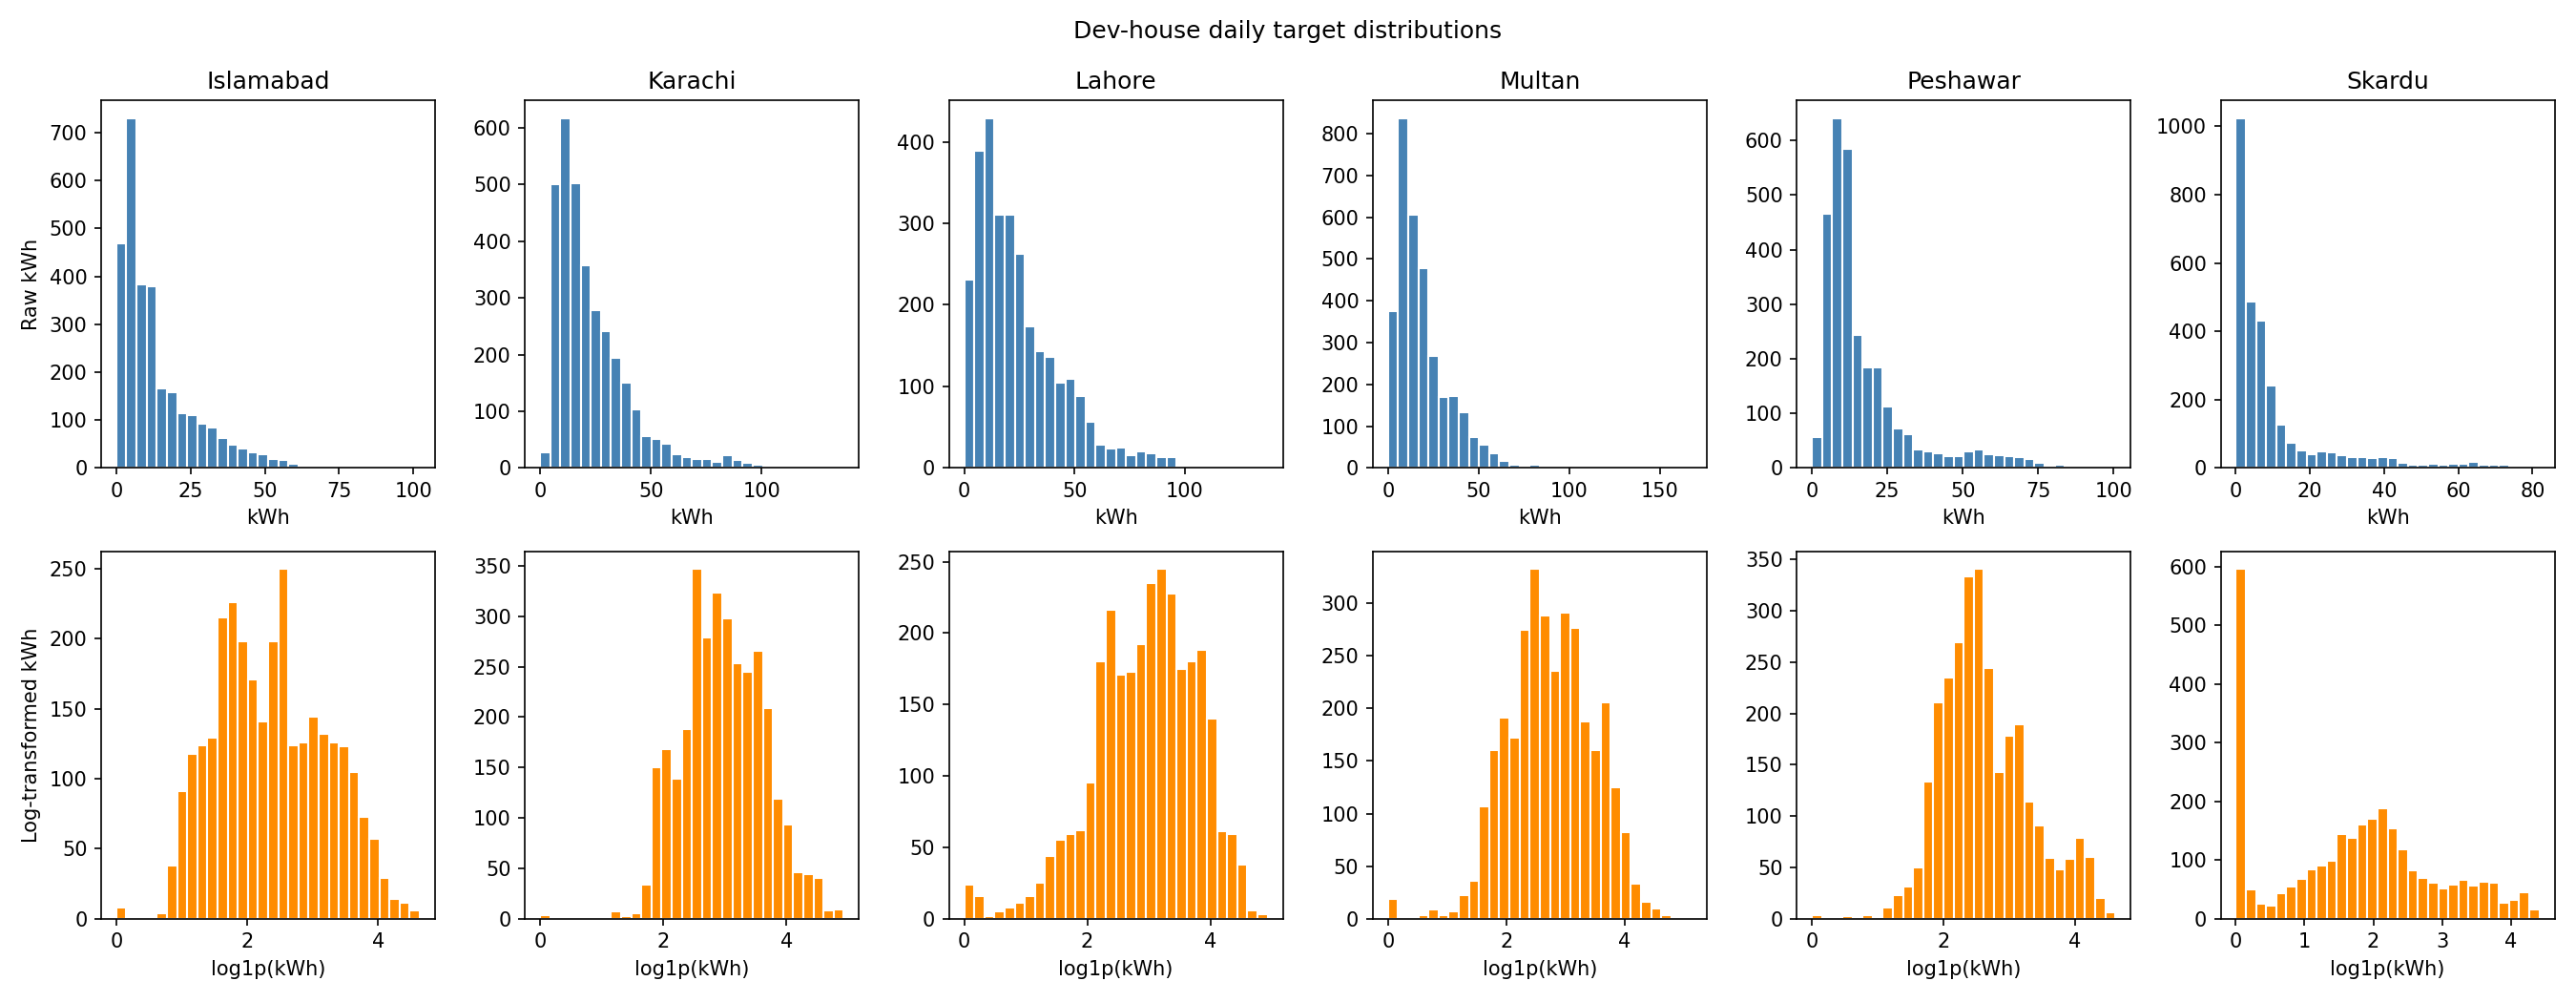

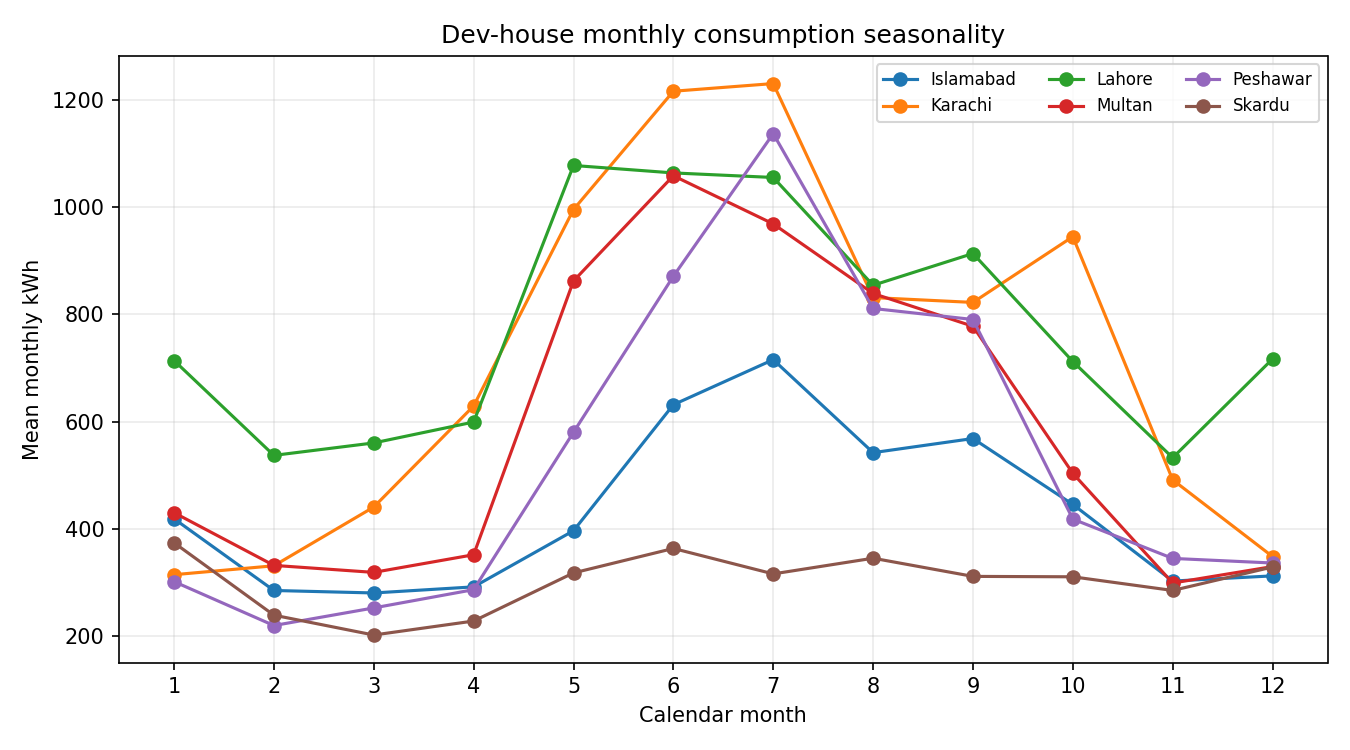

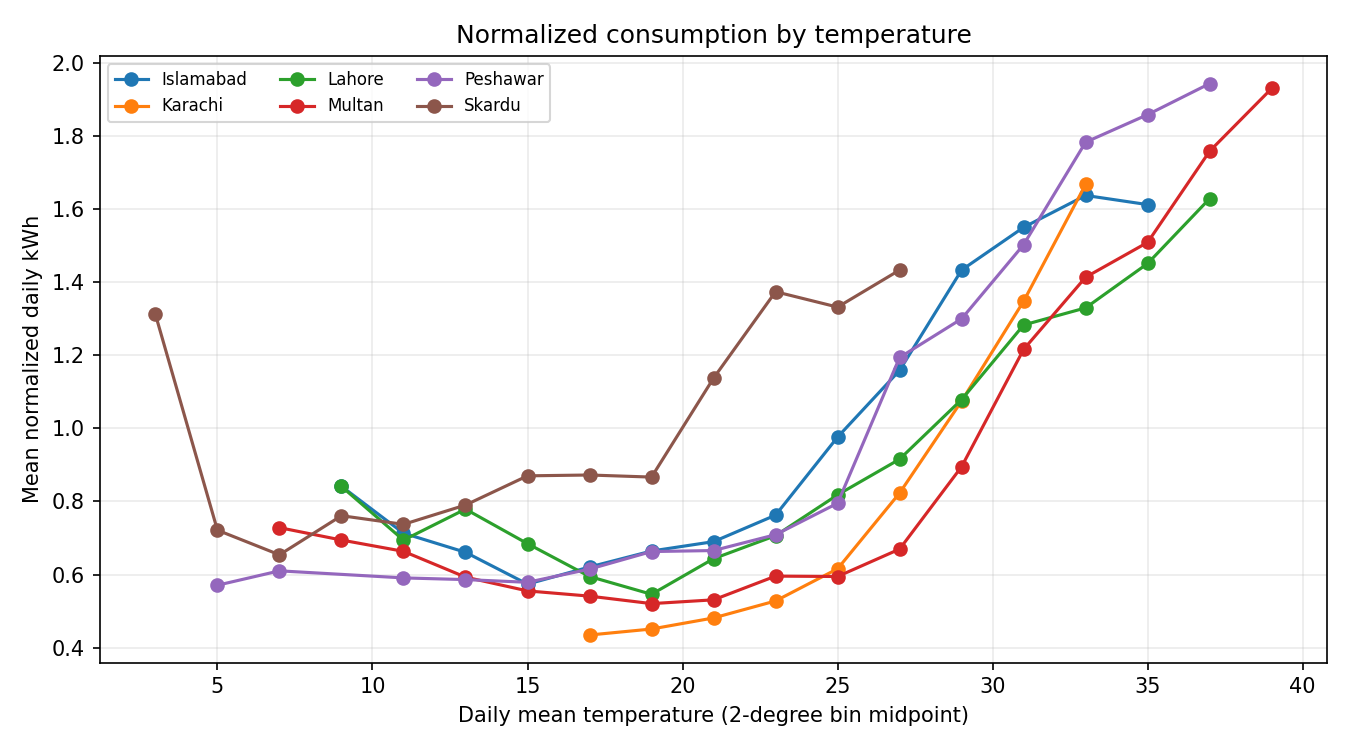

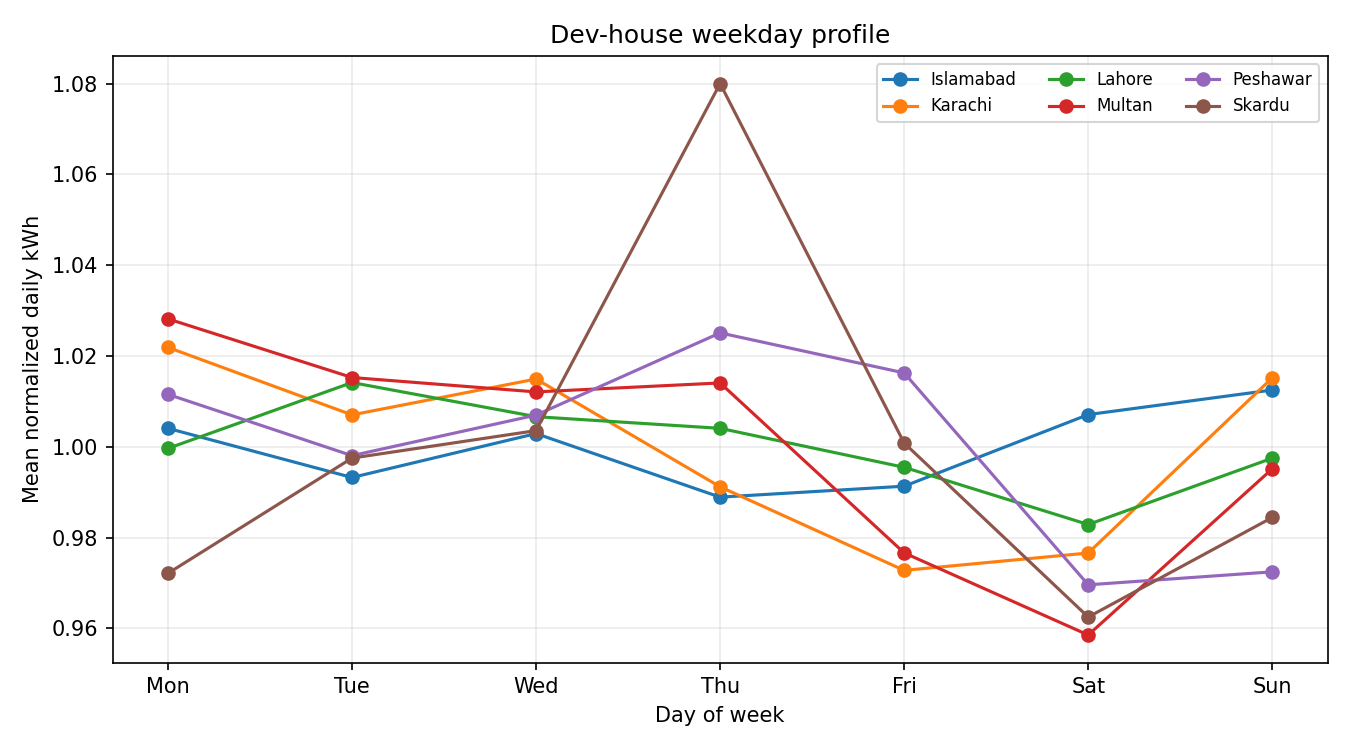

In [7]:
def load_dev_eda_inputs():
    """Filter saved daily/monthly tables to dev houses before analysis."""
    split = pd.read_csv(PROCESSED_DIR / "house_split.csv")
    dev = split.loc[split["role"].eq("dev"), ["city", "house_id"]]
    keys = set(zip(dev["city"].astype(str), dev["house_id"].astype(int)))

    def only_dev(frame):
        mask = [(str(city), int(house)) in keys for city, house in zip(frame.city, frame.house_id)]
        return frame.loc[mask].copy()

    daily = only_dev(pd.read_parquet(PROCESSED_DIR / "daily.parquet"))
    daily = daily.loc[daily["usable"].fillna(False)].copy()
    monthly = only_dev(pd.read_parquet(PROCESSED_DIR / "monthly.parquet"))
    monthly = monthly.loc[monthly["n_usable_days"].ge(25)].copy()
    house_mean = daily.groupby(["city", "house_id"], observed=True)["kwh"].transform("mean")
    daily["kwh_rel"] = daily["kwh"] / house_mean.where(house_mean.ne(0))
    return daily, monthly, len(keys)


def run_eda_overview():
    """Lightweight core of EDA 01, using dev houses only."""
    daily, monthly, count = load_dev_eda_inputs()
    print(f"Dev houses={count}; usable daily rows={len(daily)}")
    return daily.groupby("city", observed=True)["kwh_rel"].agg(["mean", "median"])


def run_eda_patterns():
    """Lightweight core of EDA 02; minute aggregation is reserved for RUN_HEAVY."""
    daily, monthly, count = load_dev_eda_inputs()
    print(f"Dev houses={count}; usable monthly rows={len(monthly)}")
    return daily.groupby("city", observed=True)["kwh_rel"].quantile([0.5, 0.95]).unstack()


if RUN_HEAVY:
    display(run_eda_overview())
    display(run_eda_patterns())
else:
    show_text(REPORT_DIRS["eda"] / "eda_01_summary.txt", max_lines=66)
    for image_name in ["target_distribution.png", "seasonality_monthly.png", "kwh_vs_temp.png", "weekday_profile.png"]:
        show_img(REPORT_DIRS["eda"] / "figures" / image_name)

**Finding — daily overview figures:** Dev-only target summaries show the highest median daily kWh in Lahore (19.785), while Skardu has the lowest (5.069). Weather association is strongest for Karachi with temperature (Spearman 0.851); weekday profiles are close to each house-normalized mean of 1.

EDA 02: Patterns (dev houses only)
Dev houses: 53; usable daily rows: 18,247
1. Hourly profiles by season (summer June-August || winter December-February)
  hour | summer Islamabad Karachi Lahore Multan Peshawar Skardu || winter Islamabad Karachi Lahore Multan Peshawar Skardu
  00 | 1.158 1.939 1.529 1.614 1.818 0.465 || 0.283 0.429 0.685 0.461 0.317 0.398
  01 | 1.082 2.031 1.430 1.623 1.729 0.462 || 0.252 0.402 0.576 0.370 0.272 0.406
  02 | 1.058 1.969 1.328 1.523 1.666 0.475 || 0.227 0.374 0.522 0.297 0.253 0.430
  03 | 1.038 1.861 1.267 1.444 1.547 0.465 || 0.219 0.354 0.491 0.273 0.241 0.446
  04 | 0.960 1.780 1.206 1.371 1.189 0.548 || 0.200 0.343 0.467 0.281 0.243 0.426
  05 | 0.882 1.720 1.095 1.235 1.278 0.544 || 0.232 0.356 0.498 0.314 0.252 0.408
  06 | 0.854 1.622 1.055 1.146 1.242 0.457 || 0.537 0.454 0.754 0.397 0.337 0.400
  07 | 0.800 1.550 1.111 1.114 0.887 0.425 || 0.489 0.487 0.792 0.442 0.481 0.384
  08 | 0.779 1.429 1.143 1.158 1.160 0.482 || 0.373 0.452 0.862 0.5

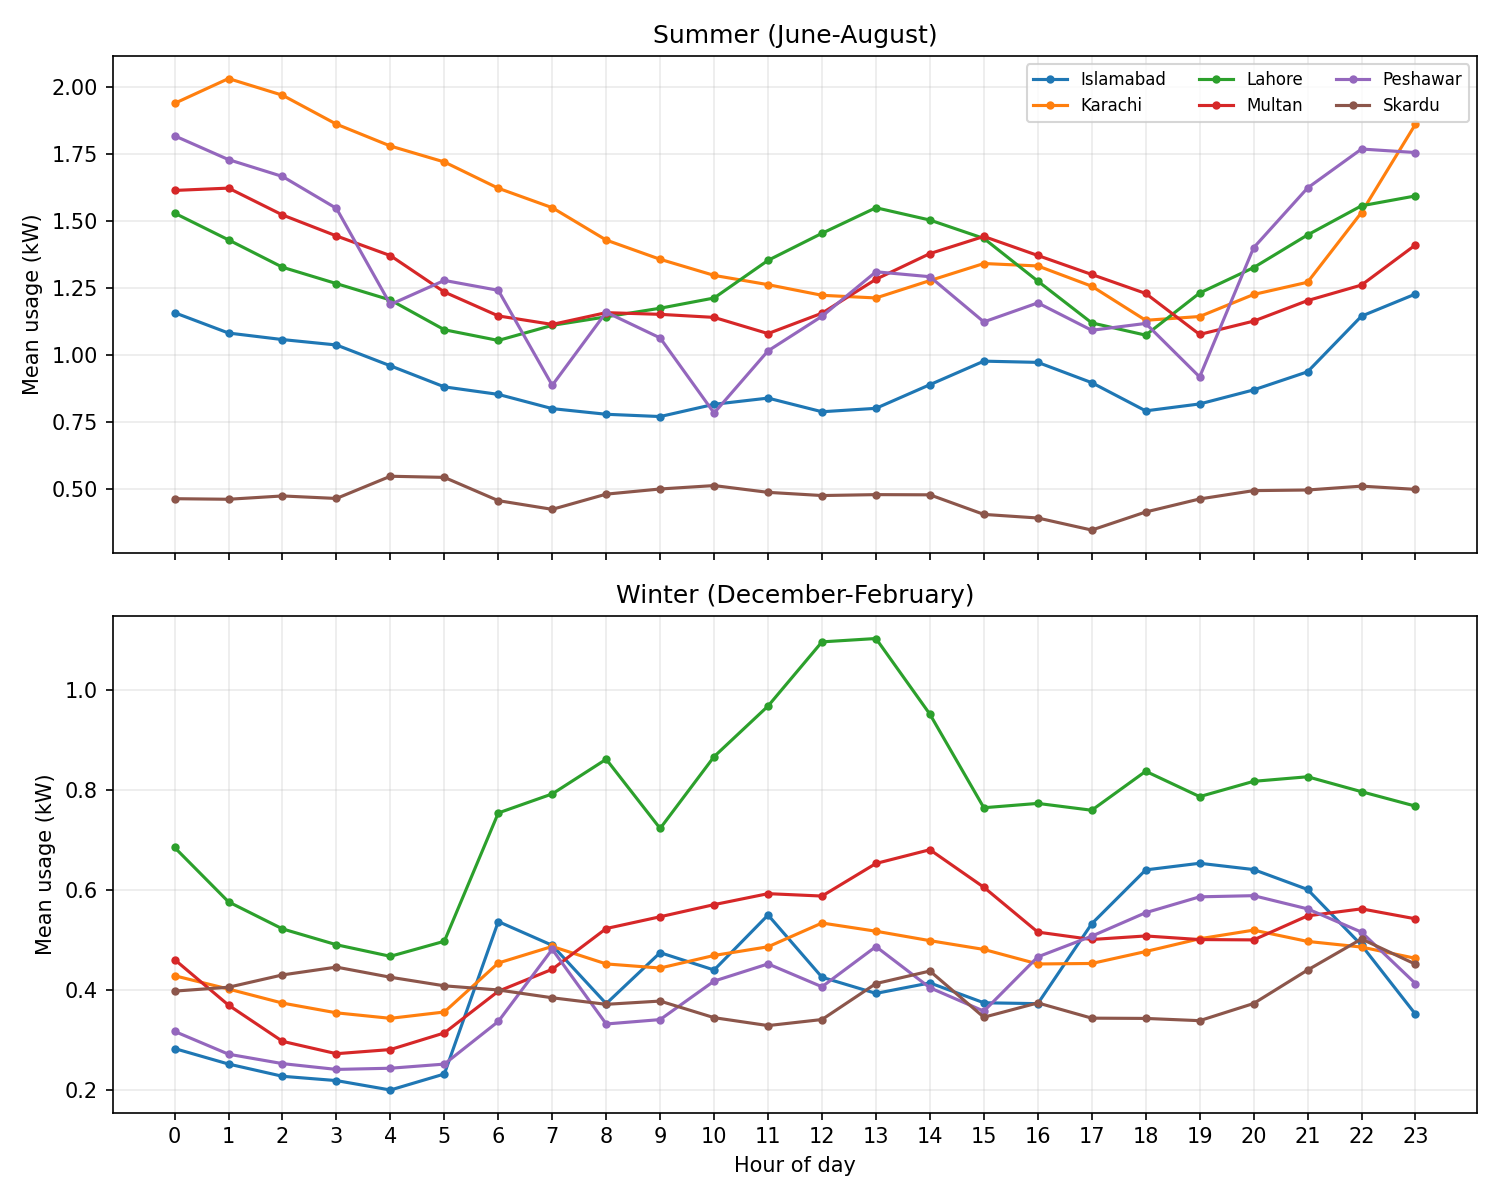

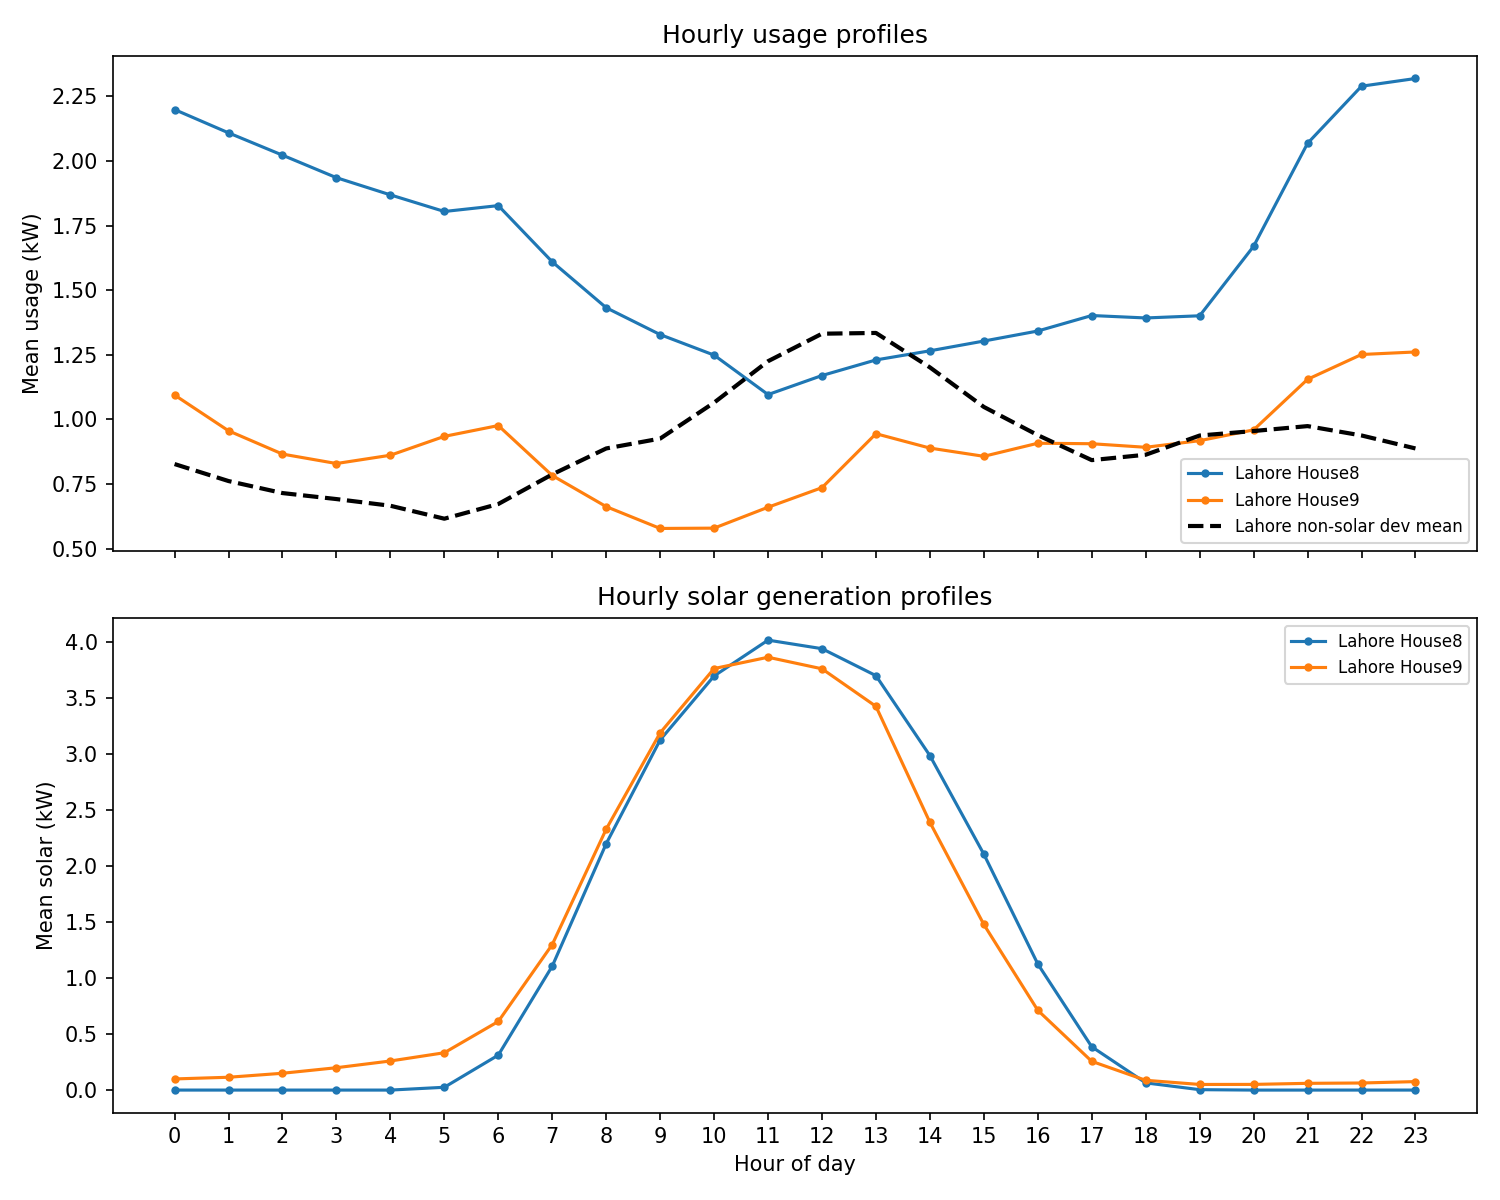

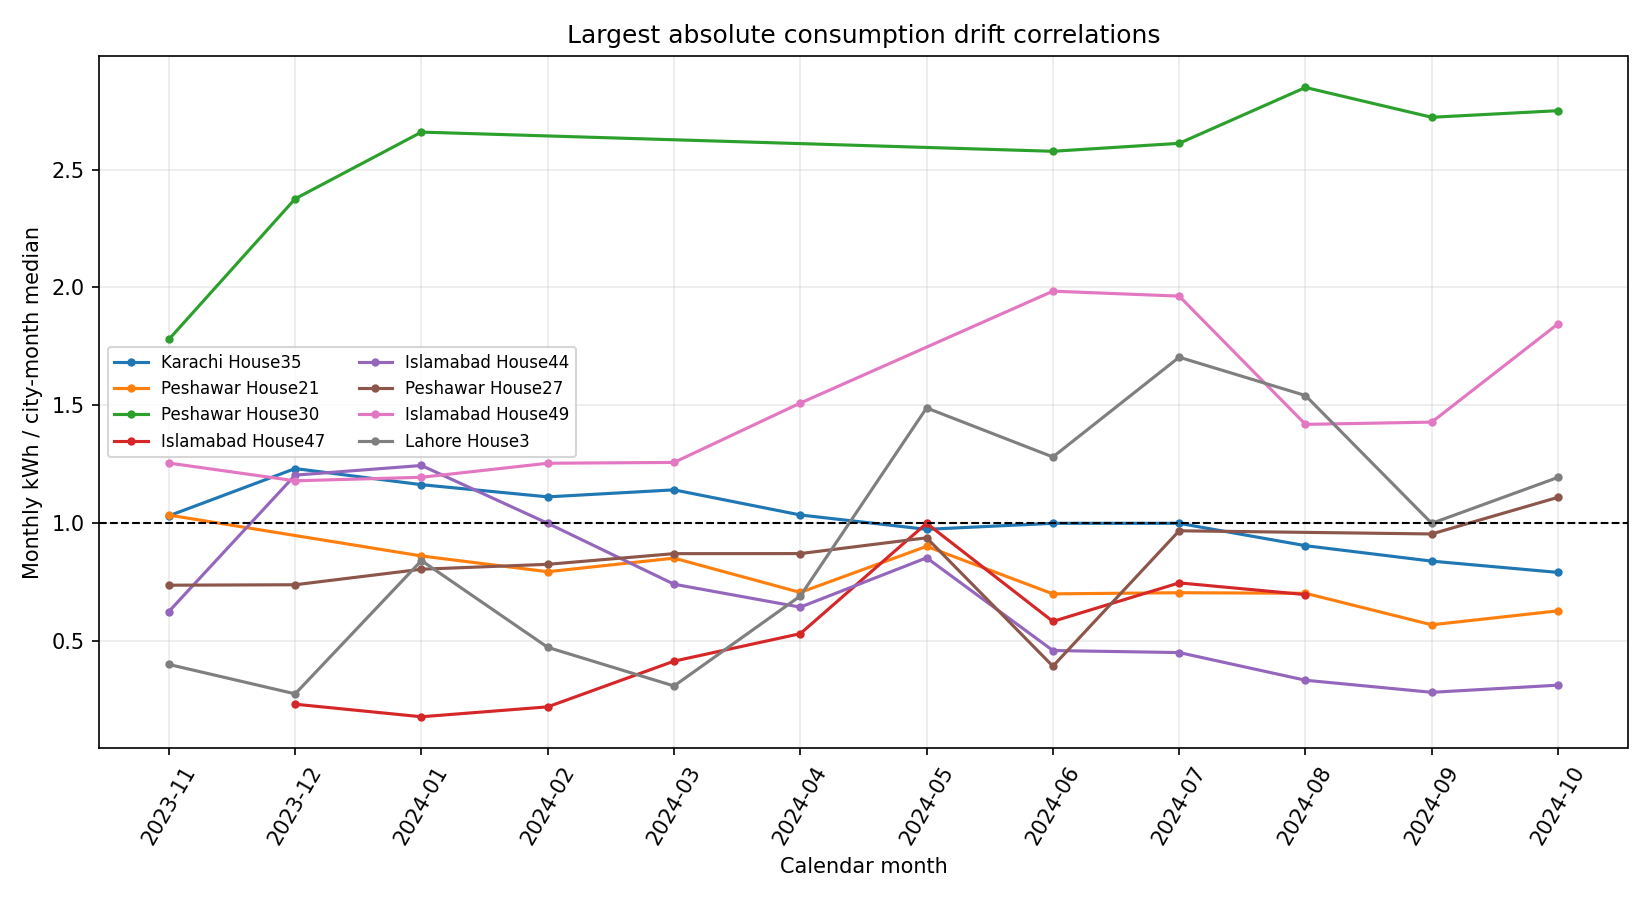

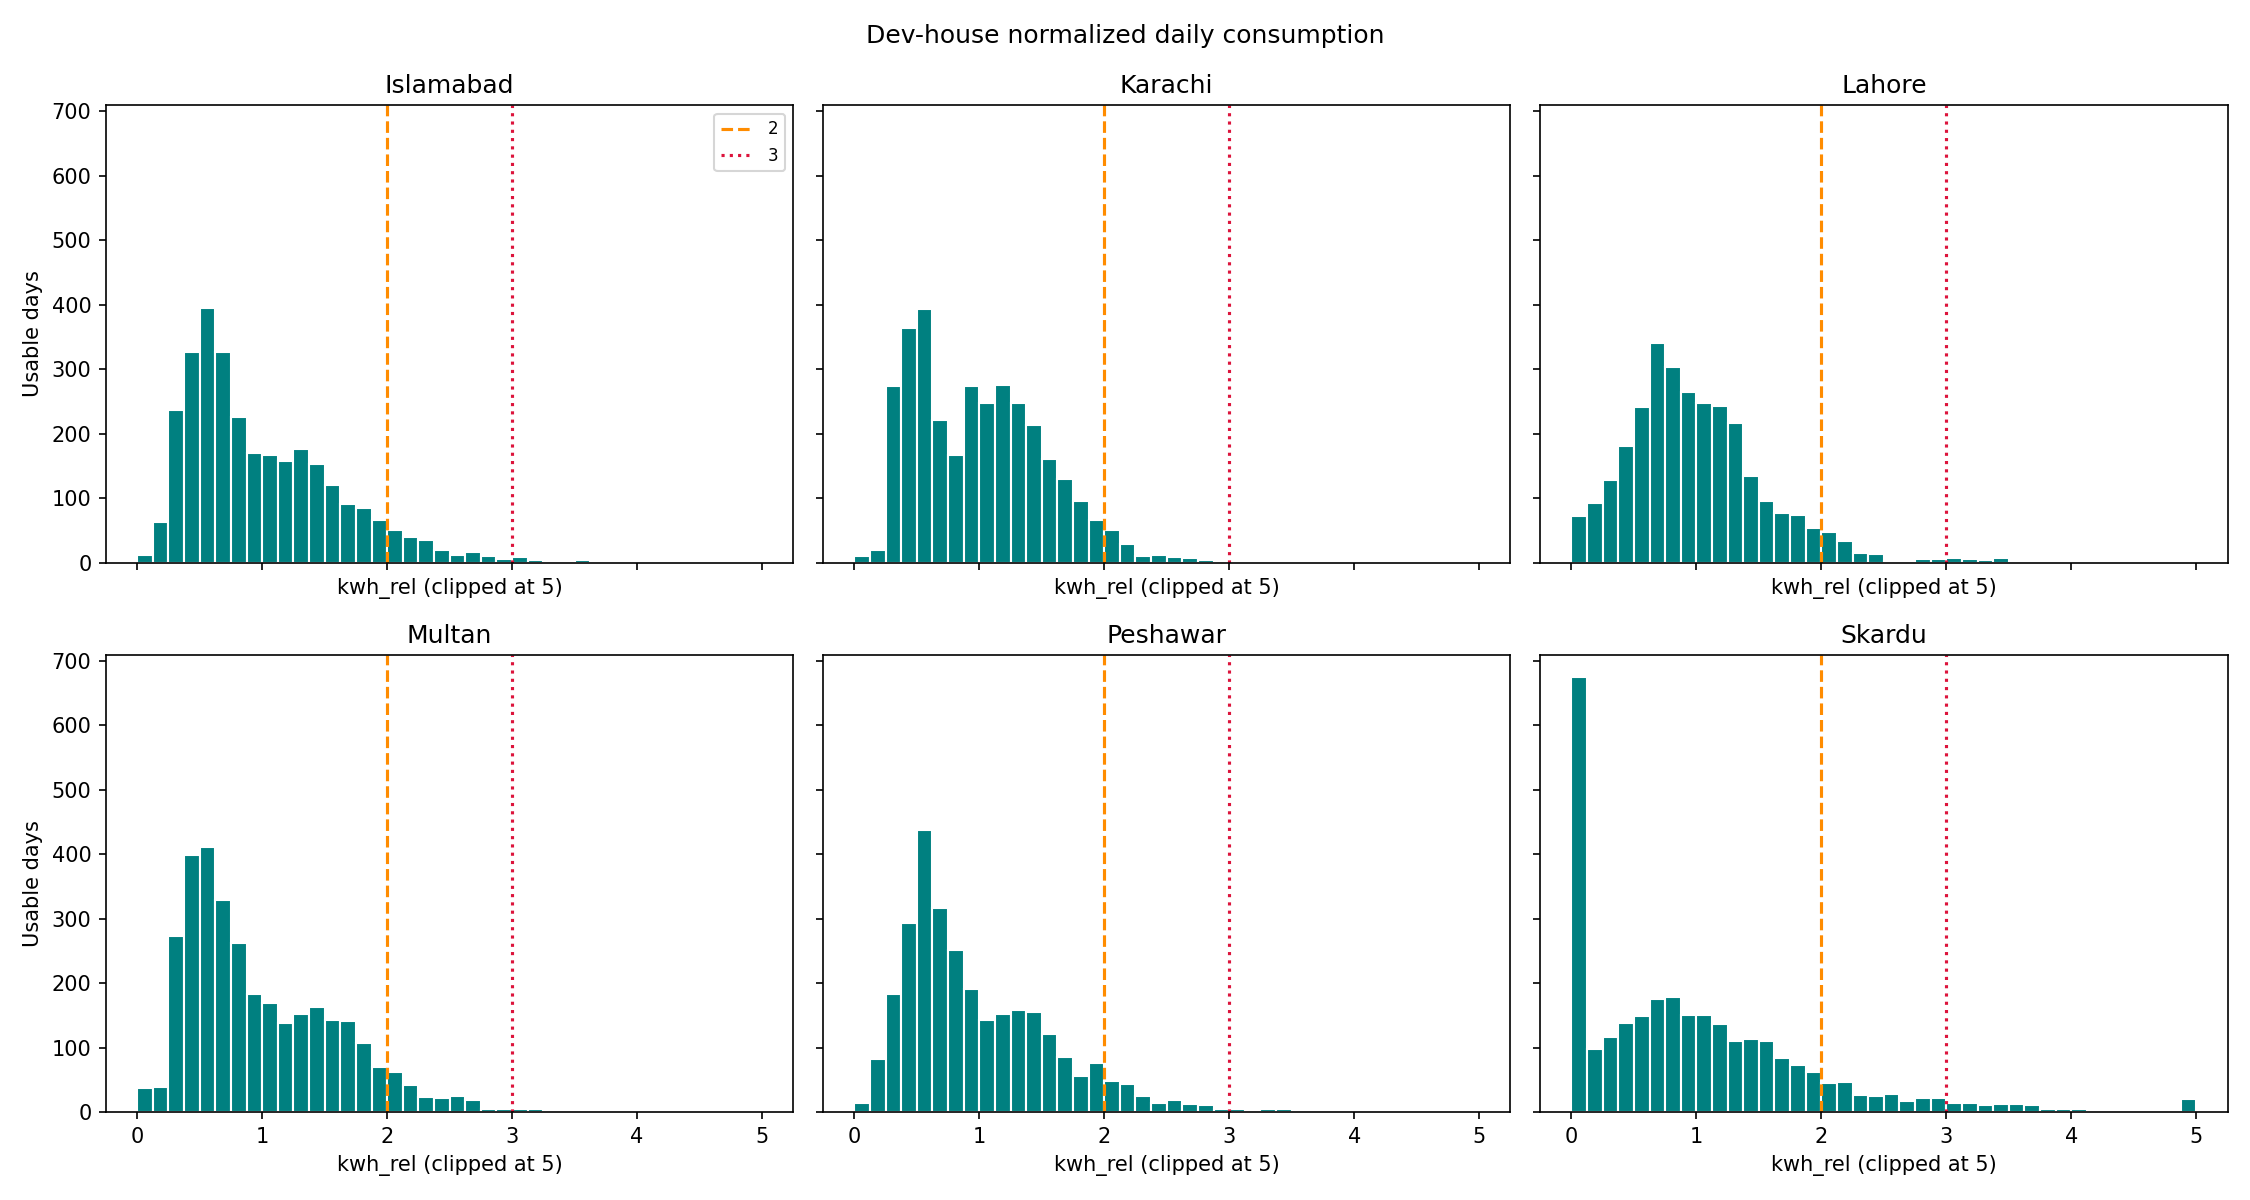

In [8]:
if RUN_HEAVY:
    daily_dev, monthly_dev, _ = load_dev_eda_inputs()
else:
    daily_dev, monthly_dev, _ = load_dev_eda_inputs()
show_text(REPORT_DIRS["eda"] / "eda_02_summary.txt", max_lines=80)
for image_name in ["hourly_profile.png", "solar_check.png", "drift_ratio.png", "kwh_rel_hist.png"]:
    show_img(REPORT_DIRS["eda"] / "figures" / image_name)

**Finding — hourly, solar, drift, and high-day figures:** The saved EDA finds solar generation in Lahore Houses 8 and 9. House9 usage is below the non-solar Lahore mean throughout 10:00?14:00, while House8 is higher at 10:00 and 14:00 and lower at 11:00?13:00; the report therefore judges the overall evidence more consistent with gross consumption. Sixteen dev houses have absolute monthly drift correlation above 0.6. Skardu has the largest share of normalized days above 2 (12.44%) and above 3 (4.33%).

### Stage 5 summary

- **Done:** displayed saved dev-only EDA reports, figures and normalized-use findings.
- **Key numbers:** Lahore median daily kWh is 19.785 and Skardu 5.069; Karachi temperature association is strongest (Spearman 0.851); 16 houses have absolute drift correlation above 0.6.
- **Decision:** normalize daily use by each house's usable-day mean for comparisons; interpret solar profiles as gross-use evidence.
- **Issues and limitations:** patterns are descriptive and may not generalize beyond this one REWDP sample.

## Stage 6: Feature engineering

### Purpose and method
- Group weather, season, city, and history into explicit feature families.
- Use only the same household's previous calendar month's kWh as `lag1_kwh`; missing calendar months do not get bridged.
- Setting A (`cold-start`) uses weather + season + city; setting B (`known-house`) adds history and requires a valid lag.
- Keep same-month target, solar availability, and outage fields out of model features.

In [9]:
WEATHER_FEATURES = ["temp_mean", "cdd_sum", "hdd_sum", "humidity_mean", "precip_sum", "solar_rad_mean"]
SEASON_FEATURES = ["month_sin", "month_cos"]
CITY_FEATURES = [f"city_{city}" for city in CITIES]
HISTORY_FEATURES = ["lag1_kwh"]


def engineer_monthly_features(monthly, min_usable_days=25):
    """Create calendar, fixed-order city dummies, and calendar-safe lag features."""
    frame = monthly.copy()
    frame["year_month"] = frame["year_month"].map(lambda value: value if isinstance(value, pd.Period) else pd.Period(value, freq="M"))
    frame = frame.sort_values(["city", "house_id", "year_month"]).reset_index(drop=True)
    frame["lag1_kwh"] = np.nan
    for (_, _), indices in frame.groupby(["city", "house_id"], sort=False).groups.items():
        by_month = {frame.at[i, "year_month"]: i for i in indices}
        for i in indices:
            previous = by_month.get(frame.at[i, "year_month"] - 1)
            if previous is not None and frame.at[previous, "n_usable_days"] >= min_usable_days:
                frame.at[i, "lag1_kwh"] = frame.at[previous, "monthly_kwh"]
    month = frame["year_month"].map(lambda value: value.month)
    frame["month_sin"] = np.sin(2 * np.pi * month / 12)
    frame["month_cos"] = np.cos(2 * np.pi * month / 12)
    dummies = pd.get_dummies(frame["city"]).reindex(columns=CITIES, fill_value=0)
    dummies.columns = CITY_FEATURES
    return pd.concat([frame, dummies], axis=1)


model_table = pd.read_parquet(PROCESSED_DIR / "model_table.parquet")
print("Saved reusable model table (head):")
display(model_table.head())
print("Cold-start feature count:", len(WEATHER_FEATURES + SEASON_FEATURES + CITY_FEATURES))
print("Known-house feature count:", len(WEATHER_FEATURES + SEASON_FEATURES + CITY_FEATURES + HISTORY_FEATURES))

Saved reusable model table (head):


,role,city,house_id,year_month,monthly_kwh,temp_mean,cdd_sum,hdd_sum,humidity_mean,precip_sum,...,month_sin,month_cos,city_Islamabad,city_Karachi,city_Lahore,city_Multan,city_Peshawar,city_Skardu,lag1_kwh,n_usable_days
0,holdout,Islamabad,41,2023-11,428.710327,16.661806,0.000000,50.012501,66.324127,83.999001,...,-5.000000e-01,8.660254e-01,1,0,0,0,0,0,NaN,30
1,holdout,Islamabad,41,2023-12,276.708147,12.316936,0.000000,176.175003,66.242775,0.985000,...,-2.449294e-16,1.000000e+00,1,0,0,0,0,0,428.710327,26
2,holdout,Islamabad,41,2024-02,581.348312,12.459052,0.000000,160.687500,61.149601,59.598000,...,8.660254e-01,5.000000e-01,1,0,0,0,0,0,NaN,25
3,holdout,Islamabad,41,2024-03,665.934916,17.297716,0.000000,53.250000,63.906857,207.369003,...,1.000000e+00,6.123234e-17,1,0,0,0,0,0,581.348312,31
4,holdout,Islamabad,41,2024-04,682.171326,20.614721,0.129166,4.716667,62.883030,120.938004,...,8.660254e-01,-5.000000e-01,1,0,0,0,0,0,665.934916,30


Cold-start feature count: 14
Known-house feature count: 15


### Timestamp and climate-zone features

Monthly model features already include month sine/cosine and fixed-order city indicators. The timestamp-level helper below adds hour, weekday, month, weekend, cyclical encodings, and all six explicit city tags for future hourly/minute models.

In [10]:
def add_time_and_city_features(frame, timestamp_column="datetime", city_column="city"):
    """Add cyclical clock/calendar terms and stable six-city metadata dummies."""
    if timestamp_column not in frame or city_column not in frame:
        raise KeyError(f"Required timestamp/city columns: {timestamp_column!r}, {city_column!r}")
    result = frame.copy()
    result[timestamp_column] = pd.to_datetime(result[timestamp_column], errors="raise")
    unknown_cities = sorted(set(result[city_column].dropna()) - set(CITIES))
    if unknown_cities:
        raise ValueError(f"Unknown city metadata tags: {unknown_cities}")
    clock = result[timestamp_column].dt
    result["hour"] = clock.hour.astype("int8")
    result["day_of_week"] = clock.dayofweek.astype("int8")
    result["month"] = clock.month.astype("int8")
    result["is_weekend"] = clock.dayofweek.ge(5).astype("int8")
    result["hour_sin"] = np.sin(2 * np.pi * result["hour"] / 24)
    result["hour_cos"] = np.cos(2 * np.pi * result["hour"] / 24)
    result["day_of_week_sin"] = np.sin(2 * np.pi * result["day_of_week"] / 7)
    result["day_of_week_cos"] = np.cos(2 * np.pi * result["day_of_week"] / 7)
    month_phase = result["month"] - 1
    result["month_sin"] = np.sin(2 * np.pi * month_phase / 12)
    result["month_cos"] = np.cos(2 * np.pi * month_phase / 12)
    city_tags = pd.get_dummies(result[city_column]).reindex(columns=CITIES, fill_value=0)
    city_tags.columns = [f"city_{city}" for city in CITIES]
    return pd.concat([result, city_tags.astype("int8")], axis=1)


# Deterministic schema example; no raw project data is modified.
calendar_example = pd.DataFrame({
    "datetime": pd.to_datetime(["2024-01-05 08:00", "2024-01-06 19:00", "2024-02-01 00:00"]),
    "city": ["Islamabad", "Karachi", "Skardu"],
})
calendar_features_example = add_time_and_city_features(calendar_example)
print("Cyclical time features and explicit city tags:")
display(calendar_features_example)
print("Fixed city tag order:", [f"city_{city}" for city in CITIES])

Cyclical time features and explicit city tags:


,datetime,city,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos,month_sin,month_cos,city_Islamabad,city_Karachi,city_Lahore,city_Multan,city_Peshawar,city_Skardu
0,2024-01-05 08:00:00,Islamabad,8,4,1,0,0.866025,-0.500000,-0.433884,-0.900969,0.0,1.000000,1,0,0,0,0,0
1,2024-01-06 19:00:00,Karachi,19,5,1,1,-0.965926,0.258819,-0.974928,-0.222521,0.0,1.000000,0,1,0,0,0,0
2,2024-02-01 00:00:00,Skardu,0,3,2,0,0.000000,1.000000,0.433884,-0.900969,0.5,0.866025,0,0,0,0,0,1


Fixed city tag order: ['city_Islamabad', 'city_Karachi', 'city_Lahore', 'city_Multan', 'city_Peshawar', 'city_Skardu']


### Stage 6 summary

- **Done:** specified weather, season, city and calendar-safe history feature groups and showed the saved model-table head.
- **Key numbers:** 631 saved modeling rows (567 dev, 64 holdout); 14 cold-start features and 15 known-house features.
- **Decision:** use only the immediately prior calendar month for `lag1_kwh`; do not bridge missing months or include same-month outcomes.
- **Issues and limitations:** the 25-usable-day threshold is the default; Stage 9 compares alternatives.
- **Feature update:** timestamp-level hour/day-of-week/month cycles, weekend flags, and six fixed city dummies are available through the added feature helper.

## Stage 7: Modeling and validation

### Purpose and method
- Compare Ridge, Random Forest, LightGBM, and XGBoost with city/month and persistence baselines.
- Use GroupKFold by household and leave-one-city-out on dev houses; drop city dummies for LOCO.
- Select each final model by dev GroupKFold RMSE, then evaluate the untouched holdout once.
- Fit imputers and scaling inside model pipelines; use log1p targets with metrics reported on the original kWh scale.

Monthly electricity modeling summary
Rows for cold-start: 631
Rows for known-house: 552

Dev pooled metrics: GroupKFold and leave-one-city-out
  setting | evaluation | model | RMSE | MAE | R2 | MAPE%
  cold-start | GroupKFold | Ridge | 425.411 | 281.408 | 0.184 | 2746.76
  cold-start | GroupKFold | RandomForest | 429.154 | 286.987 | 0.170 | 2443.36
  cold-start | GroupKFold | LightGBM | 430.863 | 288.616 | 0.163 | 2372.18
  cold-start | GroupKFold | XGBoost | 430.972 | 288.501 | 0.163 | 2368.94
  cold-start | GroupKFold | CityMonthMean | 435.366 | 307.378 | 0.146 | 3147.79
  cold-start | LOCO | Ridge | 415.434 | 270.754 | 0.222 | 4394.32
  cold-start | LOCO | RandomForest | 420.969 | 281.482 | 0.201 | 5625.85
  cold-start | LOCO | LightGBM | 424.478 | 286.297 | 0.188 | 5622.11
  cold-start | LOCO | XGBoost | 423.448 | 290.438 | 0.192 | 5502.42
  cold-start | LOCO | CityMonthMean | 434.597 | 317.301 | 0.149 | 9264.90
  known-house | GroupKFold | Ridge | 613.837 | 239.967 | -0.613 | 2669

Pooled dev metrics:


,setting,evaluation,model,scope,RMSE,MAE,R2,MAPE
0,cold-start,GroupKFold,Ridge,pooled,425.411473,281.407502,0.184331,2746.760084
1,cold-start,GroupKFold,RandomForest,pooled,429.154403,286.986811,0.169915,2443.359881
2,cold-start,GroupKFold,LightGBM,pooled,430.863083,288.616041,0.163291,2372.176273
3,cold-start,GroupKFold,XGBoost,pooled,430.971558,288.501499,0.162870,2368.942167
4,cold-start,GroupKFold,CityMonthMean,pooled,435.365673,307.377901,0.145713,3147.785196
5,cold-start,LOCO,Ridge,pooled,415.434284,270.754214,0.222142,4394.318573
6,cold-start,LOCO,RandomForest,pooled,420.968906,281.481676,0.201278,5625.853798
7,cold-start,LOCO,LightGBM,pooled,424.477678,286.297118,0.187908,5622.110242
8,cold-start,LOCO,XGBoost,pooled,423.447520,290.438489,0.191845,5502.424641
9,cold-start,LOCO,CityMonthMean,pooled,434.597074,317.300767,0.148726,9264.904982


Final holdout metrics:


,setting,evaluation,model,scope,RMSE,MAE,R2,MAPE,n
0,cold-start,FinalHoldout,Ridge,overall,219.508486,171.201834,0.463095,94.367979,64
1,cold-start,FinalHoldout,Ridge,Islamabad House41,281.885468,229.534787,-1.700502,39.842906,9
2,cold-start,FinalHoldout,Ridge,Karachi House38,258.286624,167.076885,0.537812,37.616428,11
3,cold-start,FinalHoldout,Ridge,Lahore House4,158.927123,126.460386,0.708480,25.463361,12
4,cold-start,FinalHoldout,Ridge,Multan House15,284.892578,251.925229,-7.214822,87.746827,11
5,cold-start,FinalHoldout,Ridge,Peshawar House24,162.365852,144.660454,-0.485853,45.991496,12
6,cold-start,FinalHoldout,Ridge,Skardu House59,116.695378,114.292328,-29.475421,382.723378,9
7,cold-start,FinalHoldout,CityMonthMean,overall,286.584245,229.593039,0.084835,192.576920,64
8,cold-start,FinalHoldout,CityMonthMean,Islamabad House41,245.924399,211.045245,-1.055429,38.921011,9
9,cold-start,FinalHoldout,CityMonthMean,Karachi House38,290.235711,158.801233,0.416399,43.377173,11


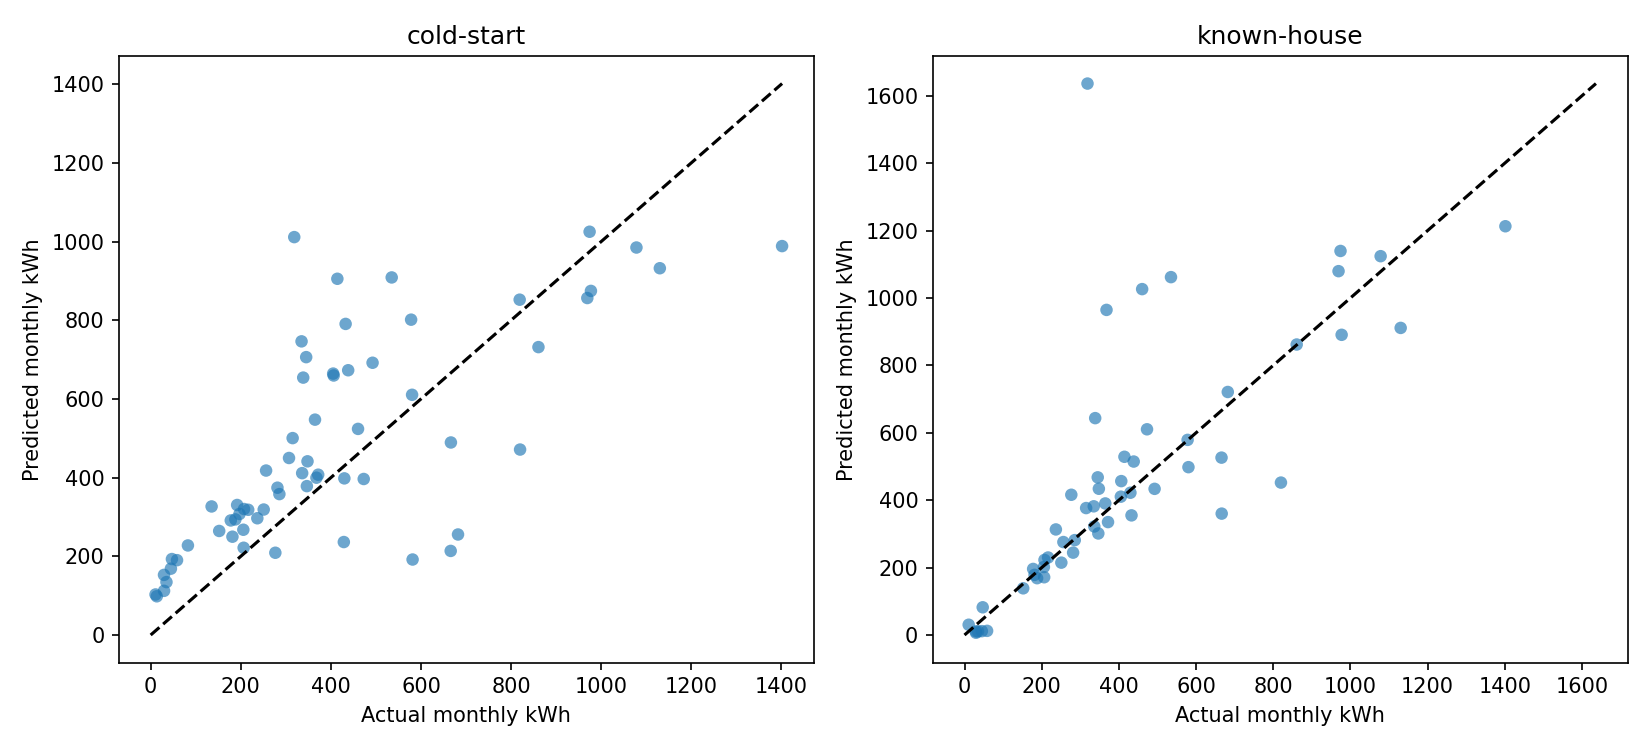

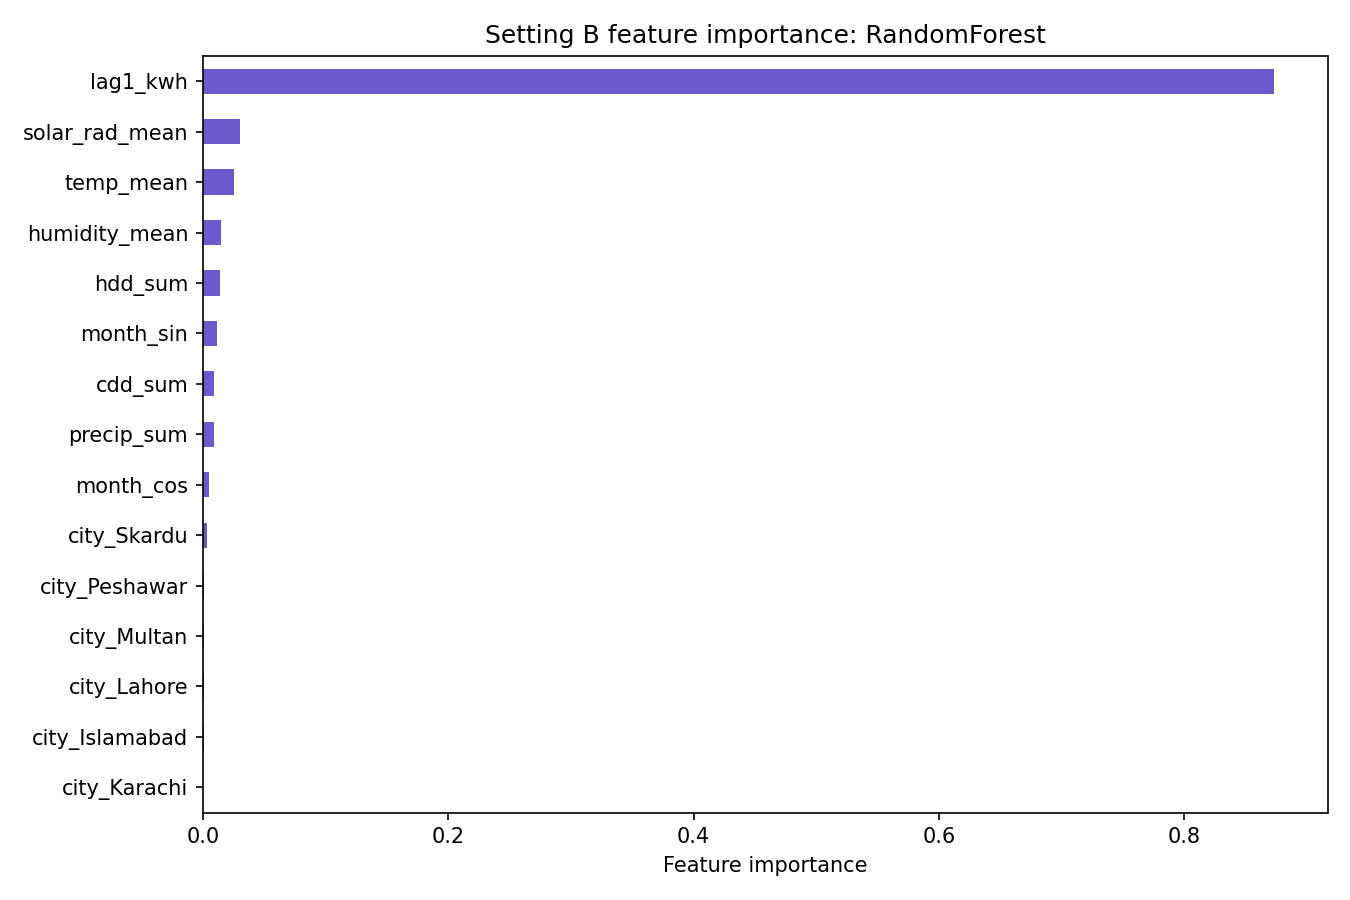

In [11]:
if RUN_HEAVY:
    # Full Stage 7 trainer; LightGBM is imported only inside its model factory.
    import sys
    from pathlib import Path
    from config import PROCESSED_DIR, MODELS_DIR, REPORT_DIRS, CITIES, RANDOM_SEED

    import warnings

    import joblib
    import numpy as np
    import pandas as pd
    import xgboost as xgb
    from sklearn.compose import TransformedTargetRegressor
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import Ridge
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler


    MONTHLY_PATH = PROCESSED_DIR / "monthly.parquet"
    SPLIT_PATH = PROCESSED_DIR / "house_split.csv"
    WEATHER_FEATURES = [
        "temp_mean",
        "cdd_sum",
        "hdd_sum",
        "humidity_mean",
        "precip_sum",
        "solar_rad_mean",
    ]
    REQUIRED_MONTHLY_COLUMNS = {
        "city",
        "house_id",
        "role",
        "year_month",
        "n_usable_days",
        "days_in_month",
        "mean_daily_kwh",
        "monthly_kwh",
        *WEATHER_FEATURES,
    }
    IDENTIFIER_COLUMNS = ["role", "city", "house_id", "year_month", "monthly_kwh"]
    CITY_FEATURES = [f"city_{city}" for city in CITIES]
    SEASON_FEATURES = ["month_sin", "month_cos"]
    HISTORY_FEATURES = ["lag1_kwh"]
    SETTING_FEATURES = {
        "cold-start": WEATHER_FEATURES + SEASON_FEATURES + CITY_FEATURES,
        "known-house": WEATHER_FEATURES + SEASON_FEATURES + CITY_FEATURES + HISTORY_FEATURES,
    }
    MODEL_NAMES = ["Ridge", "RandomForest", "LightGBM", "XGBoost"]
    METRIC_NAMES = ["RMSE", "MAE", "R2", "MAPE"]


    def parse_period(value: object) -> pd.Period:
        if isinstance(value, pd.Period):
            return value.asfreq("M")
        return pd.Period(value, freq="M")


    def add_features(monthly: pd.DataFrame) -> pd.DataFrame:
        frame = monthly.copy()
        frame["year_month"] = frame["year_month"].map(parse_period)
        frame["house_id"] = pd.to_numeric(frame["house_id"], errors="raise").astype(int)
        frame["city"] = frame["city"].astype(str)
        frame["role"] = frame["role"].astype(str)
        frame = frame.sort_values(
            ["city", "house_id", "year_month"],
            kind="stable",
        ).reset_index(drop=True)

        lag_values = np.full(len(frame), np.nan, dtype=float)
        for _, indices in frame.groupby(["city", "house_id"], sort=False).groups.items():
            ordered_indices = list(indices)
            values = {
                frame.at[index, "year_month"]: (
                    float(frame.at[index, "monthly_kwh"])
                    if frame.at[index, "n_usable_days"] >= 25
                    and pd.notna(frame.at[index, "monthly_kwh"])
                    else np.nan
                )
                for index in ordered_indices
            }
            for index in ordered_indices:
                previous = values.get(frame.at[index, "year_month"] - 1, np.nan)
                lag_values[index] = previous
        frame["lag1_kwh"] = lag_values

        month_number = frame["year_month"].map(lambda period: period.month)
        frame["month_sin"] = np.sin(2 * np.pi * month_number / 12)
        frame["month_cos"] = np.cos(2 * np.pi * month_number / 12)
        city_dummies = pd.get_dummies(frame["city"], dtype=np.int8).reindex(
            columns=CITIES,
            fill_value=0,
        )
        city_dummies.columns = CITY_FEATURES
        frame = pd.concat([frame, city_dummies], axis=1)
        modeling = frame.loc[frame["n_usable_days"] >= 25].copy()
        return modeling[
            IDENTIFIER_COLUMNS
            + WEATHER_FEATURES
            + SEASON_FEATURES
            + CITY_FEATURES
            + HISTORY_FEATURES
            + ["n_usable_days"]
        ].reset_index(drop=True)


    def make_model(name: str) -> object:
        if name == "Ridge":
            regressor = Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                    ("model", Ridge()),
                ]
            )
        elif name == "RandomForest":
            regressor = Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    (
                        "model",
                        RandomForestRegressor(
                            n_estimators=300,
                            min_samples_leaf=3,
                            n_jobs=-1,
                            random_state=RANDOM_SEED,
                        ),
                    ),
                ]
            )
        elif name == "LightGBM":
            import lightgbm as lgb
            regressor = Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    (
                        "model",
                        lgb.LGBMRegressor(
                            n_estimators=300,
                            learning_rate=0.05,
                            num_leaves=15,
                            min_child_samples=10,
                            verbose=-1,
                            random_state=RANDOM_SEED,
                        ),
                    ),
                ]
            )
        elif name == "XGBoost":
            regressor = Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    (
                        "model",
                        xgb.XGBRegressor(
                            n_estimators=300,
                            learning_rate=0.05,
                            max_depth=4,
                            objective="reg:squarederror",
                            n_jobs=-1,
                            random_state=RANDOM_SEED,
                        ),
                    ),
                ]
            )
        else:
            raise ValueError(f"Unknown model: {name}")
        return TransformedTargetRegressor(
            regressor=regressor,
            func=np.log1p,
            inverse_func=np.expm1,
            check_inverse=False,
        )


    def calculate_metrics(actual: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
        actual = np.asarray(actual, dtype=float)
        predicted = np.asarray(predicted, dtype=float)
        finite = np.isfinite(actual) & np.isfinite(predicted)
        actual = actual[finite]
        predicted = predicted[finite]
        if not len(actual):
            return {name: float("nan") for name in METRIC_NAMES}
        positive = actual > 0
        return {
            "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
            "MAE": float(mean_absolute_error(actual, predicted)),
            "R2": float(r2_score(actual, predicted)) if len(actual) >= 2 else float("nan"),
            "MAPE": (
                float(np.mean(np.abs((actual[positive] - predicted[positive]) / actual[positive])) * 100)
                if positive.any()
                else float("nan")
            ),
        }


    def append_metrics(
        results: list[dict[str, object]],
        setting: str,
        evaluation: str,
        model: str,
        scope: str,
        actual: np.ndarray,
        predicted: np.ndarray,
    ) -> None:
        results.append(
            {
                "setting": setting,
                "evaluation": evaluation,
                "model": model,
                "scope": scope,
                **calculate_metrics(actual, predicted),
            }
        )


    def city_month_baseline(
        train: pd.DataFrame,
        test: pd.DataFrame,
    ) -> np.ndarray:
        train_month = train["year_month"].map(lambda period: period.month)
        test_month = test["year_month"].map(lambda period: period.month)
        city_month = train.assign(_month=train_month).groupby(
            ["city", "_month"],
            observed=True,
        )["monthly_kwh"].mean()
        month_mean = train.assign(_month=train_month).groupby("_month")[
            "monthly_kwh"
        ].mean()
        global_mean = float(train["monthly_kwh"].mean())
        return np.asarray(
            [
                city_month.get((row.city, month), month_mean.get(month, global_mean))
                for row, month in zip(
                    test[["city"]].itertuples(index=False),
                    test_month,
                    strict=True,
                )
            ],
            dtype=float,
        )


    def feature_matrix(frame: pd.DataFrame, features: list[str]) -> pd.DataFrame:
        return frame.loc[:, features].astype(float)


    def check_dev_holdout_disjoint(
        train: pd.DataFrame,
        test: pd.DataFrame,
        holdout_keys: set[tuple[str, int]],
        label: str,
    ) -> None:
        train_keys = set(zip(train["city"], train["house_id"], strict=True))
        test_keys = set(zip(test["city"], test["house_id"], strict=True))
        if train_keys & holdout_keys:
            raise AssertionError(f"{label}: holdout house found in training rows")
        if test_keys & holdout_keys:
            raise AssertionError(f"{label}: holdout house found in validation rows")
        if train_keys & test_keys and label == "GroupKFold":
            raise AssertionError(f"{label}: train and validation house sets overlap")


    def group_kfold_evaluation(
        table: pd.DataFrame,
        setting: str,
        features: list[str],
        holdout_keys: set[tuple[str, int]],
        results: list[dict[str, object]],
    ) -> dict[str, float]:
        groups = table["house_id"].to_numpy()
        splitter = GroupKFold(n_splits=5)
        predictions: dict[str, list[tuple[np.ndarray, np.ndarray, pd.Series]]] = {
            name: [] for name in [*MODEL_NAMES, "CityMonthMean"]
        }
        if setting == "known-house":
            predictions["Persistence"] = []

        for train_index, test_index in splitter.split(table, groups=groups):
            train = table.iloc[train_index]
            test = table.iloc[test_index]
            check_dev_holdout_disjoint(train, test, holdout_keys, "GroupKFold")
            train_houses = set(train["house_id"])
            test_houses = set(test["house_id"])
            if train_houses & test_houses:
                raise AssertionError("GroupKFold: train and validation house IDs overlap")

            actual_train = train["monthly_kwh"].to_numpy(dtype=float)
            actual_test = test["monthly_kwh"].to_numpy(dtype=float)
            x_train = feature_matrix(train, features)
            x_test = feature_matrix(test, features)
            for name in MODEL_NAMES:
                model = make_model(name)
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    model.fit(x_train, actual_train)
                predicted = np.asarray(model.predict(x_test), dtype=float)
                predictions[name].append((actual_test, predicted, test["city"]))

            baseline = city_month_baseline(train, test)
            predictions["CityMonthMean"].append((actual_test, baseline, test["city"]))
            if setting == "known-house":
                predictions["Persistence"].append(
                    (actual_test, test["lag1_kwh"].to_numpy(dtype=float), test["city"])
                )

        best: dict[str, float] = {}
        for name, pieces in predictions.items():
            actual = np.concatenate([piece[0] for piece in pieces])
            predicted = np.concatenate([piece[1] for piece in pieces])
            cities = pd.concat([piece[2] for piece in pieces], ignore_index=True)
            append_metrics(results, setting, "GroupKFold", name, "pooled", actual, predicted)
            best[name] = calculate_metrics(actual, predicted)["RMSE"]
            for city in CITIES:
                mask = cities.eq(city).to_numpy()
                append_metrics(
                    results,
                    setting,
                    "GroupKFold",
                    name,
                    city,
                    actual[mask],
                    predicted[mask],
                )
        return best


    def loco_evaluation(
        table: pd.DataFrame,
        setting: str,
        features: list[str],
        holdout_keys: set[tuple[str, int]],
        results: list[dict[str, object]],
    ) -> None:
        loco_features = [feature for feature in features if feature not in CITY_FEATURES]
        all_predictions: dict[str, list[tuple[np.ndarray, np.ndarray]]] = {
            name: [] for name in [*MODEL_NAMES, "CityMonthMean"]
        }
        if setting == "known-house":
            all_predictions["Persistence"] = []

        for city in CITIES:
            train = table.loc[table["city"].ne(city)]
            test = table.loc[table["city"].eq(city)]
            check_dev_holdout_disjoint(train, test, holdout_keys, f"LOCO {city}")
            if set(train["city"]) & set(test["city"]):
                raise AssertionError(f"LOCO {city}: train and test city sets overlap")
            if set(train["city"]) != set(CITIES) - {city}:
                raise AssertionError(f"LOCO {city}: expected five training cities")

            actual_train = train["monthly_kwh"].to_numpy(dtype=float)
            actual_test = test["monthly_kwh"].to_numpy(dtype=float)
            x_train = feature_matrix(train, loco_features)
            x_test = feature_matrix(test, loco_features)
            city_predictions: dict[str, np.ndarray] = {}

            for name in MODEL_NAMES:
                model = make_model(name)
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    model.fit(x_train, actual_train)
                city_predictions[name] = np.asarray(model.predict(x_test), dtype=float)
            city_predictions["CityMonthMean"] = city_month_baseline(train, test)
            if setting == "known-house":
                city_predictions["Persistence"] = test["lag1_kwh"].to_numpy(dtype=float)

            for name, predicted in city_predictions.items():
                append_metrics(results, setting, "LOCO", name, city, actual_test, predicted)
                all_predictions[name].append((actual_test, predicted))

        for name, pieces in all_predictions.items():
            append_metrics(
                results,
                setting,
                "LOCO",
                name,
                "pooled",
                np.concatenate([piece[0] for piece in pieces]),
                np.concatenate([piece[1] for piece in pieces]),
            )


    def fit_final_model(
        table: pd.DataFrame,
        setting: str,
        features: list[str],
        holdout: pd.DataFrame,
        model_name: str,
    ) -> tuple[object, np.ndarray]:
        model = make_model(model_name)
        model.fit(
            feature_matrix(table, features),
            table["monthly_kwh"].to_numpy(dtype=float),
        )
        predicted = np.asarray(model.predict(feature_matrix(holdout, features)), dtype=float)
        return model, predicted


    def fit_final_baselines(
        dev_table: pd.DataFrame,
        holdout_table: pd.DataFrame,
        setting: str,
    ) -> dict[str, np.ndarray]:
        predictions = {
            "CityMonthMean": city_month_baseline(dev_table, holdout_table)
        }
        if setting == "known-house":
            predictions["Persistence"] = holdout_table["lag1_kwh"].to_numpy(dtype=float)
        return predictions


    def feature_importance_model(
        table: pd.DataFrame,
        features: list[str],
        best_models: dict[str, float],
    ) -> tuple[str, object]:
        tree_names = ["RandomForest", "LightGBM", "XGBoost"]
        selected_name = min(tree_names, key=lambda name: best_models[name])
        model = make_model(selected_name)
        model.fit(
            feature_matrix(table, features),
            table["monthly_kwh"].to_numpy(dtype=float),
        )
        return selected_name, model


    def save_feature_importance(
        name: str,
        model: object,
        features: list[str],
        output_path: Path,
    ) -> None:
        pipeline = model.regressor_
        estimator = pipeline.named_steps["model"]
        importance = pd.Series(
            estimator.feature_importances_,
            index=features,
        ).sort_values()
        import matplotlib.pyplot as plt

        figure, axis = plt.subplots(figsize=(9, 6))
        importance.plot.barh(ax=axis, color="slateblue")
        axis.set_title(f"Setting B feature importance: {name}")
        axis.set_xlabel("Feature importance")
        figure.tight_layout()
        figure.savefig(output_path, dpi=150)
        plt.close(figure)


    def save_holdout_plot(
        predictions: dict[str, tuple[np.ndarray, np.ndarray]],
        output_path: Path,
    ) -> None:
        import matplotlib.pyplot as plt

        figure, axes = plt.subplots(1, 2, figsize=(11, 5))
        for axis, setting in zip(axes, ("cold-start", "known-house"), strict=True):
            actual, predicted = predictions[setting]
            axis.scatter(actual, predicted, alpha=0.65, edgecolors="none")
            maximum = float(max(np.max(actual), np.max(predicted)))
            axis.plot([0, maximum], [0, maximum], color="black", linestyle="--")
            axis.set_xlabel("Actual monthly kWh")
            axis.set_ylabel("Predicted monthly kWh")
            axis.set_title(setting)
        figure.tight_layout()
        figure.savefig(output_path, dpi=150)
        plt.close(figure)


    def build_summary(
        modeling_table: pd.DataFrame,
        dev_results: pd.DataFrame,
        holdout_results: pd.DataFrame,
        selected: dict[str, str],
    ) -> str:
        lines = ["Monthly electricity modeling summary"]
        for setting, features in SETTING_FEATURES.items():
            setting_table = modeling_table.loc[
                modeling_table["n_usable_days"].ge(25)
                & (modeling_table["lag1_kwh"].notna() if setting == "known-house" else True)
            ]
            lines.append(f"Rows for {setting}: {len(setting_table)}")

        lines.extend(["", "Dev pooled metrics: GroupKFold and leave-one-city-out"])
        lines.append("  setting | evaluation | model | RMSE | MAE | R2 | MAPE%")
        pooled = dev_results.loc[
            dev_results["scope"].eq("pooled")
            & dev_results["evaluation"].isin(["GroupKFold", "LOCO"])
        ]
        for row in pooled.itertuples(index=False):
            lines.append(
                f"  {row.setting} | {row.evaluation} | {row.model} | "
                f"{row.RMSE:.3f} | {row.MAE:.3f} | {row.R2:.3f} | {row.MAPE:.2f}"
            )

        lines.extend(["", "Best model per setting (dev GroupKFold RMSE)"])
        for setting in SETTING_FEATURES:
            lines.append(f"  {setting}: {selected[setting]}")

        lines.extend(["", "Final holdout metrics (one evaluation; includes baselines)"])
        lines.append("  setting | model | scope | n | RMSE | MAE | R2 | MAPE%")
        overall_results = holdout_results.loc[holdout_results["scope"].eq("overall")]
        for row in overall_results.itertuples(index=False):
            lines.append(
                f"  {row.setting} | {row.model} | {row.scope} | {row.n} | "
                f"{row.RMSE:.3f} | {row.MAE:.3f} | {row.R2:.3f} | {row.MAPE:.2f}"
            )
        return "\n".join(lines) + "\n"


    def main() -> None:
        if "modeling" not in REPORT_DIRS:
            raise RuntimeError("REPORT_DIRS must contain the 'modeling' report directory")
        monthly = pd.read_parquet(MONTHLY_PATH)
        print("Monthly column names:", monthly.columns.tolist())
        missing = sorted(REQUIRED_MONTHLY_COLUMNS - set(monthly.columns))
        if missing:
            raise ValueError(f"{MONTHLY_PATH} is missing required columns: {missing}")
        split = pd.read_csv(SPLIT_PATH)
        print("House split column names:", split.columns.tolist())
        split_required = {"city", "house_id", "role"}
        missing_split = sorted(split_required - set(split.columns))
        if missing_split:
            raise ValueError(f"{SPLIT_PATH} is missing required columns: {missing_split}")

        monthly["year_month"] = monthly["year_month"].map(parse_period)
        monthly["city"] = monthly["city"].astype(str)
        monthly["house_id"] = pd.to_numeric(monthly["house_id"], errors="raise").astype(int)
        split["city"] = split["city"].astype(str)
        split["house_id"] = pd.to_numeric(split["house_id"], errors="raise").astype(int)
        role_lookup = split.set_index(["city", "house_id"])["role"].astype(str)
        actual_roles = pd.MultiIndex.from_frame(monthly[["city", "house_id"]]).map(role_lookup)
        if not np.asarray(actual_roles == monthly["role"].astype(str)).all():
            raise ValueError("Monthly roles do not match house_split.csv")

        modeling_table = add_features(monthly)
        modeling_output = modeling_table[
            IDENTIFIER_COLUMNS
            + WEATHER_FEATURES
            + SEASON_FEATURES
            + CITY_FEATURES
            + HISTORY_FEATURES
            + ["n_usable_days"]
        ].copy()
        model_table_path = PROCESSED_DIR / "model_table.parquet"
        model_table_path.parent.mkdir(parents=True, exist_ok=True)
        modeling_output.to_parquet(model_table_path, index=False)

        dev_keys = set(
            zip(
                split.loc[split["role"].eq("dev"), "city"],
                split.loc[split["role"].eq("dev"), "house_id"],
                strict=True,
            )
        )
        holdout_keys = set(
            zip(
                split.loc[split["role"].eq("holdout"), "city"],
                split.loc[split["role"].eq("holdout"), "house_id"],
                strict=True,
            )
        )
        all_keys = set(zip(modeling_table["city"], modeling_table["house_id"], strict=True))
        if not holdout_keys.issubset(all_keys):
            raise AssertionError("Some holdout houses are absent from the modeling table")

        dev_table = modeling_table.loc[
            modeling_table.apply(
                lambda row: (row["city"], row["house_id"]) in dev_keys,
                axis=1,
            )
        ].copy()
        holdout_table = modeling_table.loc[
            modeling_table.apply(
                lambda row: (row["city"], row["house_id"]) in holdout_keys,
                axis=1,
            )
        ].copy()
        if set(zip(dev_table["city"], dev_table["house_id"], strict=True)) != dev_keys:
            raise AssertionError("Dev modeling rows do not contain exactly the dev houses")
        if set(zip(holdout_table["city"], holdout_table["house_id"], strict=True)) != holdout_keys:
            raise AssertionError("Holdout modeling rows do not contain exactly the holdout houses")
        if set(zip(dev_table["city"], dev_table["house_id"], strict=True)) & holdout_keys:
            raise AssertionError("Holdout house appears in dev modeling rows")

        dev_results_rows: list[dict[str, object]] = []
        best_cv_scores: dict[str, dict[str, float]] = {}
        for setting, features in SETTING_FEATURES.items():
            table = dev_table.copy()
            if setting == "known-house":
                table = table.loc[table["lag1_kwh"].notna()].copy()
            if table["house_id"].nunique() < 5:
                raise ValueError(f"Fewer than five dev house groups for {setting}")
            best_cv_scores[setting] = group_kfold_evaluation(
                table,
                setting,
                features,
                holdout_keys,
                dev_results_rows,
            )
            loco_evaluation(
                table,
                setting,
                features,
                holdout_keys,
                dev_results_rows,
            )

        dev_results = pd.DataFrame(dev_results_rows)
        selected_models = {
            setting: min(MODEL_NAMES, key=lambda name: best_cv_scores[setting][name])
            for setting in SETTING_FEATURES
        }
        holdout_results_rows: list[dict[str, object]] = []
        holdout_plot_data: dict[str, tuple[np.ndarray, np.ndarray]] = {}
        final_models: dict[str, object] = {}

        for setting, features in SETTING_FEATURES.items():
            train = dev_table.copy()
            test = holdout_table.copy()
            if setting == "known-house":
                train = train.loc[train["lag1_kwh"].notna()].copy()
                test = test.loc[test["lag1_kwh"].notna()].copy()
            if test.empty:
                raise ValueError(f"No eligible holdout modeling rows for {setting}")
            if set(zip(train["city"], train["house_id"], strict=True)) & holdout_keys:
                raise AssertionError("Holdout house leaked into final model training")
            model_name = selected_models[setting]
            model, predicted = fit_final_model(train, setting, features, test, model_name)
            final_models[setting] = model
            actual = test["monthly_kwh"].to_numpy(dtype=float)
            append_metrics(
                holdout_results_rows,
                setting,
                "FinalHoldout",
                model_name,
                "overall",
                actual,
                predicted,
            )
            overall_metric = calculate_metrics(actual, predicted)
            holdout_results_rows[-1]["n"] = len(actual)
            holdout_plot_data[setting] = (actual, predicted)

            for (city, house_id), indices in test.groupby(
                ["city", "house_id"],
                observed=True,
                sort=True,
            ).groups.items():
                local = test.loc[indices]
                local_prediction = predicted[np.asarray(test.index.get_indexer(local.index))]
                append_metrics(
                    holdout_results_rows,
                    setting,
                    "FinalHoldout",
                    model_name,
                    f"{city} House{house_id}",
                    local["monthly_kwh"].to_numpy(dtype=float),
                    local_prediction,
                )
                holdout_results_rows[-1]["n"] = len(local)

            baseline_predictions = fit_final_baselines(train, test, setting)
            for baseline_name, baseline_prediction in baseline_predictions.items():
                append_metrics(
                    holdout_results_rows,
                    setting,
                    "FinalHoldout",
                    baseline_name,
                    "overall",
                    actual,
                    baseline_prediction,
                )
                holdout_results_rows[-1]["n"] = len(actual)
                for (city, house_id), indices in test.groupby(
                    ["city", "house_id"],
                    observed=True,
                    sort=True,
                ).groups.items():
                    local = test.loc[indices]
                    local_positions = np.asarray(test.index.get_indexer(local.index))
                    append_metrics(
                        holdout_results_rows,
                        setting,
                        "FinalHoldout",
                        baseline_name,
                        f"{city} House{house_id}",
                        local["monthly_kwh"].to_numpy(dtype=float),
                        baseline_prediction[local_positions],
                    )
                    holdout_results_rows[-1]["n"] = len(local)

            MODELS_DIR.mkdir(parents=True, exist_ok=True)
            model_filename = (
                "best_coldstart.joblib"
                if setting == "cold-start"
                else "best_knownhouse.joblib"
            )
            joblib.dump(
                {
                    "model": model,
                    "features": features,
                    "name": model_name,
                    "setting": setting,
                },
                MODELS_DIR / model_filename,
            )

        holdout_results = pd.DataFrame(holdout_results_rows)
        modeling_dir = REPORT_DIRS["modeling"]
        figure_dir = modeling_dir / "figures"
        modeling_dir.mkdir(parents=True, exist_ok=True)
        figure_dir.mkdir(parents=True, exist_ok=True)
        dev_results_path = modeling_dir / "results_dev.csv"
        holdout_results_path = modeling_dir / "results_holdout.csv"
        dev_results.to_csv(dev_results_path, index=False)
        holdout_results.to_csv(holdout_results_path, index=False)

        save_holdout_plot(
            holdout_plot_data,
            figure_dir / "holdout_pred_vs_actual.png",
        )
        tree_name, tree_model = feature_importance_model(
            dev_table.loc[dev_table["lag1_kwh"].notna()].copy(),
            SETTING_FEATURES["known-house"],
            best_cv_scores["known-house"],
        )
        save_feature_importance(
            tree_name,
            tree_model,
            SETTING_FEATURES["known-house"],
            figure_dir / "feature_importance.png",
        )
        summary = build_summary(
            modeling_table,
            dev_results,
            holdout_results,
            selected_models,
        )
        summary_path = modeling_dir / "modeling_summary.txt"
        summary_path.write_text(summary, encoding="utf-8")
        print("leakage checks passed")
        print(summary, end="")
        print(f"Model table: {model_table_path}")
        print(f"Dev results: {dev_results_path}")
        print(f"Holdout results: {holdout_results_path}")
        print(f"Summary: {summary_path}")
        print(f"Figures: {figure_dir}")
        print(f"Models: {MODELS_DIR}")


    if __name__ == "__main__":
        main()
else:
    show_text(REPORT_DIRS["modeling"] / "modeling_summary.txt", max_lines=46)
    dev_results = pd.read_csv(REPORT_DIRS["modeling"] / "results_dev.csv")
    holdout_results = pd.read_csv(REPORT_DIRS["modeling"] / "results_holdout.csv")
    print("Pooled dev metrics:")
    display(dev_results.loc[dev_results["scope"].eq("pooled")].reset_index(drop=True))
    print("Final holdout metrics:")
    display(holdout_results.reset_index(drop=True))
    show_img(REPORT_DIRS["modeling"] / "figures" / "holdout_pred_vs_actual.png")
    show_img(REPORT_DIRS["modeling"] / "figures" / "feature_importance.png")

### Daily peak-demand metric

The saved Stage 7 models predict **monthly kWh**, so a daily maximum-load score cannot be derived from those monthly predictions without inventing sub-daily values. This reusable metric accepts timestamped actual/predicted load samples, aggregates each house-day's maximum, and computes mean absolute relative error across nonzero actual peaks. When daily-peak out-of-fold predictions become available, the same function can calculate the requested metric alongside RMSE/MAPE.

In [12]:
def daily_peak_relative_error(actual_kw, predicted_kw, timestamps, house_ids):
    """Return mean daily peak relative error (%) and a per-house-day detail table."""
    actual_kw = np.asarray(actual_kw, dtype=float)
    predicted_kw = np.asarray(predicted_kw, dtype=float)
    timestamps = pd.to_datetime(pd.Series(timestamps), errors="raise")
    house_ids = np.asarray(house_ids)
    if not (len(actual_kw) == len(predicted_kw) == len(timestamps) == len(house_ids)):
        raise ValueError("Actual, predicted, timestamp, and house arrays must have equal length")
    rows = pd.DataFrame({
        "house_id": house_ids, "date": timestamps.dt.normalize(),
        "actual_kw": actual_kw, "predicted_kw": predicted_kw,
    })
    rows = rows.loc[np.isfinite(rows["actual_kw"]) & np.isfinite(rows["predicted_kw"])]
    peaks = rows.groupby(["house_id", "date"], as_index=False).agg(
        actual_daily_peak_kw=("actual_kw", "max"),
        predicted_daily_peak_kw=("predicted_kw", "max"),
    )
    valid = peaks["actual_daily_peak_kw"].abs().gt(0)
    peaks["daily_peak_relative_error_pct"] = np.nan
    peaks.loc[valid, "daily_peak_relative_error_pct"] = (
        (peaks.loc[valid, "predicted_daily_peak_kw"] - peaks.loc[valid, "actual_daily_peak_kw"]).abs()
        / peaks.loc[valid, "actual_daily_peak_kw"].abs() * 100.0
    )
    score = float(peaks["daily_peak_relative_error_pct"].mean()) if valid.any() else float("nan")
    return score, peaks


# Monthly-kWh outputs cannot provide daily peak loads; report that limitation explicitly.
if "daily_peak_oof_predictions" in globals():
    daily_peak_score, daily_peak_details = daily_peak_relative_error(
        daily_peak_oof_predictions["actual_kw"], daily_peak_oof_predictions["predicted_kw"],
        daily_peak_oof_predictions["datetime"], daily_peak_oof_predictions["house_id"],
    )
    print(f"Daily Peak Relative Error: {daily_peak_score:.2f}%")
    display(daily_peak_details.head())
else:
    print("Daily Peak Relative Error: not available for monthly-kWh Stage 7 models; timestamped daily-peak predictions are required.")

Daily Peak Relative Error: not available for monthly-kWh Stage 7 models; timestamped daily-peak predictions are required.


### Stage 7 summary

- **Done:** embedded the complete trainer under the single heavy-run flag and loaded saved dev/holdout results and figures by default.
- **Key numbers:** holdout cold-start Ridge MAE 171.20 kWh (n=64); known-house RF MAE 121.21 kWh (n=55), RMSE 244.64; persistence MAE 135.10 kWh.
- **Decision:** select models using dev GroupKFold only; LightGBM is imported lazily inside its model factory.
- **Issues and limitations:** saved aggregate files contain no prediction-level rows; only six houses comprise final holdout.
- **Peak metric limitation:** daily peak relative error is implemented for timestamped load predictions, but current monthly-kWh models do not produce inputs for it; the notebook reports it unavailable rather than deriving false daily peaks.

## Stage 8: Explainability (SHAP)

### Purpose and method
- Explain the selected known-house Random Forest using dev-only rows; rows without `lag1_kwh` are excluded for this setting.
- The model was fitted on `log1p(monthly_kwh)`, so its Tree SHAP values are in log-kWh units.
- Use TreeExplainer on the fitted forest after its saved imputer; show global importance, beeswarm, and lag/weather dependence plots.
- Explain the cold-start Ridge with its fitted standardized coefficients rather than SHAP; keep the holdout out of the analysis.

**Interpretation note:** The known-house Random Forest was fitted on `log1p(monthly_kwh)`. Tree SHAP values therefore describe changes in the model output in log-kWh units, not kWh.

In [13]:
def run_stage8_explainability():
    """Explain saved models on dev-only model rows and persist compact outputs."""
    import joblib
    import matplotlib.pyplot as plt
    import shap
    from scipy.stats import spearmanr

    report_dir = Path(REPORT_DIRS["modeling"])
    figures_dir = report_dir / "figures"
    report_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)

    known_bundle = joblib.load(MODELS_DIR / "best_knownhouse.joblib")
    cold_bundle = joblib.load(MODELS_DIR / "best_coldstart.joblib")
    model_table = pd.read_parquet(PROCESSED_DIR / "model_table.parquet")
    if "role" not in model_table.columns:
        raise ValueError("model_table.parquet is missing required column: role")
    dev = model_table.loc[model_table["role"].eq("dev")].copy()
    known_features = list(known_bundle["features"])
    cold_features = list(cold_bundle["features"])
    for bundle_name, features in (("known-house", known_features), ("cold-start", cold_features)):
        missing = [column for column in [*features, "monthly_kwh"] if column not in dev.columns]
        if missing:
            raise ValueError(f"{bundle_name} model table is missing required columns: {missing}")

    known_dev = dev.loc[dev["lag1_kwh"].notna()].copy()
    if known_dev.empty:
        raise ValueError("No dev model rows have a usable lag1_kwh for the known-house model")
    known_pipeline = known_bundle["model"].regressor_
    forest = known_pipeline.named_steps["model"]
    imputer = known_pipeline.named_steps["imputer"]
    known_values = pd.DataFrame(
        imputer.transform(known_dev[known_features]),
        columns=known_features,
        index=known_dev.index,
    )
    explanation = shap.TreeExplainer(forest)(known_values)
    shap_values = explanation.values
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 0]
    mean_abs = np.abs(shap_values).mean(axis=0)
    total_abs = mean_abs.sum()
    importance = pd.DataFrame({
        "feature": known_features,
        "mean_abs_shap": mean_abs,
        "share_percent": (mean_abs / total_abs * 100) if total_abs else np.zeros(len(mean_abs)),
    }).sort_values("mean_abs_shap", ascending=False, ignore_index=True)
    importance_path = report_dir / "shap_importance_knownhouse.csv"
    importance.to_csv(importance_path, index=False)

    bar_data = importance.head(20).sort_values("mean_abs_shap")
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(bar_data["feature"], bar_data["mean_abs_shap"], color="#3973ac")
    ax.set_xlabel("Mean absolute SHAP value (log-kWh)")
    ax.set_title("Known-house feature importance")
    fig.tight_layout()
    known_bar_path = figures_dir / "shap_bar_knownhouse.png"
    fig.savefig(known_bar_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    shap.summary_plot(shap_values, known_values, feature_names=known_features,
                      max_display=20, show=False)
    plt.gcf().set_size_inches(10, 7)
    known_beeswarm_path = figures_dir / "shap_beeswarm_knownhouse.png"
    plt.gcf().savefig(known_beeswarm_path, dpi=150, bbox_inches="tight")
    plt.close(plt.gcf())

    dependence_paths = {}
    direction_stats = {}
    for feature, filename in (("lag1_kwh", "shap_dep_lag1.png"),
                              ("temp_mean", "shap_dep_temp.png")):
        if feature not in known_features:
            raise ValueError(f"Known-house feature list does not contain {feature}")
        feature_index = known_features.index(feature)
        rho = spearmanr(known_values[feature], shap_values[:, feature_index]).statistic
        direction_stats[feature] = float(rho) if np.isfinite(rho) else np.nan
        shap.dependence_plot(feature, shap_values, known_values,
                             feature_names=known_features, interaction_index=None, show=False)
        plt.gcf().set_size_inches(8, 6)
        path = figures_dir / filename
        plt.gcf().savefig(path, dpi=150, bbox_inches="tight")
        plt.close(plt.gcf())
        dependence_paths[feature] = path

    cold_model = cold_bundle["model"]
    cold_pipeline = cold_model.regressor_
    ridge = cold_pipeline.named_steps["model"]
    coefficients = pd.DataFrame({
        "feature": cold_features,
        "standardized_coefficient": np.asarray(ridge.coef_).reshape(-1),
    })
    coefficients["absolute_coefficient"] = coefficients["standardized_coefficient"].abs()
    coefficients = coefficients.sort_values("absolute_coefficient", ascending=False, ignore_index=True)
    coefficients_path = report_dir / "coefficients_coldstart.csv"
    coefficients.to_csv(coefficients_path, index=False)

    coef_plot = coefficients.sort_values("absolute_coefficient").tail(len(coefficients))
    fig, ax = plt.subplots(figsize=(9, 7))
    colors = ["#3973ac" if value >= 0 else "#cf5c5c"
              for value in coef_plot["standardized_coefficient"]]
    ax.barh(coef_plot["feature"], coef_plot["standardized_coefficient"], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Standardized Ridge coefficient (log-kWh target)")
    ax.set_title("Cold-start Ridge coefficients")
    fig.tight_layout()
    coef_figure_path = figures_dir / "coef_coldstart.png"
    fig.savefig(coef_figure_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    known_top = importance.head(8).copy()
    cold_top = coefficients.head(8).copy()
    print(f"Dev model rows: {len(dev)}; known-house rows with lag1_kwh: {len(known_dev)}")
    print("Known-house top 8 mean |SHAP| importance (log-kWh units):")
    print(known_top.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
    print("Cold-start top 8 standardized Ridge coefficients:")
    print(cold_top.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
    print("SHAP contribution direction (Spearman rho, feature vs its SHAP value):")
    for feature, rho in direction_stats.items():
        print(f"  {feature}: {rho:.6f}" if np.isfinite(rho) else f"  {feature}: unavailable")
    print("City dummy SHAP importance:")
    city_importance = importance.loc[importance["feature"].str.startswith("city_")]
    print(city_importance.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
    output_paths = [importance_path, known_bar_path, known_beeswarm_path,
                    *dependence_paths.values(), coefficients_path, coef_figure_path]
    print("Stage 8 outputs:")
    for path in output_paths:
        print(f"  {path}")
    return {
        "known_top": known_top,
        "cold_top": cold_top,
        "importance": importance,
        "coefficients": coefficients,
        "direction_stats": direction_stats,
        "figure_paths": [known_bar_path, known_beeswarm_path,
                         *dependence_paths.values(), coef_figure_path],
        "output_paths": output_paths,
    }


if RUN_HEAVY:
    stage8_results = run_stage8_explainability()
else:
    importance = pd.read_csv(REPORT_DIRS["modeling"] / "shap_importance_knownhouse.csv")
    coefficients = pd.read_csv(REPORT_DIRS["modeling"] / "coefficients_coldstart.csv")
    figure_dir = REPORT_DIRS["modeling"] / "figures"
    stage8_results = {"figure_paths": sorted(
        [p for p in figure_dir.glob("shap_*.png")] + [p for p in figure_dir.glob("coef_*.png")]
    )}
    print("Saved known-house SHAP importance:")
    display(importance.head(10))
    print("Saved cold-start Ridge coefficients:")
    display(coefficients.head(10))


Saved known-house SHAP importance:


,feature,mean_abs_shap,share_percent
0,lag1_kwh,0.660892,71.760248
1,solar_rad_mean,0.081331,8.831019
2,temp_mean,0.037108,4.029237
3,cdd_sum,0.029096,3.159280
4,month_sin,0.024868,2.700222
5,humidity_mean,0.024532,2.663679
6,precip_sum,0.016642,1.807015
7,month_cos,0.013405,1.455494
8,city_Skardu,0.012063,1.309823
9,hdd_sum,0.009156,0.994171


Saved cold-start Ridge coefficients:


,feature,standardized_coefficient,absolute_coefficient
0,city_Skardu,-0.275014,0.275014
1,cdd_sum,0.250858,0.250858
2,solar_rad_mean,0.192283,0.192283
3,humidity_mean,0.142952,0.142952
4,month_sin,-0.138337,0.138337
5,city_Lahore,0.128950,0.128950
6,city_Karachi,0.125151,0.125151
7,city_Islamabad,-0.057745,0.057745
8,city_Peshawar,0.054224,0.054224
9,month_cos,-0.030755,0.030755


coef_coldstart.png


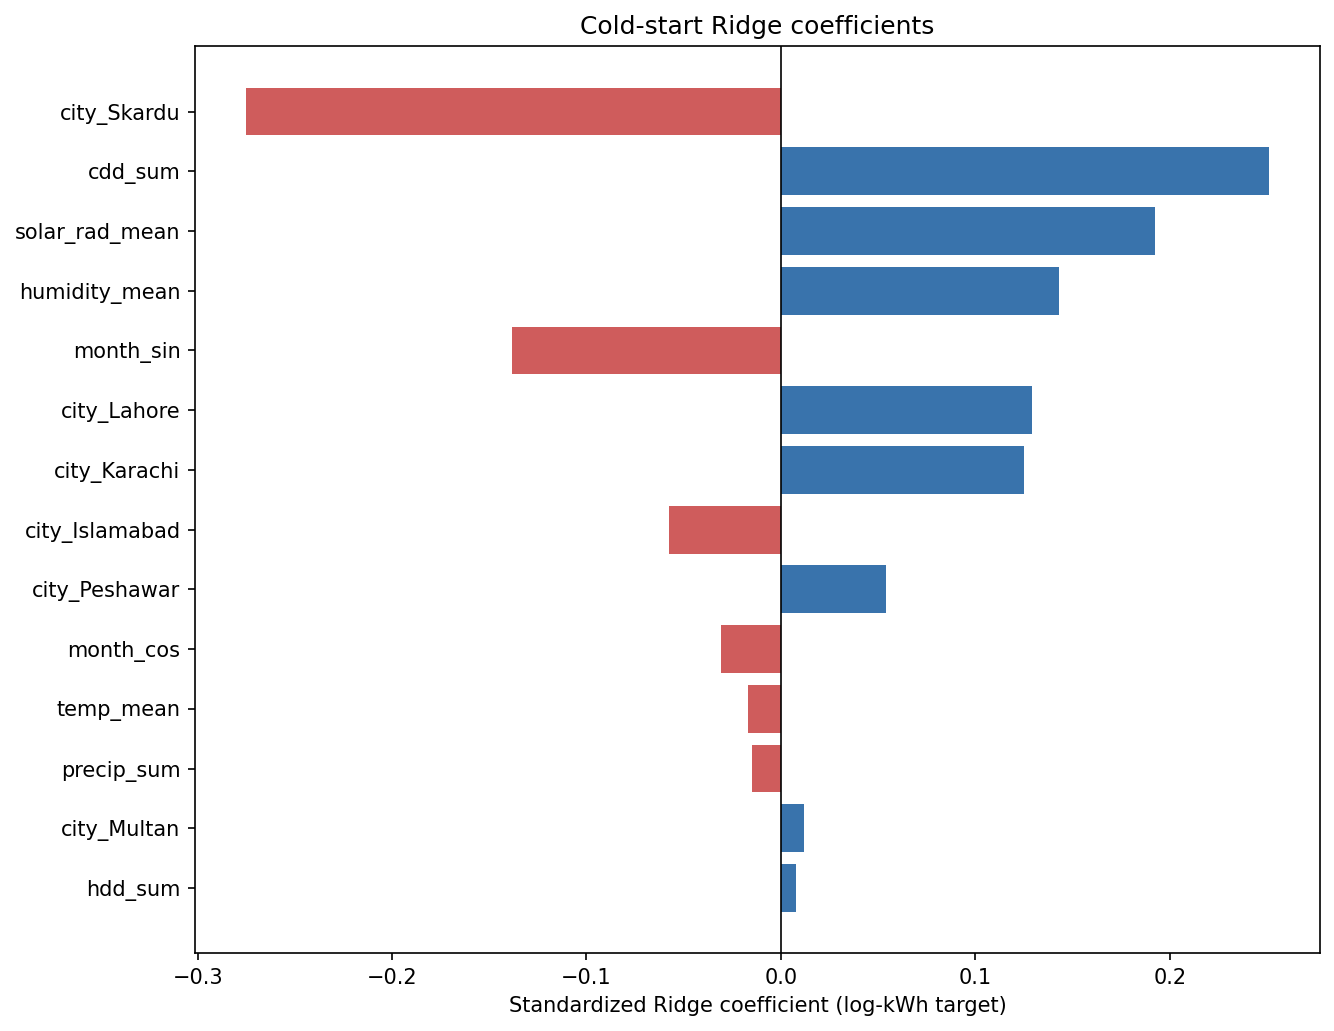

shap_bar_knownhouse.png


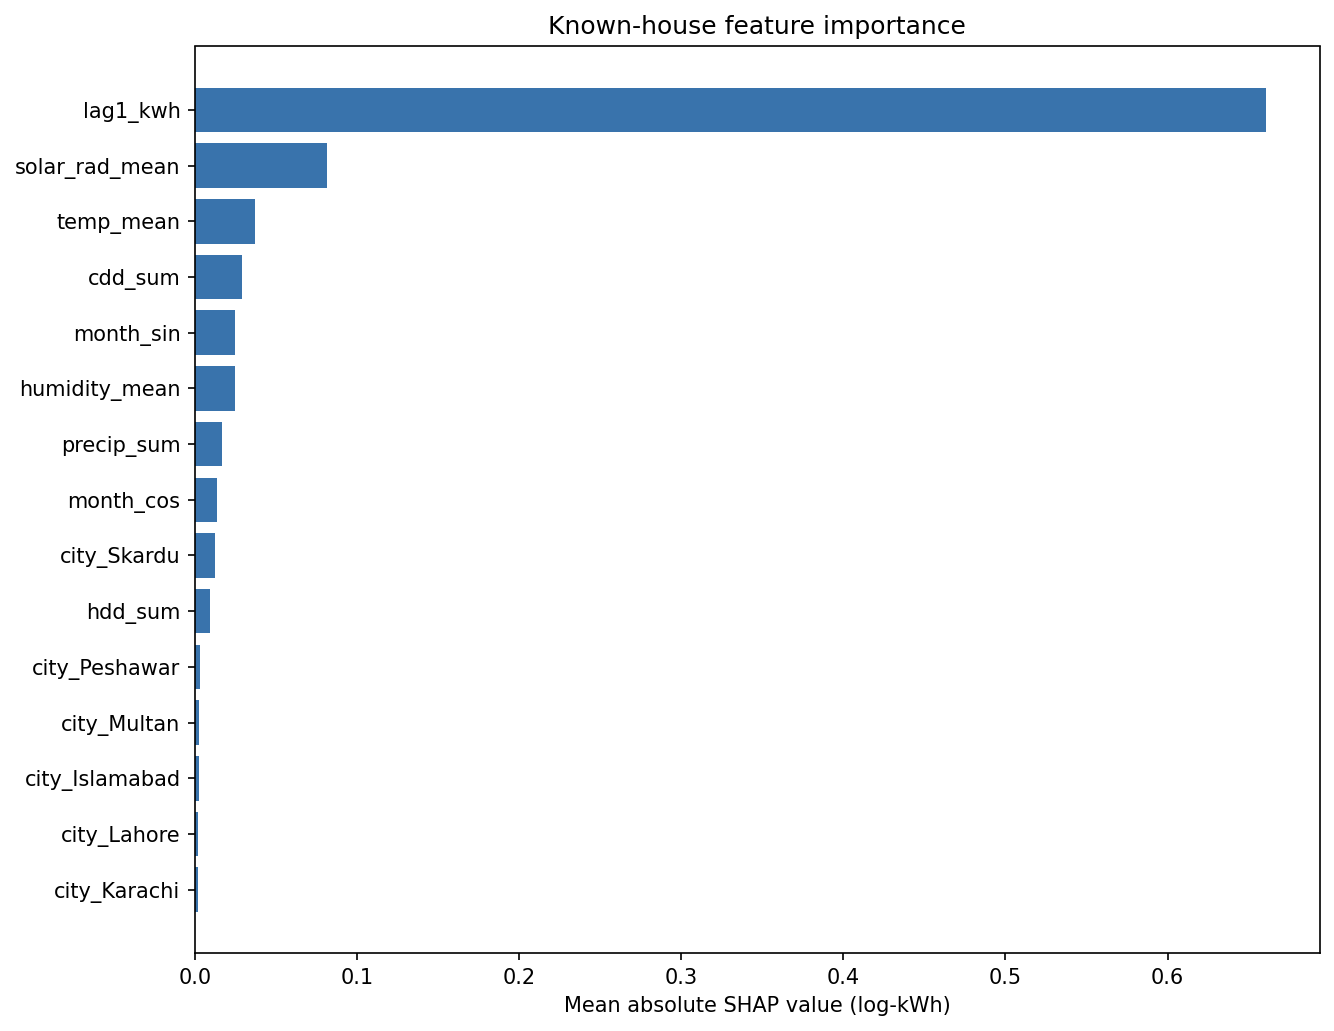

shap_beeswarm_knownhouse.png


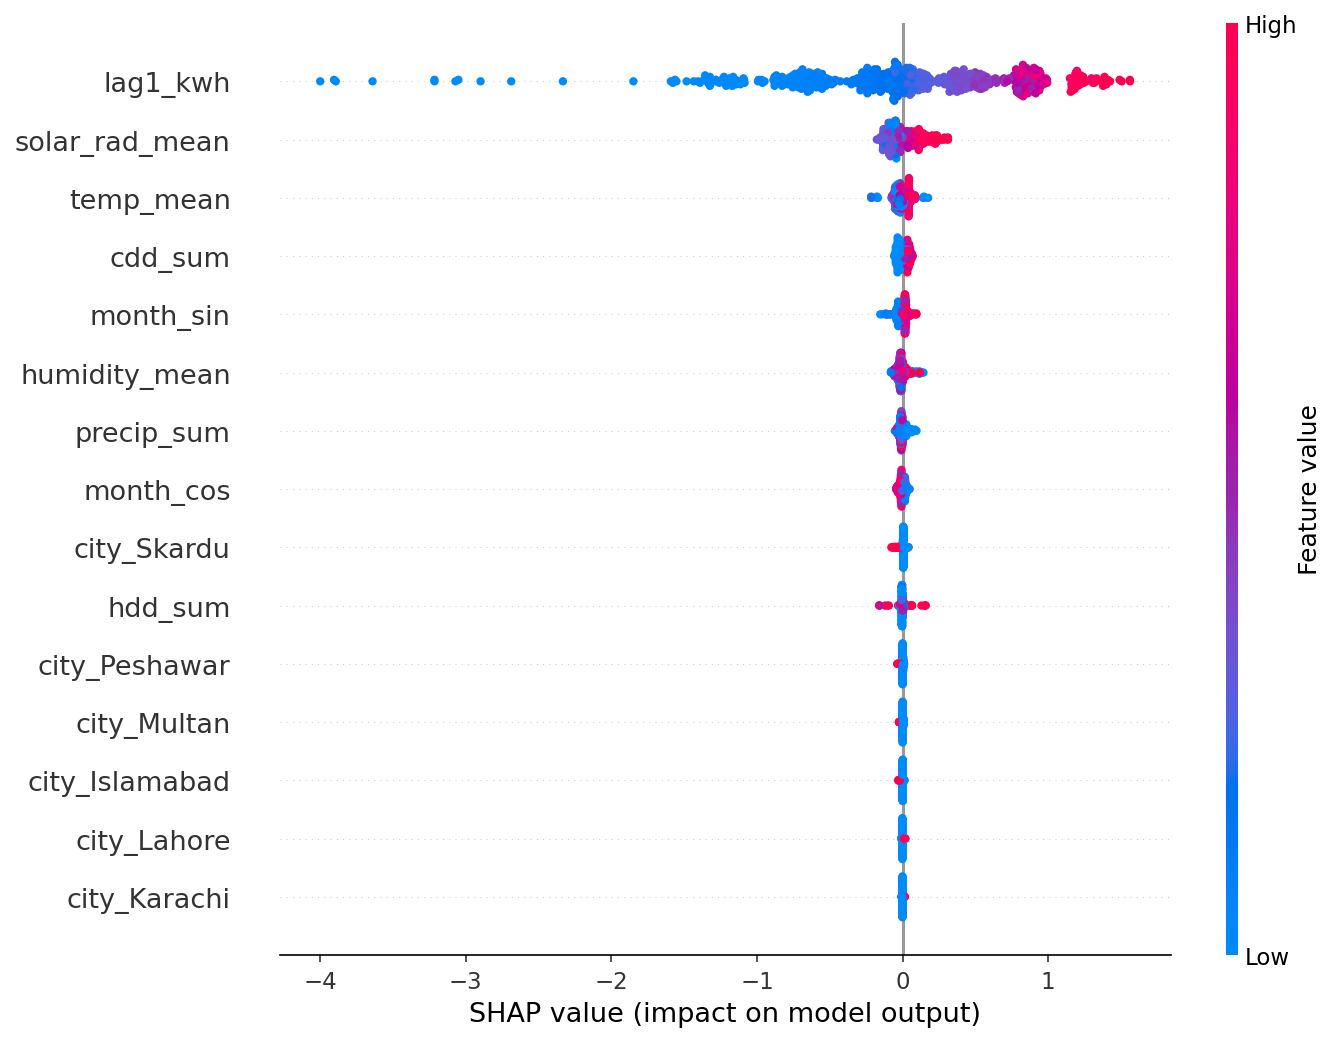

shap_dep_lag1.png


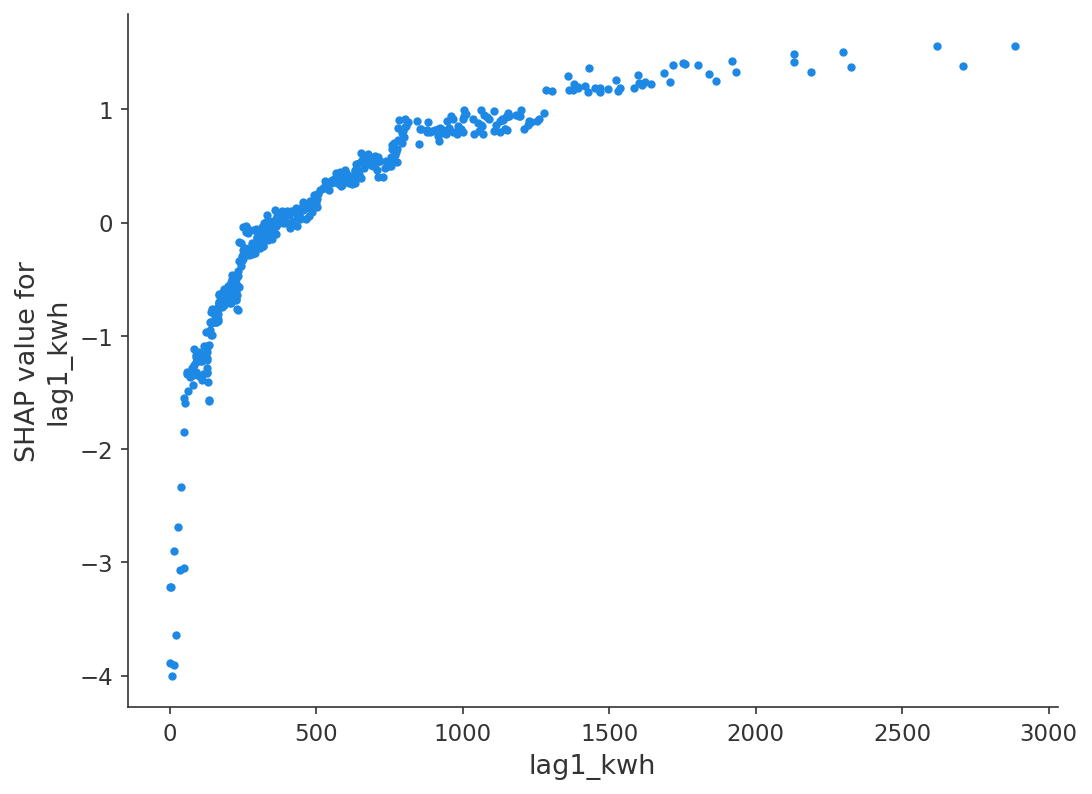

shap_dep_temp.png


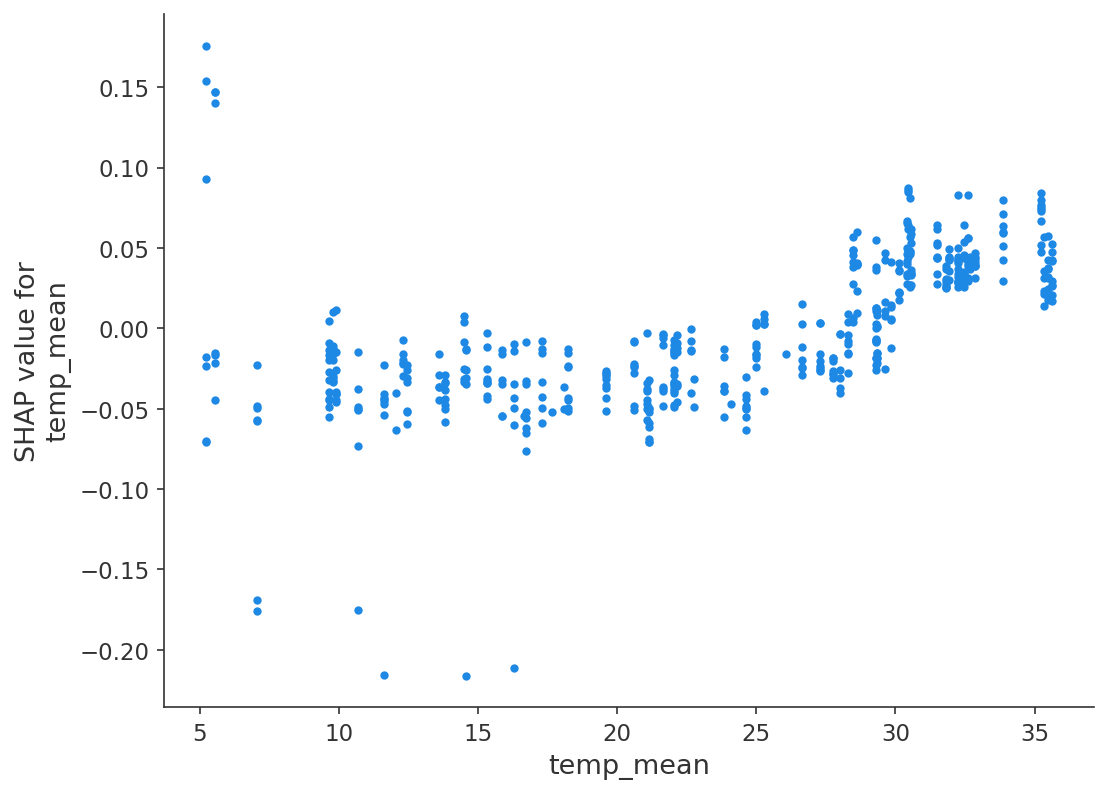

In [14]:
def show_stage8_figures(paths):
    """Display each saved Stage 8 figure in the notebook."""
    for figure_path in paths:
        print(Path(figure_path).name)
        show_img(figure_path)


show_stage8_figures(stage8_results["figure_paths"])


### Findings

Known-house SHAP importance is led by lag1_kwh (71.76%), solar_rad_mean (8.83%), and temp_mean (4.03%).
lag1_kwh has a strongly positive feature-to-SHAP association (Spearman rho = 0.993), so higher prior use generally raises the log-kWh prediction.
temp_mean also has a positive association with its SHAP contribution (rho = 0.724) in these dev known-house rows.
City dummy SHAP shares are small: Skardu is highest at 1.31%, and every other city dummy is at or below 0.30%.
For cold-start Ridge, city_Skardu has the largest absolute city coefficient (-0.275); city_Lahore (+0.129) and city_Karachi (+0.125) follow.
These SHAP values and Ridge coefficients describe the log-kWh model scale, not direct changes in kWh.


### Stage 8 summary

- **Done:** displayed saved dev-only SHAP importance/dependence plots and cold-start Ridge coefficients.
- **Key numbers:** known-house top mean absolute SHAP shares are lag1 71.76%, solar radiation 8.83%, temperature 4.03%; lag1 feature-SHAP Spearman rho is 0.993.
- **Decision:** describe SHAP in log-kWh model-output units, not as causal effects.
- **Issues and limitations:** explanations describe this fitted model and dev sample only.

## Stage 9: Ablation study

### Purpose and method
- Measure how feature groups, individual weather variables, target transformation, data completeness, and model family affect monthly-demand predictions.
- Use only dev houses and five-fold grouped validation by `house_id`; repeat with three seeded house permutations and keep each house wholly within one fold per repeat.
- Fit imputers, scalers, estimators, and city-month baselines using each training fold only; score pooled out-of-fold predictions on the original kWh scale.
- Compare ablations to their full configuration using paired per-repeat RMSE differences; rebuild eligibility and lag features at each completeness threshold.

LightGBM is excluded from the ablation because its native library crashed in this Windows Python 3.13 environment; its results on the same data are in Stage 7.

In [15]:
def load_dev_monthly_for_ablation(min_usable_days=25):
    """Rebuild features for dev-only months at the requested completeness cutoff."""
    monthly = pd.read_parquet(PROCESSED_DIR / "monthly.parquet")
    if "role" not in monthly.columns:
        raise ValueError("monthly.parquet must contain role")
    dev_monthly = monthly.loc[monthly["role"].eq("dev")].copy()
    split = pd.read_csv(PROCESSED_DIR / "house_split.csv")
    if not {"house_id", "role"}.issubset(split.columns):
        raise ValueError("house_split.csv must contain house_id and role")
    holdout_ids = set(split.loc[split["role"].eq("holdout"), "house_id"].astype(int))
    dev_ids = set(split.loc[split["role"].eq("dev"), "house_id"].astype(int))
    dev_monthly["house_id"] = dev_monthly["house_id"].astype(int)
    if set(dev_monthly["house_id"]) & holdout_ids:
        raise AssertionError("Holdout houses leaked into dev monthly rows")
    if set(dev_monthly["house_id"]) - dev_ids:
        raise AssertionError("Monthly rows include houses not marked dev in house_split.csv")
    featured = engineer_monthly_features(
        dev_monthly, min_usable_days=min_usable_days
    )
    modeling = featured.loc[
        featured["n_usable_days"].ge(min_usable_days)
    ].copy().reset_index(drop=True)
    if set(modeling["role"]) != {"dev"}:
        raise AssertionError("Ablation modeling rows must contain dev role only")
    if set(modeling["house_id"]) & holdout_ids:
        raise AssertionError("Holdout houses leaked into ablation modeling rows")
    return modeling, dev_ids, holdout_ids


def ablation_feature_groups(setting):
    """Return the exact feature groups for one modeling setting."""
    groups = {
        "weather": list(WEATHER_FEATURES),
        "season": list(SEASON_FEATURES),
        "city": list(CITY_FEATURES),
    }
    if setting == "B_known-house":
        groups["history"] = list(HISTORY_FEATURES)
    elif setting != "A_cold-start":
        raise ValueError(f"Unknown ablation setting: {setting}")
    return groups


def ablation_features(setting, selected_groups=None, weather_features=None):
    """Combine feature groups in a stable, duplicate-free order."""
    groups = ablation_feature_groups(setting)
    selected_groups = list(groups) if selected_groups is None else selected_groups
    features = []
    for group in selected_groups:
        columns = groups[group]
        if group == "weather" and weather_features is not None:
            columns = weather_features
        features.extend(columns)
    return list(dict.fromkeys(features))


def make_ablation_estimator(model_name, target_transform="log1p"):
    """Recreate the Stage 7 estimator pipelines and target transformation."""
    from sklearn.compose import TransformedTargetRegressor
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import Ridge
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

    if model_name == "Ridge":
        regressor = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge()),
        ])
    elif model_name == "RandomForest":
        regressor = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=300, min_samples_leaf=3, n_jobs=-1,
                random_state=RANDOM_SEED,
            )),
        ])
    elif model_name == "LightGBM":
        import lightgbm as lgb
        regressor = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", lgb.LGBMRegressor(
                n_estimators=300, learning_rate=0.05, num_leaves=15,
                min_child_samples=10, verbose=-1, random_state=RANDOM_SEED,
            )),
        ])
    elif model_name == "XGBoost":
        import xgboost as xgb
        regressor = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", xgb.XGBRegressor(
                n_estimators=300, learning_rate=0.05, max_depth=4,
                objective="reg:squarederror", n_jobs=-1,
                random_state=RANDOM_SEED,
            )),
        ])
    else:
        raise ValueError(f"Unknown model family: {model_name}")
    if target_transform == "raw":
        return regressor
    if target_transform != "log1p":
        raise ValueError(f"Unknown target transform: {target_transform}")
    return TransformedTargetRegressor(
        regressor=regressor, func=np.log1p, inverse_func=np.expm1,
        check_inverse=False,
    )


def ablation_metrics(actual, predicted):
    """Compute pooled metrics on the original kWh scale."""
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    if not len(actual) or not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError("Metrics require non-empty finite actual and predicted values")
    error = predicted - actual
    total = np.sum(actual)
    return {
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "MAE": float(np.mean(np.abs(error))),
        "R2": float(1 - np.sum(error ** 2) / np.sum((actual - np.mean(actual)) ** 2))
              if len(actual) > 1 and np.var(actual) > 0 else float("nan"),
        "WAPE": float(np.sum(np.abs(error)) / total * 100)
                if total != 0 else float("nan"),
    }


def repeated_house_folds(frame, dev_house_ids, holdout_house_ids):
    """Yield train/test positions from three seeded five-fold house partitions."""
    if not set(frame["role"]) <= {"dev"}:
        raise AssertionError("A non-dev row reached grouped cross-validation")
    row_houses = frame["house_id"].astype(int).to_numpy()
    if set(row_houses) & holdout_house_ids:
        raise AssertionError("Holdout house reached grouped cross-validation")
    if set(row_houses) - dev_house_ids:
        raise AssertionError("Unknown house reached grouped cross-validation")
    for repeat in range(3):
        rng = np.random.default_rng(RANDOM_SEED + repeat)
        permutation = rng.permutation(np.asarray(sorted(dev_house_ids), dtype=int))
        house_to_fold = {
            int(house_id): fold
            for fold, houses in enumerate(np.array_split(permutation, 5))
            for house_id in houses
        }
        for fold in range(5):
            test_mask = np.fromiter(
                (house_to_fold[int(house_id)] == fold for house_id in row_houses),
                dtype=bool, count=len(row_houses),
            )
            train_idx = np.flatnonzero(~test_mask)
            test_idx = np.flatnonzero(test_mask)
            train_houses = set(row_houses[train_idx])
            test_houses = set(row_houses[test_idx])
            if train_houses & test_houses:
                raise AssertionError("A house appears in both train and test for a fold")
            if train_houses & holdout_house_ids or test_houses & holdout_house_ids:
                raise AssertionError("Holdout house appears in a training or validation fold")
            if not len(train_idx) or not len(test_idx):
                raise ValueError("A grouped CV fold has no train or test rows")
            yield repeat, fold, train_idx, test_idx


def run_repeated_ablation_cv(frame, features, model_name, dev_house_ids,
                             holdout_house_ids, target_transform="log1p"):
    """Generate pooled out-of-fold predictions and metrics for three repeats."""
    frame = frame.reset_index(drop=True).copy()
    if not features and model_name not in ("CityMonthMean", "Persistence"):
        raise ValueError("Estimator ablation requires at least one feature")
    actual = frame["monthly_kwh"].to_numpy(dtype=float)
    if not np.isfinite(actual).all() or (actual <= -1).any():
        raise ValueError("monthly_kwh must be finite and greater than -1")
    repeat_predictions = {repeat: np.full(len(frame), np.nan) for repeat in range(3)}
    for repeat, fold, train_idx, test_idx in repeated_house_folds(
            frame, dev_house_ids, holdout_house_ids):
        train = frame.iloc[train_idx]
        test = frame.iloc[test_idx]
        if model_name == "CityMonthMean":
            train_month = train["year_month"].map(lambda value: value.month)
            test_month = test["year_month"].map(lambda value: value.month)
            train_keys = pd.DataFrame({"city": train["city"], "month": train_month})
            test_keys = pd.DataFrame({"city": test["city"], "month": test_month})
            train_means = train.assign(_month=train_month).groupby(
                ["city", "_month"], observed=True
            )["monthly_kwh"].mean()
            fallback = float(train["monthly_kwh"].mean())
            test_predictions = np.array([
                train_means.get((city, month), fallback)
                for city, month in zip(test_keys["city"], test_keys["month"])
            ], dtype=float)
        elif model_name == "Persistence":
            if "lag1_kwh" not in test.columns or test["lag1_kwh"].isna().any():
                raise ValueError("Persistence requires a valid lag1_kwh for every test row")
            test_predictions = test["lag1_kwh"].to_numpy(dtype=float)
        else:
            model = make_ablation_estimator(model_name, target_transform)
            model.fit(train[features], train["monthly_kwh"])
            test_predictions = model.predict(test[features])
        repeat_predictions[repeat][test_idx] = test_predictions
    metrics = []
    for repeat in range(3):
        predictions = repeat_predictions[repeat]
        if not np.isfinite(predictions).all():
            raise AssertionError("Each repeat must produce one OOF prediction per row")
        metrics.append(ablation_metrics(actual, predictions))
    return metrics


def summarize_ablation(setting, model, label, frame, repeat_metrics, reference=None,
                       extra=None):
    """Summarize repeat metrics and paired RMSE changes versus a reference."""
    row = {"setting": setting, "model": model, "ablation": label,
           "n_rows": int(len(frame))}
    for metric in ("RMSE", "MAE", "R2", "WAPE"):
        values = np.asarray([item[metric] for item in repeat_metrics], dtype=float)
        row[f"{metric}_mean"] = float(np.mean(values))
        row[f"{metric}_std"] = float(np.std(values, ddof=1))
    if reference is None:
        changes = np.zeros(3, dtype=float)
    else:
        changes = np.asarray([item["RMSE"] for item in repeat_metrics]) - np.asarray(
            [item["RMSE"] for item in reference]
        )
    row["RMSE_change_mean"] = float(np.mean(changes))
    row["RMSE_change_std"] = float(np.std(changes, ddof=1))
    if extra:
        row.update(extra)
    return row


Feature-group ablations

,setting,model,ablation,n_rows,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,WAPE_mean,WAPE_std,RMSE_change_mean,RMSE_change_std,target_transform
0,A_cold-start,Ridge,full,567,426.5494,12.5233,285.8598,14.4572,0.1795,0.0485,50.6911,2.5637,0.0000,0.0000,log1p
1,A_cold-start,Ridge,remove weather,567,434.0193,11.7685,290.7282,14.5798,0.1506,0.0464,51.5544,2.5854,7.4699,0.8680,log1p
2,A_cold-start,Ridge,remove season,567,426.2418,12.7526,285.8181,14.1857,0.1807,0.0494,50.6837,2.5155,-0.3075,0.2313,log1p
3,A_cold-start,Ridge,remove city,567,418.0830,2.8475,275.2170,5.6394,0.2122,0.0107,48.8038,1.0000,-8.4663,9.7312,log1p
4,A_cold-start,Ridge,only weather,567,417.5694,2.2855,273.3620,2.5074,0.2141,0.0086,48.4749,0.4446,-8.9799,10.3520,log1p
5,A_cold-start,Ridge,only season,567,453.5373,3.2909,305.0717,3.1896,0.0729,0.0135,54.0979,0.5656,26.9879,14.3914,log1p
6,A_cold-start,Ridge,only city,567,482.5121,6.7355,327.2476,11.2161,-0.0495,0.0294,58.0304,1.9889,55.9628,5.8150,log1p
7,A_cold-start,RandomForest,full,567,427.6898,10.0750,287.9853,12.9783,0.1753,0.0391,51.0680,2.3014,0.0000,0.0000,log1p
8,A_cold-start,RandomForest,remove weather,567,427.8875,9.9786,287.6550,13.2036,0.1745,0.0387,51.0095,2.3414,0.1977,0.2401,log1p
9,A_cold-start,RandomForest,remove season,567,427.6884,10.0037,287.9620,12.8810,0.1753,0.0388,51.0639,2.2842,-0.0014,0.0736,log1p


Weather-variable ablations


,setting,model,ablation,n_rows,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,WAPE_mean,WAPE_std,RMSE_change_mean,RMSE_change_std,target_transform
0,A_cold-start,Ridge,remove temp_mean,567,426.4512,12.6820,285.8001,14.4819,0.1799,0.0491,50.6805,2.5680,-0.0982,0.2293,log1p
1,A_cold-start,Ridge,remove cdd_sum,567,428.9314,12.4098,287.9027,14.8669,0.1703,0.0484,51.0534,2.6363,2.3821,0.1251,log1p
2,A_cold-start,Ridge,remove hdd_sum,567,426.5135,12.4898,285.7747,14.4394,0.1796,0.0484,50.6760,2.5605,-0.0358,0.0477,log1p
3,A_cold-start,Ridge,remove humidity_mean,567,427.7269,12.1498,286.9476,14.0357,0.1750,0.0472,50.8840,2.4889,1.1776,0.7689,log1p
4,A_cold-start,Ridge,remove precip_sum,567,426.5360,12.0820,285.9566,14.2692,0.1796,0.0468,50.7083,2.5303,-0.0134,0.4780,log1p
5,A_cold-start,Ridge,remove solar_rad_mean,567,426.7711,12.7099,285.8200,14.3905,0.1786,0.0493,50.6841,2.5518,0.2217,0.2590,log1p
6,A_cold-start,Ridge,temperature only,567,434.4322,11.7825,290.9977,14.6908,0.1490,0.0465,51.6022,2.6051,7.8829,1.0933,log1p
7,A_cold-start,RandomForest,remove temp_mean,567,427.7591,10.0773,288.0437,12.9566,0.1750,0.0391,51.0784,2.2976,0.0693,0.0221,log1p
8,A_cold-start,RandomForest,remove cdd_sum,567,427.7619,10.0539,288.0355,12.9694,0.1750,0.0390,51.0769,2.2999,0.0721,0.0213,log1p
9,A_cold-start,RandomForest,remove hdd_sum,567,427.6847,10.0786,287.9997,13.0003,0.1753,0.0391,51.0706,2.3053,-0.0051,0.0047,log1p


Target-transform comparison


,setting,model,ablation,n_rows,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,WAPE_mean,WAPE_std,RMSE_change_mean,RMSE_change_std,target_transform
0,A_cold-start,Ridge,log1p,567,426.5494,12.5233,285.8598,14.4572,0.1795,0.0485,50.6911,2.5637,0.0000,0.0000,log1p
1,A_cold-start,Ridge,raw,567,420.6000,14.7870,302.0451,15.6986,0.2020,0.0565,53.5612,2.7838,-5.9494,2.9968,raw
2,B_known-house,RandomForest,log1p,497,234.8461,5.0285,142.4373,2.9554,0.7639,0.0102,24.4256,0.5068,0.0000,0.0000,log1p
3,B_known-house,RandomForest,raw,497,228.6499,3.6983,143.9461,2.1656,0.7762,0.0073,24.6844,0.3714,-6.1962,1.3322,raw


... (2 outputs left out)

Model family and baseline comparison


,setting,model,ablation,n_rows,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,WAPE_mean,WAPE_std,RMSE_change_mean,RMSE_change_std,target_transform
0,A_cold-start,Ridge,full feature set,567,426.5494,12.5233,285.8598,14.4572,0.1795,0.0485,50.6911,2.5637,-1.1404,2.6252,log1p
1,A_cold-start,RandomForest,full feature set,567,427.6898,10.0750,287.9853,12.9783,0.1753,0.0391,51.0680,2.3014,0.0000,0.0000,log1p
2,A_cold-start,XGBoost,full feature set,567,429.5024,10.5256,289.3538,13.0115,0.1682,0.0410,51.3107,2.3073,1.8126,0.6694,log1p
3,A_cold-start,CityMonthMean,train-fold city-month mean,567,431.6571,14.3027,306.5301,13.4175,0.1596,0.0559,54.3566,2.3793,3.9673,4.5108,NaN
4,B_known-house,Ridge,full feature set,497,692.6741,56.5225,249.7718,5.9893,-1.0626,0.3342,42.8317,1.0271,457.8280,60.8932,log1p
5,B_known-house,RandomForest,full feature set,497,234.8461,5.0285,142.4373,2.9554,0.7639,0.0102,24.4256,0.5068,0.0000,0.0000,log1p
6,B_known-house,XGBoost,full feature set,497,237.7821,1.3277,145.0102,2.8183,0.7580,0.0027,24.8668,0.4833,2.9360,4.5856,log1p
7,B_known-house,CityMonthMean,train-fold city-month mean,497,446.4315,14.3125,318.2032,14.3386,0.1464,0.0550,54.5666,2.4588,211.5854,18.2431,NaN
8,B_known-house,Persistence,previous-month kWh,497,266.8418,0.0000,165.9583,0.0000,0.6953,0.0000,28.4591,0.0000,31.9957,5.0285,NaN


Rows per completeness threshold


,setting,min_usable_days,n_rows
0,A_cold-start,20,592
1,A_cold-start,25,567
2,A_cold-start,28,540
3,B_known-house,20,526
4,B_known-house,25,497
5,B_known-house,28,460


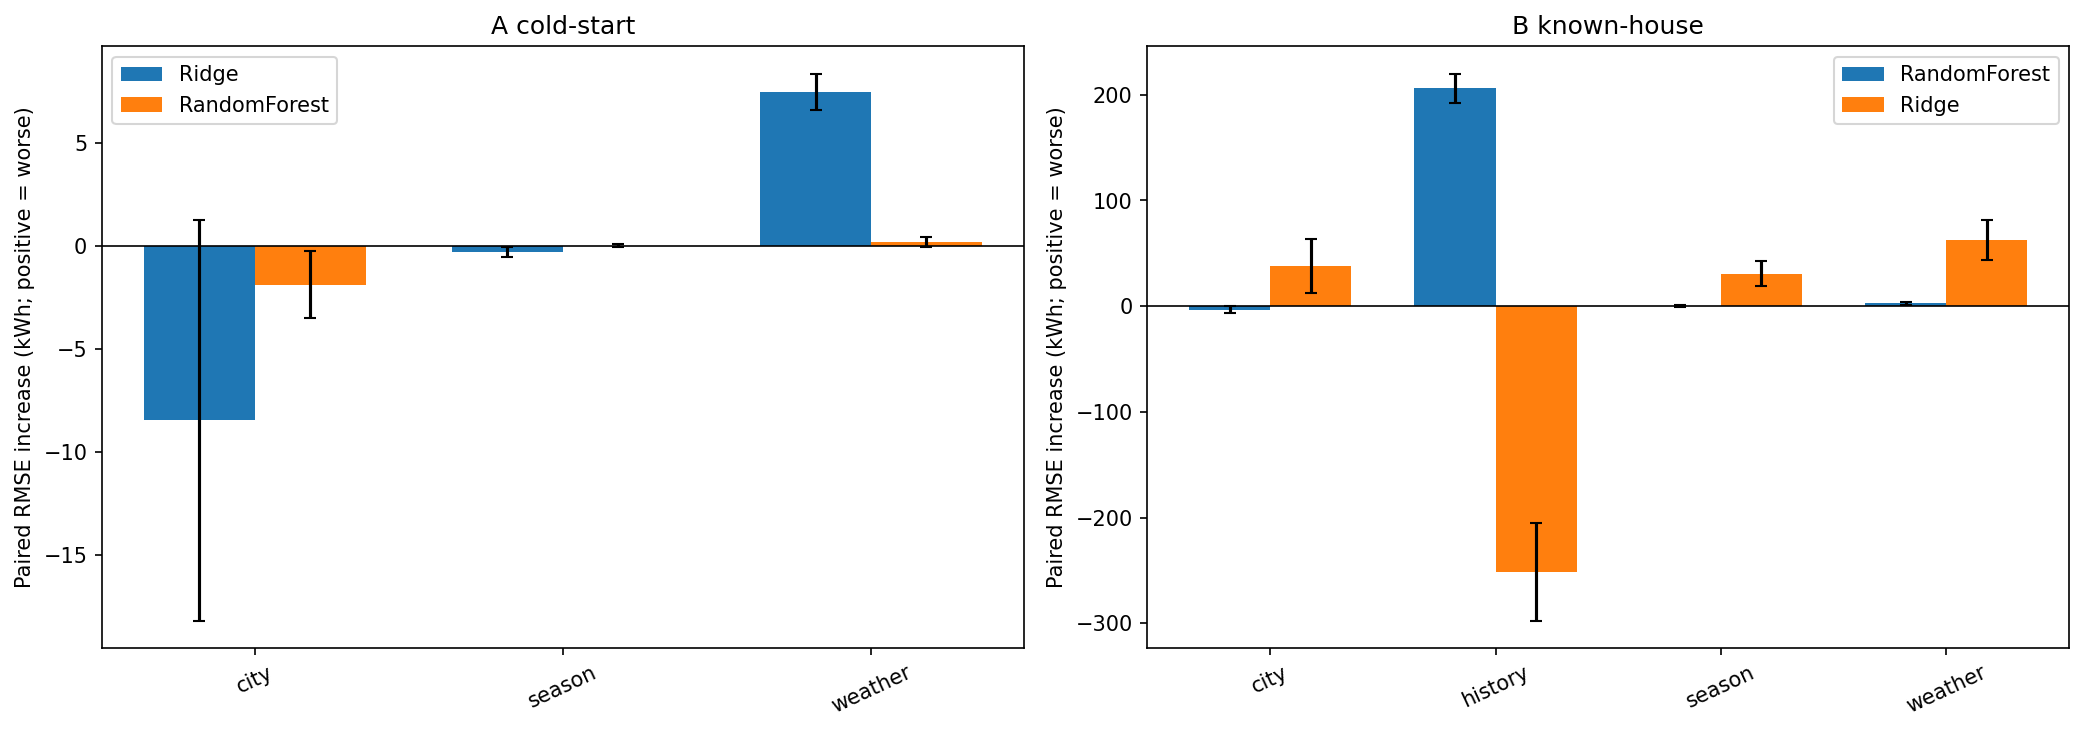

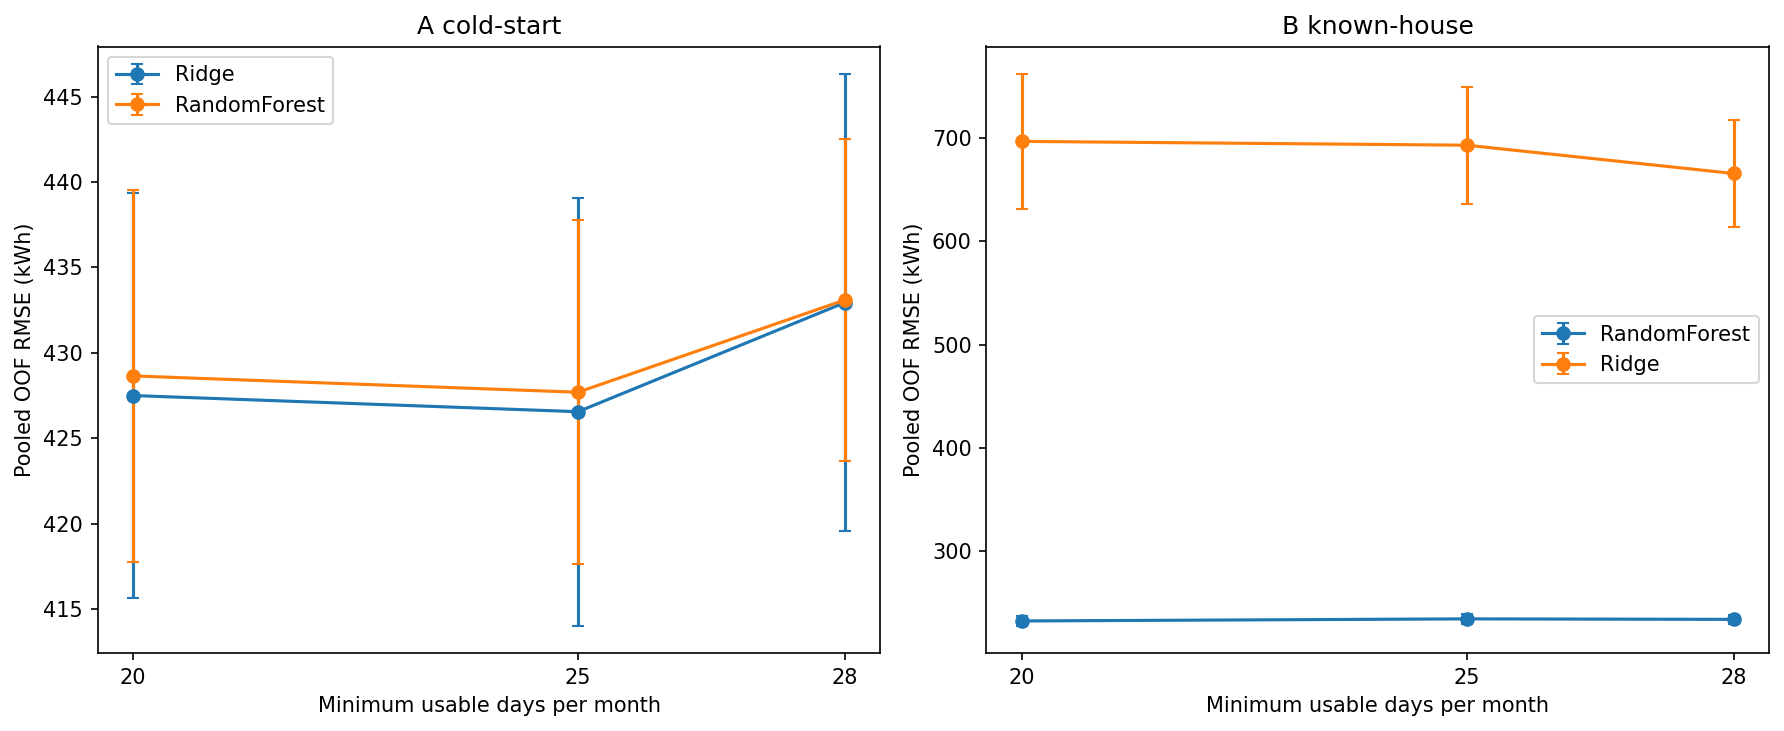

In [16]:
def run_ablation_study():
    """Run all requested dev-only ablations and save compact tables and figures."""
    import matplotlib.pyplot as plt
    output_dir = Path(REPORT_DIRS["ablation"])
    figures_dir = output_dir / "figures"
    output_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    thresholds = (20, 25, 28)
    base, dev_house_ids, holdout_house_ids = load_dev_monthly_for_ablation(25)
    group_rows, weather_rows, target_rows, threshold_rows, model_rows = [], [], [], [], []
    reference_cache = {}
    settings = {
        "A_cold-start": ("Ridge", "RandomForest"),
        "B_known-house": ("RandomForest", "Ridge"),
    }

    def setting_frame(frame, setting):
        selected = frame if setting == "A_cold-start" else frame.loc[frame["lag1_kwh"].notna()].copy()
        if selected.empty:
            raise ValueError(f"No eligible rows for {setting}")
        return selected.reset_index(drop=True)

    def evaluate(frame, setting, model, label, features, transform="log1p", reference=None):
        metrics = run_repeated_ablation_cv(
            frame, features, model, dev_house_ids, holdout_house_ids, transform
        )
        return summarize_ablation(
            setting, model, label, frame, metrics, reference,
            extra={"target_transform": transform},
        ), metrics

    for setting, models in settings.items():
        groups = ablation_feature_groups(setting)
        setting_data = setting_frame(base, setting)
        full_features = ablation_features(setting)
        for model in models:
            full_row, full_metrics = evaluate(setting_data, setting, model, "full",
                                              full_features)
            group_rows.append(full_row)
            reference_cache[("group", setting, model)] = full_metrics
            selected_configs = [(f"remove {group}", [name for name in groups if name != group])
                                for group in groups]
            selected_configs.extend((f"only {group}", [group]) for group in groups)
            for label, selected_groups in selected_configs:
                features = ablation_features(setting, selected_groups)
                data = setting_data
                if setting == "B_known-house":
                    if selected_groups == ["history"]:
                        data = setting_data.loc[setting_data["lag1_kwh"].notna()].copy()
                    elif "history" not in selected_groups:
                        data = setting_data
                row, _ = evaluate(data, setting, model, label, features,
                                  reference=full_metrics)
                group_rows.append(row)

            for variable in WEATHER_FEATURES:
                reduced_weather = [name for name in WEATHER_FEATURES if name != variable]
                features = ablation_features(setting, weather_features=reduced_weather)
                row, _ = evaluate(setting_data, setting, model, f"remove {variable}",
                                  features, reference=full_metrics)
                weather_rows.append(row)
            temp_features = ["temp_mean", *SEASON_FEATURES, *CITY_FEATURES]
            if setting == "B_known-house":
                temp_features += HISTORY_FEATURES
            row, _ = evaluate(setting_data, setting, model, "temperature only",
                              temp_features, reference=full_metrics)
            weather_rows.append(row)

    # Compare adding history on the same known-house rows to isolate its contribution.
    known_frame = base.loc[base["lag1_kwh"].notna()].copy().reset_index(drop=True)
    for model in ("RandomForest", "Ridge"):
        without_history = run_repeated_ablation_cv(
            known_frame, ablation_features("A_cold-start"), model,
            dev_house_ids, holdout_house_ids,
        )
        with_history = run_repeated_ablation_cv(
            known_frame, ablation_features("B_known-house"), model,
            dev_house_ids, holdout_house_ids,
        )
        group_rows.append(summarize_ablation(
            "B_known-house", model, "add history (matched known-house rows)",
            known_frame, with_history, reference=without_history,
        ))

    for setting, model in (("A_cold-start", "Ridge"),
                           ("B_known-house", "RandomForest")):
        data = setting_frame(base, setting)
        features = ablation_features(setting)
        log_metrics = run_repeated_ablation_cv(
            data, features, model, dev_house_ids, holdout_house_ids, "log1p"
        )
        for transform in ("log1p", "raw"):
            metrics = log_metrics if transform == "log1p" else run_repeated_ablation_cv(
                data, features, model, dev_house_ids, holdout_house_ids, "raw"
            )
            target_rows.append(summarize_ablation(
                setting, model, transform, data, metrics, reference=log_metrics,
                extra={"target_transform": transform},
            ))

    threshold_cache = {}
    threshold_count_rows = []
    for threshold in thresholds:
        threshold_data, _, _ = load_dev_monthly_for_ablation(threshold)
        threshold_count_rows.append({
            "min_usable_days": threshold,
            "A_cold-start_rows": len(threshold_data),
            "B_known-house_rows": int(threshold_data["lag1_kwh"].notna().sum()),
        })
        for setting, models in settings.items():
            data = setting_frame(threshold_data, setting)
            features = ablation_features(setting)
            for model in models:
                metrics = run_repeated_ablation_cv(
                    data, features, model, dev_house_ids, holdout_house_ids
                )
                threshold_cache[(threshold, setting, model)] = metrics
    for setting, models in settings.items():
        for model in models:
            reference = threshold_cache[(25, setting, model)]
            for threshold in thresholds:
                data, _, _ = load_dev_monthly_for_ablation(threshold)
                data = setting_frame(data, setting)
                threshold_rows.append(summarize_ablation(
                    setting, model, f"min usable days {threshold}", data,
                    threshold_cache[(threshold, setting, model)], reference=reference,
                    extra={"min_usable_days": threshold},
                ))

    for setting in settings:
        data = setting_frame(base, setting)
        features = ablation_features(setting)
        full_rf = run_repeated_ablation_cv(
            data, features, "RandomForest", dev_house_ids, holdout_house_ids
        )
        model_names = ("Ridge", "RandomForest", "XGBoost")
        for model in model_names:
            if model == "RandomForest":
                metrics = full_rf
            else:
                metrics = run_repeated_ablation_cv(
                    data, features, model, dev_house_ids, holdout_house_ids
                )
            model_rows.append(summarize_ablation(
                setting, model, "full feature set", data, metrics, reference=full_rf,
                extra={"target_transform": "log1p"},
            ))
        city_month = run_repeated_ablation_cv(
            data, [], "CityMonthMean", dev_house_ids, holdout_house_ids
        )
        model_rows.append(summarize_ablation(
            setting, "CityMonthMean", "train-fold city-month mean", data,
            city_month, reference=full_rf,
        ))
        if setting == "B_known-house":
            persistence = run_repeated_ablation_cv(
                data, ["lag1_kwh"], "Persistence", dev_house_ids, holdout_house_ids
            )
            model_rows.append(summarize_ablation(
                setting, "Persistence", "previous-month kWh", data,
                persistence, reference=full_rf,
            ))

    tables = {
        "groups": pd.DataFrame(group_rows),
        "weather": pd.DataFrame(weather_rows),
        "target": pd.DataFrame(target_rows),
        "threshold": pd.DataFrame(threshold_rows),
        "models": pd.DataFrame(model_rows),
        "threshold_counts": pd.DataFrame(threshold_count_rows),
    }
    filenames = {
        "groups": "ablation_groups.csv",
        "weather": "ablation_weather.csv",
        "target": "ablation_target.csv",
        "threshold": "ablation_threshold.csv",
        "models": "ablation_models.csv",
    }
    for key, filename in filenames.items():
        tables[key].to_csv(output_dir / filename, index=False)

    removed = tables["groups"].loc[
        tables["groups"]["ablation"].str.startswith("remove ")
    ]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
    for ax, setting in zip(axes, settings):
        subset = removed.loc[removed["setting"].eq(setting)]
        labels = sorted(subset["ablation"].unique())
        positions = np.arange(len(labels))
        width = 0.36
        for offset, model in enumerate(settings[setting]):
            model_rows = subset.loc[subset["model"].eq(model)].set_index("ablation")
            vals = [model_rows.loc[label, "RMSE_change_mean"] for label in labels]
            errs = [model_rows.loc[label, "RMSE_change_std"] for label in labels]
            ax.bar(positions + (offset - 0.5) * width, vals, width,
                   yerr=errs, capsize=3, label=model)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks(positions, [label.replace("remove ", "") for label in labels], rotation=25)
        ax.set_ylabel("Paired RMSE increase (kWh; positive = worse)")
        ax.set_title(setting.replace("_", " "))
        ax.legend()
    fig.tight_layout()
    group_figure = figures_dir / "ablation_groups.png"
    fig.savefig(group_figure, dpi=150, bbox_inches="tight")
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)
    count_table = tables["threshold_counts"]
    for ax, setting in zip(axes, settings):
        for model in settings[setting]:
            subset = tables["threshold"].loc[
                tables["threshold"]["setting"].eq(setting)
                & tables["threshold"]["model"].eq(model)
            ].sort_values("min_usable_days")
            ax.errorbar(subset["min_usable_days"], subset["RMSE_mean"],
                        yerr=subset["RMSE_std"], marker="o", capsize=3, label=model)
        ax.set_xticks(thresholds)
        ax.set_xlabel("Minimum usable days per month")
        ax.set_ylabel("Pooled OOF RMSE (kWh)")
        ax.set_title(setting.replace("_", " "))
        ax.legend()
    fig.tight_layout()
    threshold_figure = figures_dir / "ablation_threshold.png"
    fig.savefig(threshold_figure, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print("Dev-only leakage checks passed; 53 dev houses, 6 holdout houses excluded.")
    print("Modeling rows by completeness threshold:")
    print(tables["threshold_counts"].to_string(index=False))
    print("Saved ablation tables:")
    for filename in filenames.values():
        print(f"  {output_dir / filename}")
    print("Saved ablation figures:")
    print(f"  {group_figure}\n  {threshold_figure}")
    return tables


def display_ablation_tables(tables):
    """Display every requested ablation table compactly."""
    for key, title in (
        ("groups", "Feature-group ablations"),
        ("weather", "Weather-variable ablations"),
        ("target", "Target-transform comparison"),
        ("threshold", "Month-completeness threshold comparison"),
        ("models", "Model family and baseline comparison"),
        ("threshold_counts", "Rows per completeness threshold"),
    ):
        print(title)
        display(tables[key].round(4))


if RUN_HEAVY:
    ablation_tables = run_ablation_study()
else:
    output_dir = Path(REPORT_DIRS["ablation"])
    ablation_tables = {
        "groups": pd.read_csv(output_dir / "ablation_groups.csv"),
        "weather": pd.read_csv(output_dir / "ablation_weather.csv"),
        "target": pd.read_csv(output_dir / "ablation_target.csv"),
        "threshold": pd.read_csv(output_dir / "ablation_threshold.csv"),
        "models": pd.read_csv(output_dir / "ablation_models.csv"),
    }
    ablation_tables["threshold_counts"] = (
        ablation_tables["threshold"].groupby(["setting", "min_usable_days"], as_index=False)
        ["n_rows"].first()
    )
display_ablation_tables(ablation_tables)
for name in ("ablation_groups.png", "ablation_threshold.png"):
    show_img(Path(REPORT_DIRS["ablation"]) / "figures" / name)


### Stage 9 summary

- **Done:** ran three-repeat dev-only grouped ablations and loaded all five tables plus both saved figures.
- **Key numbers:** removing history raises known-house RF RMSE by 206.10 kWh on matched rows; adding it reduces RMSE by 206.10 kWh. Removing weather raises RF RMSE by 2.57 kWh; removing city lowers it by 3.28 kWh.
- **Decision:** history is valuable for known-house RF; retain weather context, and exclude LightGBM from this Windows/Python 3.13 ablation while preserving its Stage 7 results.
- **Issues and limitations:** Ridge with history is unstable in these saved CV results; all ablations are dev results, not holdout tuning.

## Stage 10: Waste / anomaly detection

### Purpose and method

### Purpose
- Identify unusually high electricity use beyond what weather, calendar, and recent household consumption predict, addressing RQ3 with interpretable waste flags.

### Method
- Fit a past-feature Random Forest expected-consumption model and compare robust city-level residual thresholds, Isolation Forest, their intersection, and an Isolation Forest sensitivity variant with daily summary features.
- Evaluate only dev houses using house-grouped out-of-fold predictions; inject known increases into held-out dev days for quantitative metrics, then separately summarize real unlabeled dev behavior.
- Refit the expected model and combined detector on all dev houses for the later app; the holdout remains reserved for Stage 11.

### Decisions
- The high side only is waste; days with outages of at least 240 minutes are never flagged.
- The deployable detector uses residual and previous-week relative level; same-day summary features are retained only for an offline comparison.

### Limitations
- Precision, recall, F1, and false-positive rates measure synthetic injections, not verified real waste labels; real flagged-day and monthly excess summaries are descriptive, not ground truth.
- Past-week features require at least four usable days in the prior seven calendar days, and all results depend on that eligibility filter and the dev sample.

In [17]:
ANOMALY_EXPECTED_FEATURES = [
    "prev7_mean", "prev_day_kwh", "temp_mean", "cdd", "hdd",
    "humidity_mean", "precip_sum", "wind_mean", "solar_rad_mean", "dow",
    "month_sin", "month_cos",
] + [f"city_{city}" for city in CITIES]
ANOMALY_IF_FEATURES = ["residual", "relative_level"]
ANOMALY_EXTRA_IF_FEATURES = ANOMALY_IF_FEATURES + ["night_day_ratio", "max_mean_ratio"]
ANOMALY_DETECTORS = (
    "Statistical threshold", "Isolation Forest", "Combined",
    "Isolation Forest + daily features",
)
ANOMALY_CONTAMINATIONS = (0.02, 0.05, 0.10)


def load_dev_daily_for_anomalies():
    """Load usable dev rows and assert that no holdout house enters analysis."""
    daily = pd.read_parquet(PROCESSED_DIR / "daily.parquet")
    required = {
        "date", "city", "house_id", "usable", "kwh", "temp_mean", "cdd", "hdd",
        "humidity_mean", "precip_sum", "wind_mean", "solar_rad_mean", "dow",
        "outage_min", "night_mean_kw", "day_mean_kw", "max_kw", "mean_kw",
    }
    missing = sorted(required - set(daily.columns))
    if missing:
        raise ValueError(f"daily.parquet is missing required columns: {missing}")
    split = pd.read_csv(PROCESSED_DIR / "house_split.csv")
    if not {"city", "house_id", "role"}.issubset(split.columns):
        raise ValueError("house_split.csv must contain city, house_id, and role")
    split = split.copy()
    split["house_id"] = split["house_id"].astype(int)
    split["city"] = split["city"].astype(str)
    if split.duplicated(["city", "house_id"]).any():
        raise ValueError("house_split.csv has duplicate city/house identifiers")
    roles = split.set_index(["city", "house_id"])["role"]
    daily = daily.copy()
    daily["city"] = daily["city"].astype(str)
    daily["house_id"] = daily["house_id"].astype(int)
    daily["date"] = pd.to_datetime(daily["date"], errors="raise").dt.normalize()
    daily["role"] = [roles.get((city, house_id), "unknown")
                     for city, house_id in zip(daily["city"], daily["house_id"])]
    holdout_keys = set(map(tuple, split.loc[split["role"].eq("holdout"),
                                           ["city", "house_id"]].to_numpy()))
    dev_keys = set(map(tuple, split.loc[split["role"].eq("dev"),
                                       ["city", "house_id"]].to_numpy()))
    observed_keys = set(map(tuple, daily[["city", "house_id"]].drop_duplicates().to_numpy()))
    if observed_keys - (dev_keys | holdout_keys):
        raise AssertionError("Daily input contains a house absent from house_split.csv")
    daily = daily.loc[daily["role"].eq("dev")].copy()
    daily["usable"] = daily["usable"].astype(bool)
    if daily.duplicated(["city", "house_id", "date"]).any():
        raise ValueError("daily.parquet contains duplicate house-date rows")
    daily = daily.reset_index(drop=True)
    daily["_row_id"] = np.arange(len(daily), dtype=np.int64)
    if set(map(tuple, daily.loc[daily["role"].eq("holdout"),
                                ["city", "house_id"]].to_numpy())):
        raise AssertionError("Holdout houses leaked into dev daily rows")
    return daily, dev_keys, holdout_keys


def build_daily_anomaly_features(daily, injected_factors=None):
    """Add past-only house features; optional factors alter only selected days."""
    frame = daily.copy()
    frame["kwh"] = pd.to_numeric(frame["kwh"], errors="coerce")
    if injected_factors:
        selected = frame["_row_id"].isin(injected_factors)
        factors = frame.loc[selected, "_row_id"].map(injected_factors).astype("float64")
        for column in ("kwh", "night_mean_kw", "day_mean_kw", "max_kw", "mean_kw"):
            frame[column] = pd.to_numeric(frame[column], errors="coerce").astype("float64")
            frame.loc[selected, column] = frame.loc[selected, column].to_numpy() * factors.to_numpy()
    previous_week = {}
    previous_day = {}
    for _, house in frame.groupby(["city", "house_id"], sort=False):
        house = house.sort_values("date")
        calendar = pd.date_range(house["date"].min(), house["date"].max(), freq="D")
        usable_kwh = house.set_index("date")["kwh"].where(
            house.set_index("date")["usable"].astype(bool)
        ).reindex(calendar)
        shifted = usable_kwh.shift(1)
        week_mean = shifted.rolling(window=7, min_periods=4).mean()
        day_values = shifted
        previous_week.update(dict(zip(house["_row_id"], house["date"].map(week_mean))))
        previous_day.update(dict(zip(house["_row_id"], house["date"].map(day_values))))
    frame["prev7_mean"] = frame["_row_id"].map(previous_week)
    frame["prev_day_kwh"] = frame["_row_id"].map(previous_day)
    month = frame["date"].dt.month
    frame["month_sin"] = np.sin(2 * np.pi * month / 12)
    frame["month_cos"] = np.cos(2 * np.pi * month / 12)
    dummies = pd.get_dummies(frame["city"]).reindex(columns=CITIES, fill_value=0)
    dummies.columns = [f"city_{city}" for city in CITIES]
    frame = pd.concat([frame, dummies], axis=1)
    frame["relative_level"] = np.log1p(frame["kwh"]) - np.log1p(frame["prev7_mean"])
    frame["night_day_ratio"] = np.divide(
        frame["night_mean_kw"], frame["day_mean_kw"],
        out=np.full(len(frame), np.nan, dtype=float), where=frame["day_mean_kw"].to_numpy() != 0,
    )
    frame["max_mean_ratio"] = np.divide(
        frame["max_kw"], frame["mean_kw"],
        out=np.full(len(frame), np.nan, dtype=float), where=frame["mean_kw"].to_numpy() != 0,
    )
    numeric_features = ANOMALY_EXPECTED_FEATURES + [
        "kwh", "prev7_mean", "relative_level", "outage_min",
    ]
    usable = frame.loc[frame["usable"].astype(bool)].copy()
    finite = np.isfinite(usable[numeric_features].to_numpy(dtype=float)).all(axis=1)
    return usable.loc[finite].reset_index(drop=True)


def fit_expected_forest(train):
    """Fit the log-kWh expected-consumption Random Forest on training houses."""
    from sklearn.ensemble import RandomForestRegressor
    model = RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_SEED
    )
    model.fit(train[ANOMALY_EXPECTED_FEATURES], np.log1p(train["kwh"].to_numpy(dtype=float)))
    return model


def city_residual_statistics(train_residual, train_city):
    """Return each training city median and MAD scaled by 1.4826."""
    statistics = {}
    for city in CITIES:
        values = np.asarray(train_residual)[np.asarray(train_city) == city]
        if not len(values):
            continue
        median = float(np.median(values))
        mad = float(np.median(np.abs(values - median)) * 1.4826)
        statistics[city] = (median, mad)
    return statistics


def robust_city_z(residual, cities, statistics):
    """Compute robust city-specific residual z-scores from training statistics."""
    scores = np.full(len(residual), np.nan, dtype=float)
    for index, (value, city) in enumerate(zip(residual, cities)):
        if city not in statistics:
            continue
        median, mad = statistics[city]
        if mad > 0:
            scores[index] = (value - median) / mad
        else:
            scores[index] = np.inf if value > median else 0.0
    return scores


def make_iforest_features(frame, residual, include_daily=False, imputer=None, fit=False):
    """Prepare residual-level detector inputs, fitting optional imputation on train only."""
    from sklearn.impute import SimpleImputer
    names = ANOMALY_EXTRA_IF_FEATURES if include_daily else ANOMALY_IF_FEATURES
    values = frame.copy()
    values["residual"] = np.asarray(residual, dtype=float)
    raw = values[names].to_numpy(dtype=float)
    if include_daily:
        if fit:
            imputer = SimpleImputer(strategy="median").fit(raw)
        raw = imputer.transform(raw)
    if not np.isfinite(raw).all():
        raise ValueError("Isolation Forest inputs contain non-finite values")
    return raw, imputer


def fit_fold_detectors(train_frame, train_residual, contamination):
    """Fit fold-local statistical and Isolation Forest detectors."""
    from sklearn.ensemble import IsolationForest
    train_stats = city_residual_statistics(train_residual, train_frame["city"].to_numpy())
    base_x, _ = make_iforest_features(train_frame, train_residual)
    base_model = IsolationForest(
        n_estimators=200, contamination=contamination, random_state=RANDOM_SEED
    ).fit(base_x)
    extra_x, extra_imputer = make_iforest_features(
        train_frame, train_residual, include_daily=True, fit=True
    )
    extra_model = IsolationForest(
        n_estimators=200, contamination=contamination, random_state=RANDOM_SEED
    ).fit(extra_x)
    return train_stats, base_model, extra_model, extra_imputer


def score_fold_detectors(test_frame, test_residual, stats, base_model,
                         extra_model, extra_imputer):
    """Score test-house residuals and enforce high-side, outage-safe flags."""
    z_score = robust_city_z(
        np.asarray(test_residual), test_frame["city"].to_numpy(), stats
    )
    stat_flag = z_score > 3
    base_x, _ = make_iforest_features(test_frame, test_residual)
    base_flag = (base_model.predict(base_x) == -1) & (np.asarray(test_residual) > 0)
    extra_x, _ = make_iforest_features(
        test_frame, test_residual, include_daily=True, imputer=extra_imputer
    )
    extra_flag = (extra_model.predict(extra_x) == -1) & (np.asarray(test_residual) > 0)
    available = test_frame["outage_min"].to_numpy(dtype=float) < 240
    return {
        "Statistical threshold": stat_flag & available,
        "Isolation Forest": base_flag & available,
        "Combined": stat_flag & base_flag & available,
        "Isolation Forest + daily features": extra_flag & available,
    }, z_score


Synthetic-injection detector metrics


,detector,contamination,precision,recall,f1,fpr
0,Statistical threshold,0.02,0.2921,0.5380,0.3786,0.0674
1,Isolation Forest,0.02,0.2181,0.0611,0.0954,0.0113
2,Combined,0.02,0.2236,0.0611,0.0959,0.0110
3,Isolation Forest + daily features,0.02,0.1024,0.0150,0.0261,0.0068
4,Statistical threshold,0.05,0.2921,0.5380,0.3786,0.0674
5,Isolation Forest,0.05,0.2738,0.2753,0.2746,0.0377
6,Combined,0.05,0.3338,0.2558,0.2896,0.0264
7,Isolation Forest + daily features,0.05,0.1949,0.1060,0.1373,0.0226
8,Statistical threshold,0.10,0.2921,0.5380,0.3786,0.0674
9,Isolation Forest,0.10,0.2653,0.4942,0.3453,0.0707


Recall by synthetic injection factor


,detector,contamination,factor,recall
0,Statistical threshold,0.02,1.25,0.2278
1,Statistical threshold,0.02,1.50,0.5830
2,Statistical threshold,0.02,2.00,0.8434
3,Isolation Forest,0.02,1.25,0.0032
4,Isolation Forest,0.02,1.50,0.0406
5,Isolation Forest,0.02,2.00,0.1459
6,Combined,0.02,1.25,0.0032
7,Combined,0.02,1.50,0.0406
8,Combined,0.02,2.00,0.1459
9,Isolation Forest + daily features,0.02,1.25,0.0063


Synthetic recall and real dev city summaries


,evaluation,detector,contamination,city,recall,flagged_share,median_monthly_excess_share_pct,p90_monthly_excess_share_pct
0,synthetic_recall,Statistical threshold,0.02,Islamabad,0.5122,NaN,NaN,NaN
1,synthetic_recall,Statistical threshold,0.02,Karachi,0.7006,NaN,NaN,NaN
2,synthetic_recall,Statistical threshold,0.02,Lahore,0.5368,NaN,NaN,NaN
3,synthetic_recall,Statistical threshold,0.02,Multan,0.5306,NaN,NaN,NaN
4,synthetic_recall,Statistical threshold,0.02,Peshawar,0.6178,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
115,real_monthly_excess_share,Isolation Forest + daily features,0.05,Karachi,NaN,NaN,0.0000,0.0000
116,real_monthly_excess_share,Isolation Forest + daily features,0.05,Lahore,NaN,NaN,0.0000,4.0786
117,real_monthly_excess_share,Isolation Forest + daily features,0.05,Multan,NaN,NaN,0.0000,3.0406
118,real_monthly_excess_share,Isolation Forest + daily features,0.05,Peshawar,NaN,NaN,0.0000,2.2252


Top dev OOF robust-z days


,city,house,date,actual_kwh,expected_kwh,excess_kwh,temp_mean,robust_z
0,Karachi,40,2024-07-21,49.8344,3.7062,46.1282,33.5833,34.1966
1,Karachi,33,2024-08-29,11.7597,1.2310,10.5287,27.3333,25.0145
2,Lahore,9,2024-05-19,26.1408,0.7832,25.3576,36.7625,24.8972
3,Karachi,39,2023-11-17,12.2689,2.0869,10.1821,24.4250,19.1705
4,Islamabad,50,2024-06-30,55.0164,7.7050,47.3113,32.2583,18.9865
5,Peshawar,26,2024-06-24,62.5805,10.7280,51.8525,34.3375,18.8508
6,Islamabad,50,2023-09-09,44.2131,7.4951,36.7181,31.0792,17.0506
7,Lahore,6,2024-04-07,36.6412,5.3546,31.2866,27.8250,16.6432
8,Lahore,9,2024-04-07,7.3588,0.3799,6.9789,27.8250,16.4490
9,Islamabad,50,2023-09-07,38.7637,7.4744,31.2894,31.0958,15.7659


anomaly_example.png


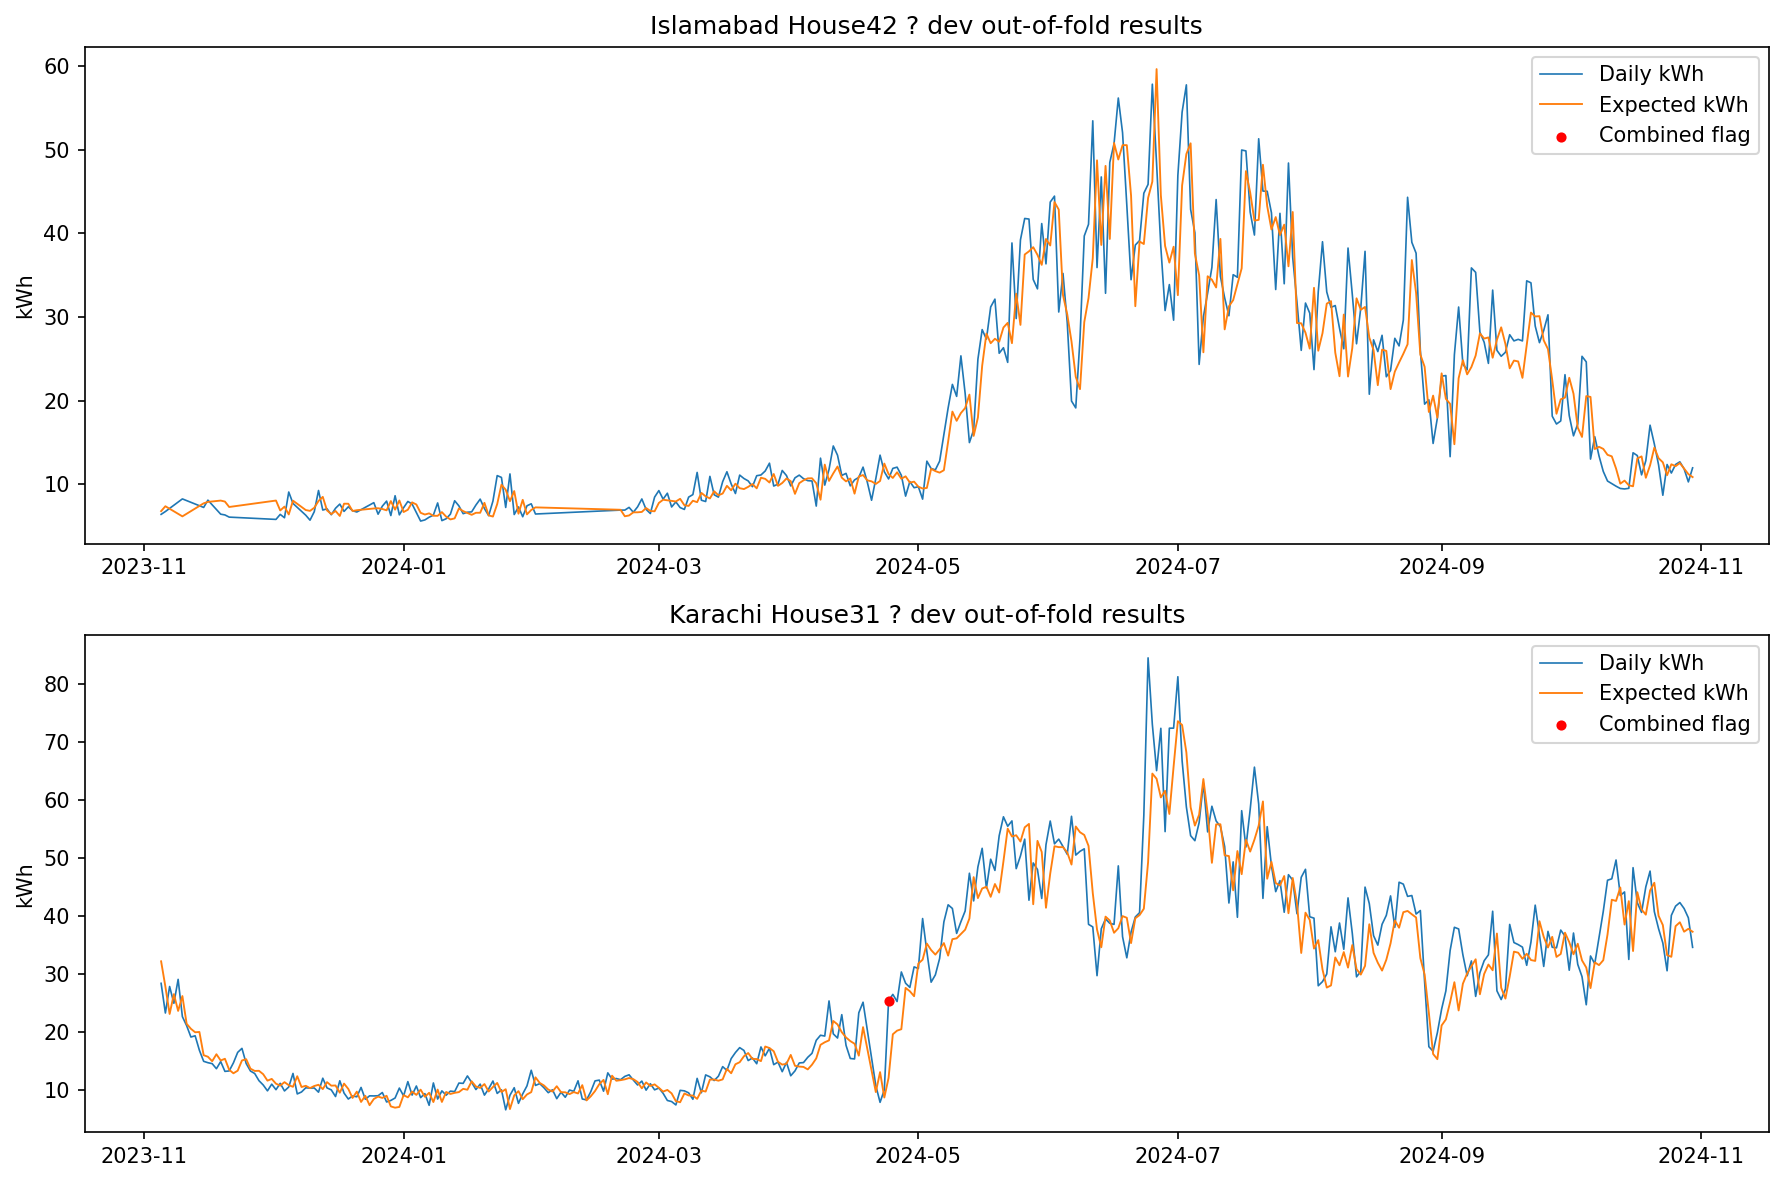

anomaly_residual_hist.png


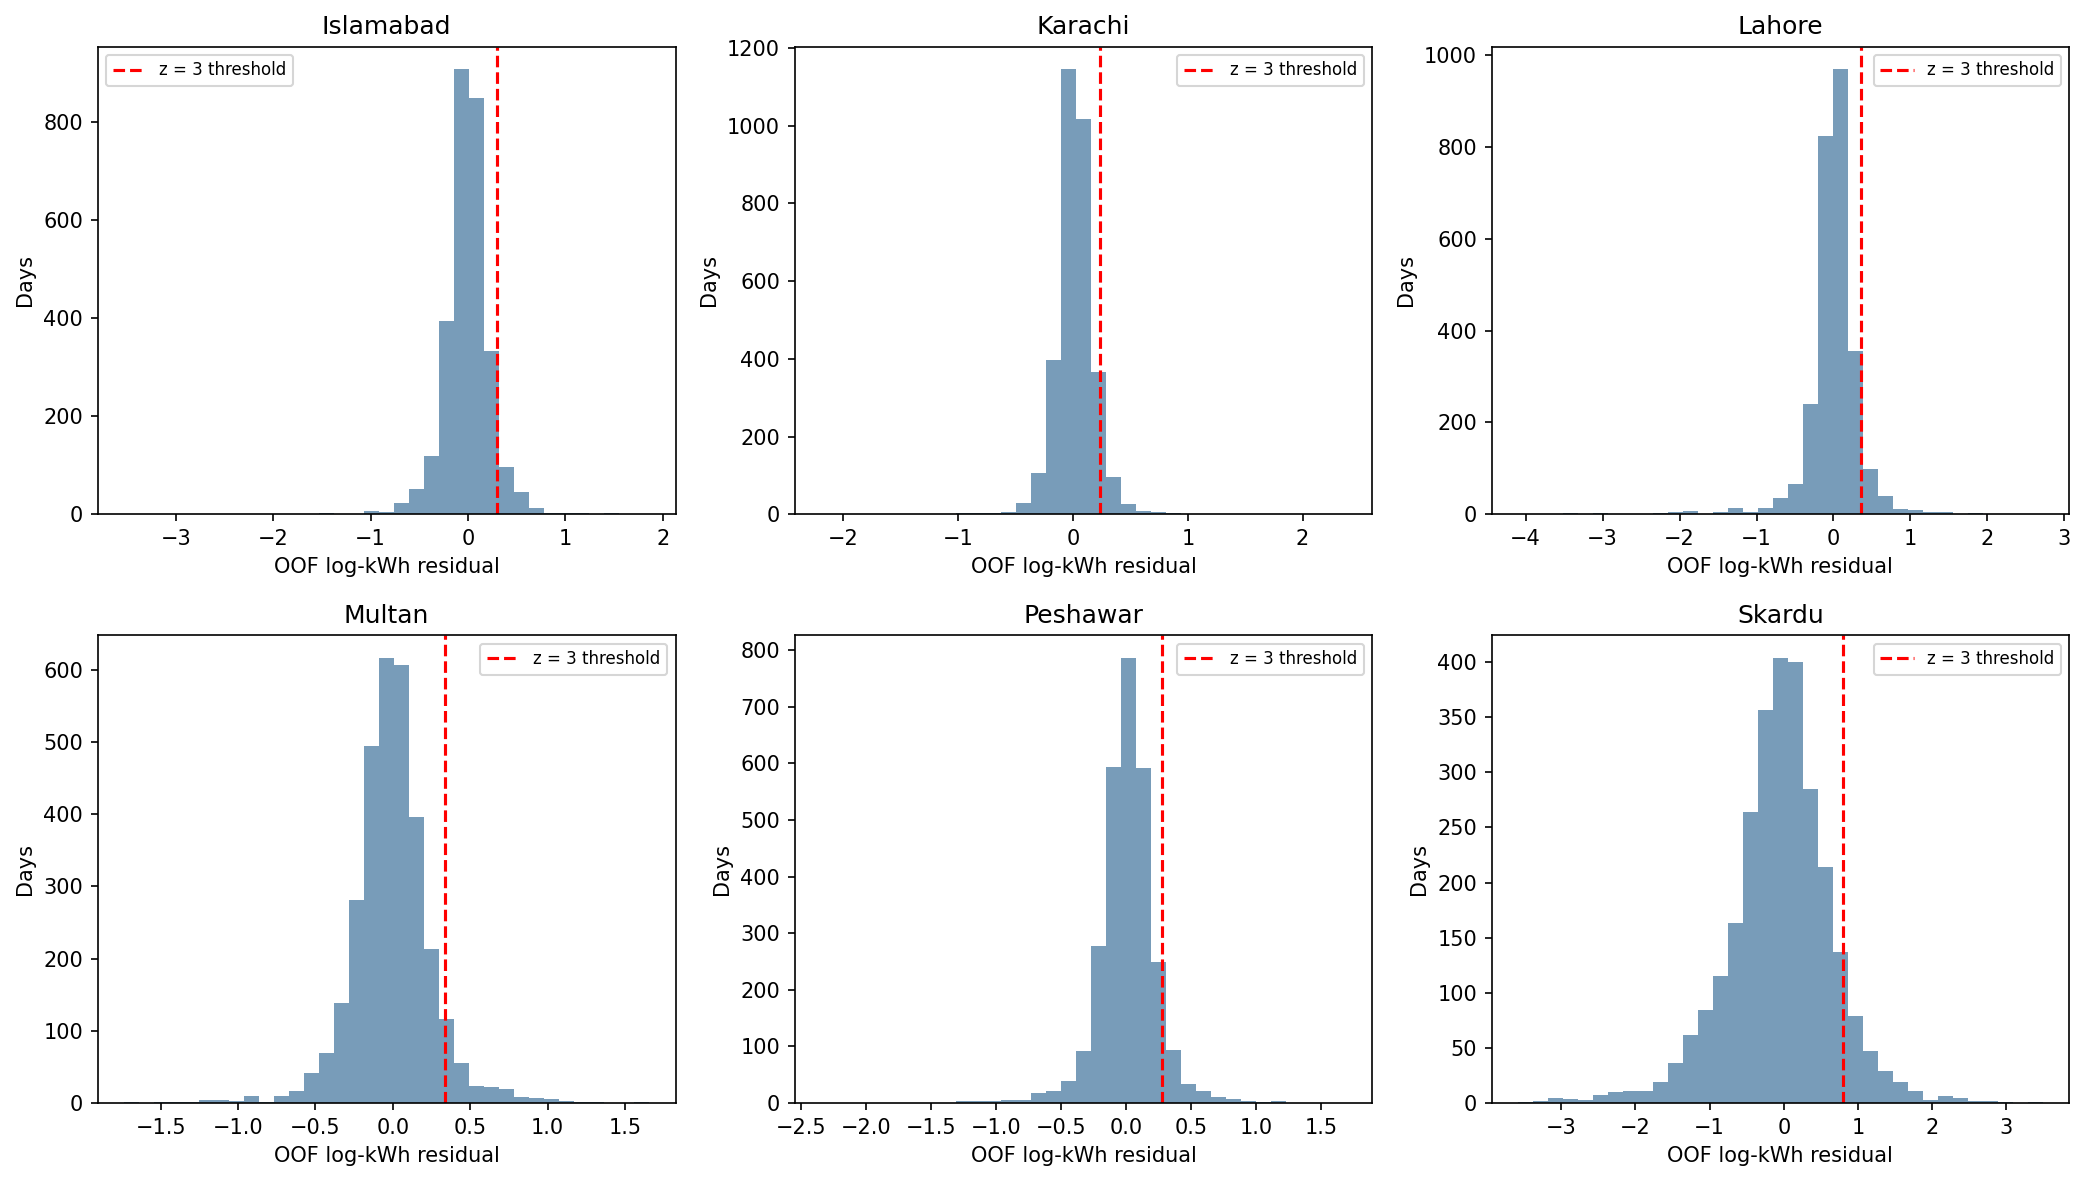

In [18]:
def run_waste_anomaly_analysis():
    """Run synthetic dev-only CV, unlabeled OOF summaries, and app final fit."""
    import joblib
    import matplotlib.pyplot as plt
    from sklearn.ensemble import IsolationForest
    from sklearn.model_selection import GroupKFold
    from sklearn.impute import SimpleImputer

    report_dir = Path(REPORT_DIRS["anomaly"])
    figures_dir = report_dir / "figures"
    report_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    daily_dev, dev_house_keys, holdout_house_keys = load_dev_daily_for_anomalies()
    if set(map(tuple, daily_dev[["city", "house_id"]].drop_duplicates().to_numpy())) & holdout_house_keys:
        raise AssertionError("Holdout houses cannot be analyzed in Stage 10")
    base_features = build_daily_anomaly_features(daily_dev)
    if base_features.empty:
        raise ValueError("No dev days have complete past-only anomaly features")
    if set(base_features["role"]) != {"dev"}:
        raise AssertionError("Non-dev rows reached Stage 10 anomaly analysis")
    if set(map(tuple, base_features[["city", "house_id"]].drop_duplicates().to_numpy())) & holdout_house_keys:
        raise AssertionError("Holdout house leaked into feature-complete daily rows")

    synthetic_records = []
    splitter = GroupKFold(n_splits=5)
    groups = base_features["house_id"].to_numpy(dtype=int)
    for fold, (train_idx, test_idx) in enumerate(
            splitter.split(base_features, groups=groups)):
        train = base_features.iloc[train_idx].copy()
        test = base_features.iloc[test_idx].copy()
        train_houses = set(train["house_id"].astype(int))
        test_houses = set(test["house_id"].astype(int))
        if train_houses & test_houses:
            raise AssertionError("A house appears in both train and test for anomaly CV")
        if set(map(tuple, train[["city", "house_id"]].drop_duplicates().to_numpy())) & holdout_house_keys:
            raise AssertionError("Holdout house entered an anomaly training fold")
        if set(map(tuple, test[["city", "house_id"]].drop_duplicates().to_numpy())) & holdout_house_keys:
            raise AssertionError("Holdout house entered an anomaly validation fold")
        rng = np.random.default_rng(RANDOM_SEED + fold)
        candidates = test.loc[test["outage_min"].lt(240), "_row_id"].to_numpy(dtype=np.int64)
        injection_count = min(len(candidates), max(1, int(round(0.05 * len(candidates))))) if len(candidates) else 0
        injected_ids = rng.choice(candidates, size=injection_count, replace=False) if injection_count else np.array([], dtype=np.int64)
        factors = rng.choice(np.array([1.25, 1.5, 2.0]), size=injection_count, replace=True) if injection_count else np.array([], dtype=float)
        injection_map = dict(zip(injected_ids.tolist(), factors.tolist()))
        injected_features = build_daily_anomaly_features(daily_dev, injection_map)
        injected_lookup = injected_features.set_index("_row_id")
        test = injected_lookup.loc[test["_row_id"].to_numpy()].reset_index()
        train_model = fit_expected_forest(train)
        train_expected_log = train_model.predict(train[ANOMALY_EXPECTED_FEATURES])
        train_residual = np.log1p(train["kwh"].to_numpy(dtype=float)) - train_expected_log
        test_expected_log = train_model.predict(test[ANOMALY_EXPECTED_FEATURES])
        test_residual = np.log1p(test["kwh"].to_numpy(dtype=float)) - test_expected_log
        injected_mask = test["_row_id"].isin(injection_map).to_numpy()
        actual_factors = test["_row_id"].map(injection_map).fillna(1.0).to_numpy(dtype=float)
        for contamination in ANOMALY_CONTAMINATIONS:
            stats, base_detector, extra_detector, extra_imputer = fit_fold_detectors(
                train, train_residual, contamination
            )
            flags, z_score = score_fold_detectors(
                test, test_residual, stats, base_detector, extra_detector, extra_imputer
            )
            expected_kwh = np.expm1(test_expected_log)
            for i in range(len(test)):
                for detector in ANOMALY_DETECTORS:
                    synthetic_records.append({
                        "fold": fold,
                        "city": test.iloc[i]["city"],
                        "house_id": int(test.iloc[i]["house_id"]),
                        "date": test.iloc[i]["date"],
                        "detector": detector,
                        "contamination": contamination,
                        "flag": bool(flags[detector][i]),
                        "injected": bool(injected_mask[i]),
                        "factor": float(actual_factors[i]) if injected_mask[i] else np.nan,
                    })

    synthetic = pd.DataFrame(synthetic_records)
    if synthetic.empty or not synthetic["injected"].any():
        raise ValueError("Synthetic injection evaluation produced no injected dev days")
    metrics_rows, factor_rows, synthetic_city_rows = [], [], []
    for (detector, contamination), subset in synthetic.groupby(
            ["detector", "contamination"], sort=False):
        injected = subset["injected"].to_numpy(dtype=bool)
        flagged = subset["flag"].to_numpy(dtype=bool)
        tp = int(np.sum(flagged & injected))
        fp = int(np.sum(flagged & ~injected))
        fn = int(np.sum(~flagged & injected))
        tn = int(np.sum(~flagged & ~injected))
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        fpr = fp / (fp + tn) if fp + tn else 0.0
        metrics_rows.append({
            "detector": detector, "contamination": float(contamination),
            "precision": precision, "recall": recall, "f1": f1, "fpr": fpr,
        })
        for factor in (1.25, 1.5, 2.0):
            factor_mask = subset["injected"].to_numpy() & np.isclose(subset["factor"].fillna(1).to_numpy(), factor)
            factor_recall = float(subset.loc[factor_mask, "flag"].mean()) if factor_mask.any() else float("nan")
            factor_rows.append({
                "detector": detector, "contamination": float(contamination),
                "factor": factor, "recall": factor_recall,
            })
        for city in CITIES:
            city_rows = subset.loc[subset["city"].eq(city) & subset["injected"]]
            city_recall = float(city_rows["flag"].mean()) if len(city_rows) else float("nan")
            synthetic_city_rows.append({
                "evaluation": "synthetic_recall", "detector": detector,
                "contamination": float(contamination), "city": city,
                "recall": city_recall, "flagged_share": np.nan,
                "median_monthly_excess_share_pct": np.nan,
                "p90_monthly_excess_share_pct": np.nan,
            })
    metrics_table = pd.DataFrame(metrics_rows)
    deployable_candidates = metrics_table.loc[
        metrics_table["detector"].isin(["Isolation Forest", "Combined"])
        & metrics_table["fpr"].le(0.05)
    ]
    if deployable_candidates.empty:
        raise ValueError("No deployable Isolation Forest setting meets the 5% synthetic FPR ceiling")
    selected_operating_point = deployable_candidates.sort_values(
        ["f1", "recall", "fpr"], ascending=[False, False, True]
    ).iloc[0]
    selected_iforest_contamination = float(selected_operating_point["contamination"])
    selected_operating_detector = str(selected_operating_point["detector"])
    factor_table = pd.DataFrame(factor_rows)

    real_records = []
    for train_idx, test_idx in splitter.split(base_features, groups=groups):
        train = base_features.iloc[train_idx].copy()
        test = base_features.iloc[test_idx].copy()
        train_model = fit_expected_forest(train)
        train_residual = np.log1p(train["kwh"].to_numpy(dtype=float)) - train_model.predict(
            train[ANOMALY_EXPECTED_FEATURES]
        )
        expected_log = train_model.predict(test[ANOMALY_EXPECTED_FEATURES])
        residual = np.log1p(test["kwh"].to_numpy(dtype=float)) - expected_log
        stats, base_detector, extra_detector, extra_imputer = fit_fold_detectors(
            train, train_residual, 0.05
        )
        flags, z_score = score_fold_detectors(
            test, residual, stats, base_detector, extra_detector, extra_imputer
        )
        expected_kwh = np.expm1(expected_log)
        for i in range(len(test)):
            real_records.append({
                "city": test.iloc[i]["city"],
                "house_id": int(test.iloc[i]["house_id"]),
                "date": test.iloc[i]["date"],
                "kwh": float(test.iloc[i]["kwh"]),
                "expected_kwh": float(expected_kwh[i]),
                "residual": float(residual[i]),
                "robust_z": float(z_score[i]),
                "z3_residual_threshold": float(
                    stats[test.iloc[i]["city"]][0] + 3 * stats[test.iloc[i]["city"]][1]
                ),
                "temp_mean": float(test.iloc[i]["temp_mean"]),
                "outage_min": float(test.iloc[i]["outage_min"]),
                **{f"flag_{name}": bool(flags[name][i]) for name in ANOMALY_DETECTORS},
            })
    real = pd.DataFrame(real_records)
    if real.empty:
        raise ValueError("The non-injected dev out-of-fold pass produced no records")
    real["year_month"] = real["date"].dt.to_period("M")
    city_real_rows = []
    for detector in ANOMALY_DETECTORS:
        flag_column = f"flag_{detector}"
        for city in CITIES:
            city_data = real.loc[real["city"].eq(city)]
            city_real_rows.append({
                "evaluation": "real_oof_flagged_share", "detector": detector,
                "contamination": 0.05, "city": city, "recall": np.nan,
                "flagged_share": float(city_data[flag_column].mean()) if len(city_data) else np.nan,
                "median_monthly_excess_share_pct": np.nan,
                "p90_monthly_excess_share_pct": np.nan,
            })

    usable_dev = daily_dev.loc[daily_dev["usable"]].copy()
    usable_dev["year_month"] = usable_dev["date"].dt.to_period("M")
    monthly_totals = usable_dev.groupby(["city", "house_id", "year_month"], as_index=False).agg(
        n_usable_days=("kwh", "count"), monthly_kwh=("kwh", "sum")
    )
    monthly_totals = monthly_totals.loc[monthly_totals["n_usable_days"].ge(25)]
    monthly_rows = []
    for detector in ANOMALY_DETECTORS:
        flag_column = f"flag_{detector}"
        excess = real.loc[real[flag_column]].copy()
        excess["excess_kwh"] = excess["kwh"] - excess["expected_kwh"]
        excess = excess.groupby(["city", "house_id", "year_month"], as_index=False)["excess_kwh"].sum()
        house_month = monthly_totals.merge(excess, on=["city", "house_id", "year_month"], how="left")
        house_month["excess_kwh"] = house_month["excess_kwh"].fillna(0.0)
        house_month["monthly_excess_share_pct"] = np.divide(
            house_month["excess_kwh"], house_month["monthly_kwh"],
            out=np.zeros(len(house_month), dtype=float), where=house_month["monthly_kwh"].to_numpy() != 0,
        ) * 100
        for city in CITIES:
            values = house_month.loc[house_month["city"].eq(city), "monthly_excess_share_pct"]
            median = float(values.median()) if len(values) else np.nan
            p90 = float(values.quantile(0.90)) if len(values) else np.nan
            monthly_rows.append({
                "evaluation": "real_monthly_excess_share", "detector": detector,
                "contamination": 0.05, "city": city, "recall": np.nan,
                "flagged_share": np.nan,
                "median_monthly_excess_share_pct": median,
                "p90_monthly_excess_share_pct": p90,
            })

    top_days = real.loc[
        real["flag_Statistical threshold"] & real["robust_z"].gt(3)
    ].sort_values("robust_z", ascending=False).head(10).copy()
    top_days = top_days.rename(columns={"house_id": "house", "kwh": "actual_kwh"})
    top_days["excess_kwh"] = top_days["actual_kwh"] - top_days["expected_kwh"]
    top_days = top_days[["city", "house", "date", "actual_kwh", "expected_kwh",
                         "excess_kwh", "temp_mean", "robust_z"]].reset_index(drop=True)
    by_city_table = pd.DataFrame(synthetic_city_rows + city_real_rows + monthly_rows)

    # Refit the app artifacts on all feature-complete dev rows; no holdout scoring occurs.
    expected_model = fit_expected_forest(base_features)
    final_residual = np.log1p(base_features["kwh"].to_numpy(dtype=float)) - expected_model.predict(
        base_features[ANOMALY_EXPECTED_FEATURES]
    )
    final_city_mad = city_residual_statistics(final_residual, base_features["city"].to_numpy())
    final_if_x, _ = make_iforest_features(base_features, final_residual)
    final_iforest = IsolationForest(
        n_estimators=200, contamination=selected_iforest_contamination, random_state=RANDOM_SEED
    ).fit(final_if_x)
    model_path = MODELS_DIR / "waste_detector.joblib"
    joblib.dump({
        "expected_model": expected_model,
        "expected_features": list(ANOMALY_EXPECTED_FEATURES),
        "iforest": final_iforest,
        "if_features": list(ANOMALY_IF_FEATURES),
        "city_mad": final_city_mad,
        "z_threshold": 3,
        "contamination": selected_iforest_contamination,
        "selected_detector": selected_operating_detector,
        "cities": list(CITIES),
    }, model_path)

    metrics_table.to_csv(report_dir / "anomaly_metrics.csv", index=False)
    factor_table.to_csv(report_dir / "anomaly_recall_by_factor.csv", index=False)
    by_city_table.to_csv(report_dir / "anomaly_by_city.csv", index=False)
    top_days.to_csv(report_dir / "anomaly_top_days.csv", index=False)

    example_keys = []
    for city in CITIES:
        houses = sorted(real.loc[real["city"].eq(city), "house_id"].unique())
        if houses:
            example_keys.append((city, int(houses[0])))
        if len(example_keys) == 2:
            break
    fig, axes = plt.subplots(len(example_keys), 1, figsize=(12, 4 * len(example_keys)), squeeze=False)
    for ax, (city, house_id) in zip(axes[:, 0], example_keys):
        sample = real.loc[real["city"].eq(city) & real["house_id"].eq(house_id)].sort_values("date")
        ax.plot(sample["date"], sample["kwh"], label="Daily kWh", linewidth=0.8)
        ax.plot(sample["date"], sample["expected_kwh"], label="Expected kWh", linewidth=0.9)
        flagged = sample.loc[sample["flag_Combined"]]
        ax.scatter(flagged["date"], flagged["kwh"], color="red", s=15, label="Combined flag", zorder=3)
        ax.set_title(f"{city} House{house_id} ? dev out-of-fold results")
        ax.set_ylabel("kWh")
        ax.legend()
    fig.tight_layout()
    example_figure = figures_dir / "anomaly_example.png"
    fig.savefig(example_figure, dpi=150, bbox_inches="tight")
    plt.close(fig)

    fig, axes = plt.subplots(2, 3, figsize=(14, 8), squeeze=False)
    for ax, city in zip(axes.ravel(), CITIES):
        city_rows = real.loc[real["city"].eq(city)]
        ax.hist(city_rows["residual"], bins=35, color="#5684a8", alpha=0.8)
        threshold = city_rows["z3_residual_threshold"].median()
        if np.isfinite(threshold):
            ax.axvline(threshold, color="red", linestyle="--", label="z = 3 threshold")
            ax.legend(fontsize=8)
        ax.set_title(city)
        ax.set_xlabel("OOF log-kWh residual")
        ax.set_ylabel("Days")
    fig.tight_layout()
    hist_figure = figures_dir / "anomaly_residual_hist.png"
    fig.savefig(hist_figure, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print("All precision/recall/F1/FPR values below use synthetic injections, not real labels.")
    print(
        f"Selected deployable operating point under 5% synthetic FPR: {selected_operating_detector}, "
        f"contamination={selected_iforest_contamination:.2f}, "
        f"F1={selected_operating_point['f1']:.3f}, FPR={selected_operating_point['fpr']:.3f}."
    )
    print(f"Dev houses: {len(dev_house_keys)}; holdout houses excluded: {len(holdout_house_keys)}")
    print("Synthetic injection metrics:")
    print(metrics_table.round(4).to_string(index=False))
    print("Recall by injection factor:")
    print(factor_table.round(4).to_string(index=False))
    print("Dev real-data monthly excess share by city (%):")
    monthly_city = by_city_table.loc[by_city_table["evaluation"].eq("real_monthly_excess_share")]
    print(monthly_city[["detector", "city", "median_monthly_excess_share_pct",
                        "p90_monthly_excess_share_pct"]].round(4).to_string(index=False))
    print("Top real dev OOF days by robust z:")
    print(top_days.round(4).to_string(index=False))
    print("Saved outputs:")
    output_paths = [report_dir / name for name in (
        "anomaly_metrics.csv", "anomaly_recall_by_factor.csv", "anomaly_by_city.csv",
        "anomaly_top_days.csv",
    )] + [example_figure, hist_figure, model_path]
    for output_path in output_paths:
        print(f"  {output_path}")
    return {
        "metrics": metrics_table,
        "factor_recall": factor_table,
        "by_city": by_city_table,
        "monthly_city": monthly_city,
        "top_days": top_days,
        "real_oof": real,
        "figures": [example_figure, hist_figure],
        "outputs": output_paths,
    }


def display_anomaly_tables(results):
    """Display requested anomaly summary tables compactly."""
    for key, label in (("metrics", "Synthetic-injection detector metrics"),
                       ("factor_recall", "Recall by synthetic injection factor"),
                       ("by_city", "Synthetic recall and real dev city summaries"),
                       ("top_days", "Top dev OOF robust-z days")):
        print(label)
        display(results[key].round(4))
    for path in results["figures"]:
        print(Path(path).name)
        show_img(path)


if RUN_HEAVY:
    anomaly_results = run_waste_anomaly_analysis()
else:
    anomaly_dir = Path(REPORT_DIRS["anomaly"])
    anomaly_results = {
        "metrics": pd.read_csv(anomaly_dir / "anomaly_metrics.csv"),
        "factor_recall": pd.read_csv(anomaly_dir / "anomaly_recall_by_factor.csv"),
        "by_city": pd.read_csv(anomaly_dir / "anomaly_by_city.csv"),
        "top_days": pd.read_csv(anomaly_dir / "anomaly_top_days.csv"),
        "figures": [anomaly_dir / "figures" / "anomaly_example.png",
                    anomaly_dir / "figures" / "anomaly_residual_hist.png"],
    }
display_anomaly_tables(anomaly_results)


### Isolation Forest operating-point selection

Stage 10 evaluates contamination values 0.02, 0.05, and 0.10 for residual-only and extra-daily-feature Isolation Forests, plus the statistical/Isolation-Forest intersection. The selection below maximizes synthetic-injection F1 subject to a 5% false-positive-rate ceiling. Non-injected dev days are only a proxy for normal operation; these scores cannot distinguish true structural waste from legitimate heavy use without real labels.

In [19]:
def select_iforest_operating_point(metrics, max_false_positive_rate=0.05):
    """Select the best synthetic-validation F1 under an explicit FPR ceiling."""
    candidates = metrics.loc[metrics["detector"].isin([
        "Isolation Forest", "Combined",
    ])].copy()
    eligible = candidates.loc[candidates["fpr"].le(max_false_positive_rate)]
    if eligible.empty:
        raise ValueError(f"No Isolation Forest configuration meets FPR <= {max_false_positive_rate:.1%}")
    return eligible.sort_values(["f1", "recall", "fpr"], ascending=[False, False, True]).iloc[0]


selected_iforest_config = select_iforest_operating_point(anomaly_results["metrics"])
print("Selected synthetic-validation operating point (FPR <= 5%; proxy, not real labels):")
display(selected_iforest_config.to_frame("value"))

# Compare the offline extra-daily feature set separately; it is not required by the app UI.
feature_set_comparison = anomaly_results["metrics"].loc[
    anomaly_results["metrics"]["detector"].isin([
        "Isolation Forest", "Isolation Forest + daily features",
    ])
].sort_values(["f1", "recall"], ascending=[False, False])
print("Isolation Forest feature-set sensitivity (synthetic labels; daily-feature variant is offline-only):")
display(feature_set_comparison)

Selected synthetic-validation operating point (FPR <= 5%; proxy, not real labels):


,value
detector,Combined
contamination,0.1
precision,0.345102
recall,0.450461
f1,0.390805
fpr,0.044175


Isolation Forest feature-set sensitivity (synthetic labels; daily-feature variant is offline-only):


,detector,contamination,precision,recall,f1,fpr
9,Isolation Forest,0.10,0.265306,0.494240,0.345272,0.070727
11,Isolation Forest + daily features,0.10,0.253840,0.361751,0.298337,0.054950
5,Isolation Forest,0.05,0.273769,0.275346,0.274555,0.037745
7,Isolation Forest + daily features,0.05,0.194915,0.105991,0.137313,0.022623
1,Isolation Forest,0.02,0.218107,0.061060,0.095410,0.011312
3,Isolation Forest + daily features,0.02,0.102362,0.014977,0.026131,0.006787


### Stage 10 summary

- **Done:** loaded synthetic-injection metrics, factor/city tables, top dev OOF days and anomaly figures; heavy CV is opt-in.
- **Key numbers:** statistical threshold: precision 29.2%, recall 53.8%, FPR 6.7%. At 5% contamination, statistical F1 (37.9%) exceeds Isolation Forest (27.5%) and combined (29.0%); extra daily features lower IF F1 to 13.7%. The selected deployable point is Combined at 10% contamination (F1 39.1%, recall 45.0%, FPR 4.4%), meeting the 5% synthetic-FPR ceiling. Statistical recall is 22.8% at 1.25x and 84.3% at 2x.
- **Decision:** treat flags as advisory; the evaluation has synthetic labels only. Combined monthly excess median is 0% in five cities and 7.68% in Skardu.
- **Issues and limitations:** these unlabeled monthly excess shares are descriptive, not verified waste prevalence; the extra daily-feature detector is offline-only.
- **Tuning update:** the notebook reports an Isolation Forest operating point chosen from contamination/feature sweeps under an explicit 5% synthetic-validation FPR ceiling; this is not ground-truth waste validation.

## Stage 11: Final evaluation (holdout + LOCO)

### Purpose and method

- Consolidate the saved one-time holdout, per-house, pooled GroupKFold, and pooled/per-city LOCO results.
- Answer RQ1-RQ3 from saved model, anomaly, ablation, and monthly-excess outputs, distinguishing measured evidence from limitations.

Overall and per-house final holdout results:


,setting,evaluation,model,scope,RMSE,MAE,R2,MAPE,n
0,cold-start,FinalHoldout,Ridge,overall,219.508486,171.201834,0.463095,94.367979,64
1,cold-start,FinalHoldout,Ridge,Islamabad House41,281.885468,229.534787,-1.700502,39.842906,9
2,cold-start,FinalHoldout,Ridge,Karachi House38,258.286624,167.076885,0.537812,37.616428,11
3,cold-start,FinalHoldout,Ridge,Lahore House4,158.927123,126.460386,0.708480,25.463361,12
4,cold-start,FinalHoldout,Ridge,Multan House15,284.892578,251.925229,-7.214822,87.746827,11
5,cold-start,FinalHoldout,Ridge,Peshawar House24,162.365852,144.660454,-0.485853,45.991496,12
6,cold-start,FinalHoldout,Ridge,Skardu House59,116.695378,114.292328,-29.475421,382.723378,9
7,cold-start,FinalHoldout,CityMonthMean,overall,286.584245,229.593039,0.084835,192.576920,64
8,cold-start,FinalHoldout,CityMonthMean,Islamabad House41,245.924399,211.045245,-1.055429,38.921011,9
9,cold-start,FinalHoldout,CityMonthMean,Karachi House38,290.235711,158.801233,0.416399,43.377173,11


Pooled dev GroupKFold results:


,setting,evaluation,model,scope,RMSE,MAE,R2,MAPE
0,cold-start,GroupKFold,Ridge,pooled,425.411473,281.407502,0.184331,2746.760084
7,cold-start,GroupKFold,RandomForest,pooled,429.154403,286.986811,0.169915,2443.359881
14,cold-start,GroupKFold,LightGBM,pooled,430.863083,288.616041,0.163291,2372.176273
21,cold-start,GroupKFold,XGBoost,pooled,430.971558,288.501499,0.162870,2368.942167
28,cold-start,GroupKFold,CityMonthMean,pooled,435.365673,307.377901,0.145713,3147.785196
70,known-house,GroupKFold,Ridge,pooled,613.836826,239.967306,-0.612652,2669.300036
77,known-house,GroupKFold,RandomForest,pooled,232.466525,142.803221,0.768711,1027.906957
84,known-house,GroupKFold,LightGBM,pooled,242.178985,151.703311,0.748980,928.380349
91,known-house,GroupKFold,XGBoost,pooled,234.616729,142.352887,0.764412,549.791325
98,known-house,GroupKFold,CityMonthMean,pooled,452.096244,323.468458,0.125224,8470.898376


Pooled dev LOCO results:


,setting,evaluation,model,scope,RMSE,MAE,R2,MAPE
65,cold-start,LOCO,Ridge,pooled,415.434284,270.754214,0.222142,4394.318573
66,cold-start,LOCO,RandomForest,pooled,420.968906,281.481676,0.201278,5625.853798
67,cold-start,LOCO,LightGBM,pooled,424.477678,286.297118,0.187908,5622.110242
68,cold-start,LOCO,XGBoost,pooled,423.447520,290.438489,0.191845,5502.424641
69,cold-start,LOCO,CityMonthMean,pooled,434.597074,317.300767,0.148726,9264.904982
148,known-house,LOCO,Ridge,pooled,855.213385,273.049209,-2.130285,4753.579175
149,known-house,LOCO,RandomForest,pooled,236.285874,149.284425,0.761048,2075.236922
150,known-house,LOCO,LightGBM,pooled,238.557556,151.478829,0.756431,2568.085308
151,known-house,LOCO,XGBoost,pooled,236.195677,149.859180,0.761231,1900.024487
152,known-house,LOCO,CityMonthMean,pooled,448.197275,331.319032,0.140248,11169.992205


Per-city LOCO results:


,setting,evaluation,model,scope,RMSE,MAE,R2,MAPE
35,cold-start,LOCO,Ridge,Islamabad,376.762718,268.652031,0.025925,85.949666
36,cold-start,LOCO,RandomForest,Islamabad,370.217600,280.987053,0.059474,100.936355
37,cold-start,LOCO,LightGBM,Islamabad,380.847453,284.374381,0.004689,92.792560
38,cold-start,LOCO,XGBoost,Islamabad,374.012324,282.954820,0.040094,99.559093
39,cold-start,LOCO,CityMonthMean,Islamabad,408.927701,329.047490,-0.147492,161.873665
...,...,...,...,...,...,...,...,...
143,known-house,LOCO,RandomForest,Skardu,210.498872,107.015527,0.738341,13781.966126
144,known-house,LOCO,LightGBM,Skardu,214.657348,110.667068,0.727901,17084.881830
145,known-house,LOCO,XGBoost,Skardu,223.685991,110.890429,0.704530,12598.286641
146,known-house,LOCO,CityMonthMean,Skardu,511.533767,441.271831,-0.545200,74588.561685


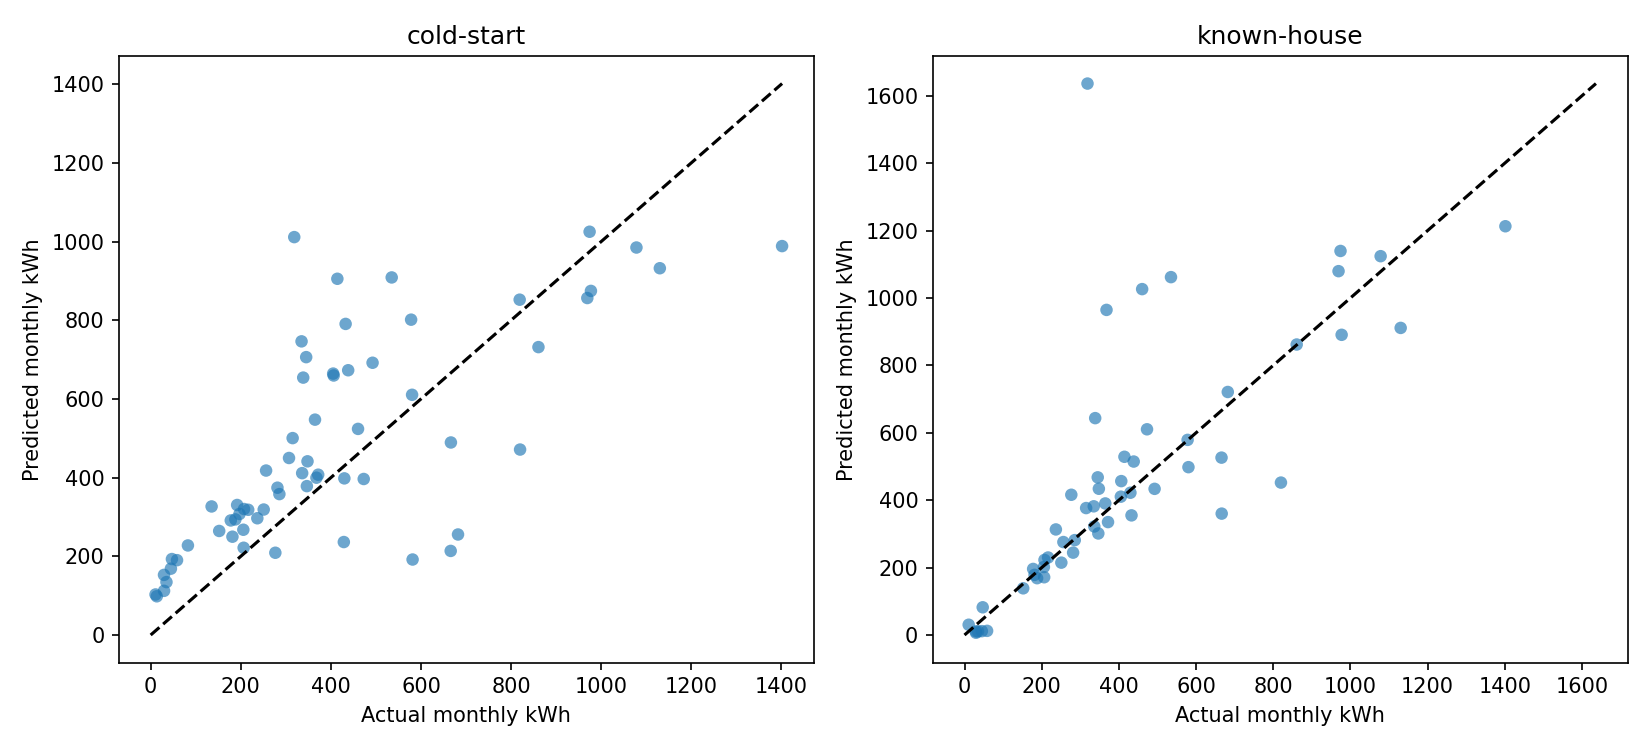

Research-question answers:


,question,evidence,verdict
0,RQ1 prediction accuracy,Holdout MAE: cold-start Ridge 171.20 kWh; know...,Partly answered: six held-out houses only.
1,RQ2 waste detection,"Synthetic stat threshold: precision 0.292, rec...","Partly answered: synthetic injections, no veri..."
2,RQ3 features and excess,Matched dev RF history RMSE change -206.10 kWh...,Partly answered: excess is not a ground-truth ...


Combined-detector median and p90 monthly excess share per city (dev OOF, descriptive):


,city,median_monthly_excess_share_pct,p90_monthly_excess_share_pct
0,Islamabad,0.000000,4.488925
1,Karachi,0.000000,1.466016
2,Lahore,0.000000,6.607904
3,Multan,0.000000,6.886576
4,Peshawar,0.000000,4.369182
5,Skardu,7.684564,34.983142


In [20]:
# Read saved metrics; no holdout refit or scoring occurs in this stage.
dev_results = pd.read_csv(REPORT_DIRS["modeling"] / "results_dev.csv")
holdout_results = pd.read_csv(REPORT_DIRS["modeling"] / "results_holdout.csv")
print("Overall and per-house final holdout results:")
display(holdout_results)
print("Pooled dev GroupKFold results:")
display(dev_results.loc[dev_results.evaluation.eq("GroupKFold") & dev_results.scope.eq("pooled")])
print("Pooled dev LOCO results:")
display(dev_results.loc[dev_results.evaluation.eq("LOCO") & dev_results.scope.eq("pooled")])
print("Per-city LOCO results:")
display(dev_results.loc[dev_results.evaluation.eq("LOCO") & ~dev_results.scope.eq("pooled")])
show_img(REPORT_DIRS["modeling"] / "figures" / "holdout_pred_vs_actual.png")

# Build RQ evidence directly from exported evaluation artifacts.
anomaly_metrics = pd.read_csv(REPORT_DIRS["anomaly"] / "anomaly_metrics.csv")
stat = anomaly_metrics.loc[anomaly_metrics.detector.eq("Statistical threshold") & anomaly_metrics.contamination.eq(.05)].iloc[0]
combined = anomaly_metrics.loc[anomaly_metrics.detector.eq("Combined") & anomaly_metrics.contamination.eq(.10)].iloc[0]
groups = pd.read_csv(REPORT_DIRS["ablation"] / "ablation_groups.csv")
rf_history = groups.loc[groups.setting.eq("B_known-house") & groups.model.eq("RandomForest") & groups.ablation.eq("add history (matched known-house rows)")].iloc[0]
city_excess = pd.read_csv(REPORT_DIRS["anomaly"] / "anomaly_by_city.csv")
city_excess = city_excess.loc[city_excess.evaluation.eq("real_monthly_excess_share") & city_excess.detector.eq("Combined")]
hold = holdout_results.loc[holdout_results.scope.eq("overall")]
cold_mae = hold.loc[hold.setting.eq("cold-start") & hold.model.eq("Ridge"), "MAE"].iloc[0]
known_mae = hold.loc[hold.setting.eq("known-house") & hold.model.eq("RandomForest"), "MAE"].iloc[0]
rq_answers = pd.DataFrame([
    {"question": "RQ1 prediction accuracy", "evidence": f"Holdout MAE: cold-start Ridge {cold_mae:.2f} kWh; known-house RF {known_mae:.2f} kWh.", "verdict": "Partly answered: six held-out houses only."},
    {"question": "RQ2 waste detection", "evidence": f"Synthetic stat threshold: precision {stat.precision:.3f}, recall {stat.recall:.3f}, FPR {stat.fpr:.3f}; combined F1 at contamination .10 is {combined.f1:.3f}.", "verdict": "Partly answered: synthetic injections, no verified real labels."},
    {"question": "RQ3 features and excess", "evidence": f"Matched dev RF history RMSE change {rf_history.RMSE_change_mean:.2f} kWh; combined monthly excess median ranges {city_excess.median_monthly_excess_share_pct.min():.2f}%–{city_excess.median_monthly_excess_share_pct.max():.2f}% across cities.", "verdict": "Partly answered: excess is not a ground-truth waste label."},
])
print("Research-question answers:")
display(rq_answers)
print("Combined-detector median and p90 monthly excess share per city (dev OOF, descriptive):")
display(city_excess[["city", "median_monthly_excess_share_pct", "p90_monthly_excess_share_pct"]].reset_index(drop=True))

### Limitations and threats to validity

- The meter history covers roughly one year (the saved daily date range is about 16 months), limiting multi-year and long-horizon claims.
- Only six houses were held out, one per city, and the final holdout is evaluated once.
- Cleaning thresholds were chosen after looking at all houses, which may create selection optimism.
- Waste detection was validated only on synthetic injections; no verified real-waste labels are available.
- Solar houses' usage is gross rather than net consumption; tariff information came from secondary sources, not an official NEPRA verification.
- LightGBM is excluded from ablation after its native Windows Python 3.13 crash, although its saved Stage 7 metrics are shown.

### Stage 11 summary

- **Done:** displayed overall/per-house holdout results, baselines, pooled GroupKFold, pooled/per-city LOCO, holdout plot and RQ evidence.
- **Key numbers:** cold-start Ridge holdout MAE is 171.20 kWh; known-house RF is 121.21 kWh (n=55). Persistence MAE is 135.10 kWh.
- **Decision:** characterize all RQs as partly answered given the small holdout and synthetic-only waste labels.
- **Issues and limitations:** see the preceding threats-to-validity cell; prediction-level exports are not available for additional row-level analysis.

## Stage 12: Streamlit app and deployment

### Purpose and method

- Describe the app's bill-prediction, known-house/cold-start model choice, tiered tariff estimates, and statistical high-use waste check.
- Demonstrate the tariff function copied from the read-only app, without starting Streamlit.
- Show the project requirements and expected repository/model layout for deployment.

**App workflow**

- **Bill prediction inputs:** city, month, optional previous-month units, sanctioned load, protected-status selection, and optional temperature. The cold-start Ridge is used without history; known-house Random Forest is used when last month's units are supplied.
- **Bill outputs:** predicted kWh with a typical-error band, estimated energy/fixed/total charges, tariff slab, units to the next slab, 5/10/20% savings, and a bill-versus-units chart.
- **Waste check inputs/outputs:** city, date, today's kWh, up to seven previous daily values (at least four valid), outage minutes, and temperature; the tab shows expected kWh, excess, robust z-score and an advisory high-side flag. Days with outages of at least 240 minutes are not flagged.
- **About tab:** dataset, cold-start/known-house holdout MAE, one-year/high-consumption/solar/Skardu limitations, tariff-source caveat

,units_kWh,protected_selected,status_applied,energy_Rs,fixed_Rs,total_Rs,slab
0,100,True,Protected,1054.0,600.0,1654.0,Up to 100 kWh
1,100,False,Unprotected,2244.0,825.0,3069.0,Up to 100 kWh
2,150,True,Protected,1704.5,900.0,2604.5,Up to 200 kWh
3,150,False,Unprotected,4336.5,900.0,5236.5,Up to 200 kWh
4,200,True,Protected,2355.0,900.0,3255.0,Up to 200 kWh
5,200,False,Unprotected,5782.0,900.0,6682.0,Up to 200 kWh
6,201,True,Unprotected,6653.1,1050.0,7703.1,Up to 300 kWh
7,201,False,Unprotected,6653.1,1050.0,7703.1,Up to 300 kWh
8,250,True,Unprotected,8275.0,1050.0,9325.0,Up to 300 kWh
9,250,False,Unprotected,8275.0,1050.0,9325.0,Up to 300 kWh


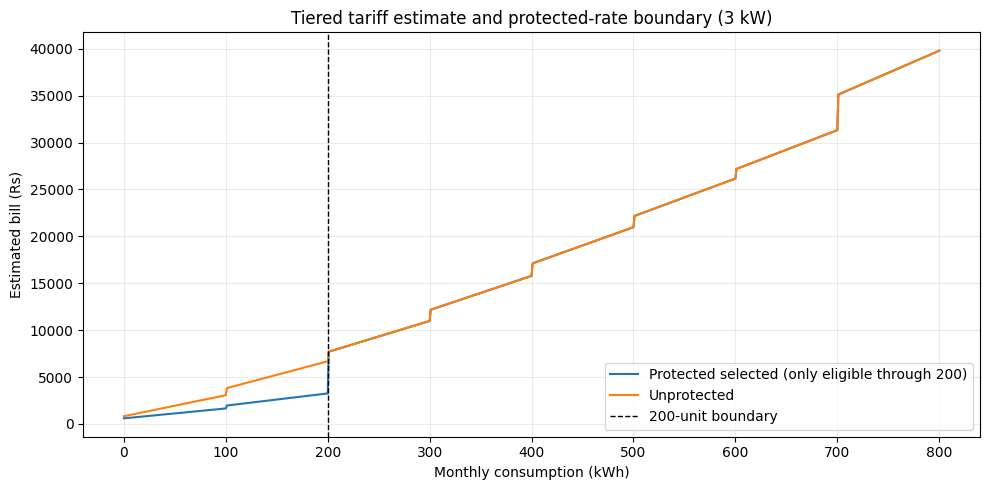

Run locally: python -m streamlit run app/streamlit_app.py
Existing requirements.txt contents:


,package
0,pandas
1,numpy
2,scikit-learn
3,xgboost
4,lightgbm
5,shap
6,matplotlib
7,seaborn
8,streamlit
9,joblib


Deployment files:


,path,purpose
0,app/streamlit_app.py,Streamlit UI and feature/tariff logic
1,app/assets/,tariff and monthly/daily weather climatologies
2,models/best_coldstart.joblib,cold-start monthly model
3,models/best_knownhouse.joblib,known-house monthly model
4,models/waste_detector.joblib,expected-use model and waste calibration
5,requirements.txt,project dependencies


In [21]:
def bill(
    units: float,
    protected: bool,
    sanctioned_kw: float,
    tariff: Mapping[str, Any],
) -> tuple[float, float, float, str, str]:
    """Return energy charge, fixed charge, total, reached slab, and status."""
    units = max(0.0, float(units))
    sanctioned_kw = max(0.0, float(sanctioned_kw))
    protected_applies = bool(protected and units <= 200)

    if protected_applies:
        slabs = tariff["protected"]
        first, second = slabs[0], slabs[1]
        energy = min(units, float(first["up_to"])) * float(first["rate"])
        energy += max(units - float(first["up_to"]), 0.0) * float(second["rate"])
        reached = first if units <= float(first["up_to"]) else second
        status = "Protected"
    else:
        slabs = tariff["unprotected"]
        reached = next(
            (slab for slab in slabs if units <= float(slab["up_to"])),
            slabs[-1],
        )
        energy = units * float(reached["rate"])
        status = "Unprotected"

    fixed = float(reached["fixed_per_kw"]) * sanctioned_kw
    label = f"Up to {int(reached['up_to'])} kWh"
    return energy, fixed, energy + fixed, label, status

tariff_path = PROJECT_ROOT / "app" / "assets" / "tariff.json"
tariff = json.loads(tariff_path.read_text(encoding="utf-8"))
units_to_show = [100, 150, 200, 201, 250, 400, 700, 800]
bill_rows = []
for units in units_to_show:
    for protected in (True, False):
        energy, fixed, total, slab, status = bill(units, protected, 3.0, tariff)
        bill_rows.append({"units_kWh": units, "protected_selected": protected,
                          "status_applied": status, "energy_Rs": energy,
                          "fixed_Rs": fixed, "total_Rs": total, "slab": slab})
bill_demo = pd.DataFrame(bill_rows)
display(bill_demo)

# Plot both rate paths and make the 200-unit protected eligibility boundary visible.
usage = np.arange(0, 801)
protected_bill = [bill(float(x), True, 3.0, tariff)[2] for x in usage]
unprotected_bill = [bill(float(x), False, 3.0, tariff)[2] for x in usage]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(usage, protected_bill, label="Protected selected (only eligible through 200)")
ax.plot(usage, unprotected_bill, label="Unprotected")
ax.axvline(200, color="black", linestyle="--", linewidth=1, label="200-unit boundary")
ax.set(xlabel="Monthly consumption (kWh)", ylabel="Estimated bill (Rs)",
       title="Tiered tariff estimate and protected-rate boundary (3 kW)")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); plt.show(); plt.close(fig)

print("Run locally: python -m streamlit run app/streamlit_app.py")
requirements_path = PROJECT_ROOT / "requirements.txt"
requirements = [line.strip() for line in requirements_path.read_text(encoding="utf-8").splitlines()
                if line.strip() and not line.lstrip().startswith("#")]
print("Existing requirements.txt contents:")
display(pd.DataFrame({"package": requirements}))
print("Deployment files:")
display(pd.DataFrame([
    {"path": "app/streamlit_app.py", "purpose": "Streamlit UI and feature/tariff logic"},
    {"path": "app/assets/", "purpose": "tariff and monthly/daily weather climatologies"},
    {"path": "models/best_coldstart.joblib", "purpose": "cold-start monthly model"},
    {"path": "models/best_knownhouse.joblib", "purpose": "known-house monthly model"},
    {"path": "models/waste_detector.joblib", "purpose": "expected-use model and waste calibration"},
    {"path": "requirements.txt", "purpose": "project dependencies"},
]))

### Streamlit Community Cloud deployment checklist

- Commit `app/streamlit_app.py`, `app/assets/{tariff.json,climatology_monthly.csv,climatology_daily.csv}`, the three required `.joblib` models, and the existing root `requirements.txt`.
- Confirm repository size and joblib/scikit-learn version compatibility; alternatively, use an authenticated artifact store for the model files.
- Set the entry point to `app/streamlit_app.py` and test cold-start, known-house, tariff-boundary and waste-check flows after deployment.
- The current `requirements.txt` is reused; this notebook does not create or edit it. No server is launched here.

### Stage 12 summary

- **Done:** documented the app inputs/outputs and models, demonstrated the app tariff function, and listed deployment files and run command.
- **Key numbers:** at 200 kWh and 3 kW, protected tariff total is Rs 3,255; at 201 kWh, selected protection no longer applies and the unprotected total is Rs 7,703.10.
- **Decision:** label outputs estimates; make the tariff editable and disclose exclusions and secondary sourcing.
- **Issues and limitations:** estimates exclude GST, fuel adjustment and other surcharges; tariff terms were not checked against the official NEPRA document.

# Conclusions

- REWDP meter data paired with city weather supports a useful staged study, but household variation and data quality remain substantial.
- Known-house Random Forest achieved holdout MAE 121.21 kWh versus 171.20 kWh for cold-start Ridge; its RMSE is 244.64 versus 219.51 kWh, reflecting some large errors.
- Previous-month usage materially improved dev RF RMSE on matched known-house rows; Ridge with history was unstable in these saved CV results.
- Statistical detection recovered about 54% of synthetic injections at about 29% precision; this does not establish real-world waste accuracy.
- The app presents bill estimates and an advisory alert, not an official bill or verified waste finding.

# Future work

- Collect a longer, broader household panel and preserve time-forward test windows.
- Validate against utility bills and verified household waste events; calibrate city-specific alert costs and thresholds.
- Revisit solar metering semantics, timestamp alignment, and tariff rates against official NEPRA documentation.
- Add prediction intervals, drift monitoring, and versioned datasets/models with a locked environment.
- Re-test LightGBM in a supported native environment before future ablation use.

In [22]:
# Print the active runtime versions for reproducibility; do not import LightGBM here.
version_table = pd.DataFrame([
    {"component": "Python", "version": platform.python_version()},
    {"component": "NumPy", "version": np.__version__},
    {"component": "pandas", "version": pd.__version__},
    {"component": "scikit-learn", "version": importlib.metadata.version("scikit-learn")},
    {"component": "XGBoost", "version": importlib.metadata.version("xgboost")},
])
display(version_table)

,component,version
0,Python,3.13.14
1,NumPy,2.2.6
2,pandas,2.3.3
3,scikit-learn,1.7.2
4,XGBoost,3.4.1


# Reproducibility

- Run Stages 1-12 in order. The notebook locates `src/config.py` from the project root or `notebooks/` and uses project configuration for data/report/model paths.
- The single `RUN_HEAVY = False` flag reuses saved outputs for minute cleaning, dataset building, model training, ablation, and anomaly detection. Set it to `True` only to intentionally recompute; heavy stages can be slow and may require compatible native libraries.
- Project seed: `RANDOM_SEED = 42`. Split/model/injection procedures use that seed plus repeat/fold offsets where specified; grouped validation keeps each house wholly within a fold.
- The saved holdout export contains aggregate metrics but no prediction rows; MAPE is retained as originally reported.
- Python, NumPy, pandas, scikit-learn, and XGBoost versions are printed in the preceding table at execution time.